# Litmus: detecting persuasion techniques in meme text
**COSC2779 Deep Learning, Assignment 2 (Sequence Modelling)** · Student: s4271512

The tool reads the text extracted from a meme and returns
**(A)** the set of persuasion techniques it uses (20-way multi-label classification) and
**(B)** where each technique sits in the text (multi-label span tagging).
**(C)** then answers the curriculum committee's four questions with experiments.

**How to read this notebook.** Every design decision is made at the point where the evidence for it appears.
Each experiment states its *hypothesis and the decision it feeds* **before** it runs, so it is clear what
result would have changed our mind. All numbers are produced by this notebook (`Restart & Run All`),
except the zero-shot LLM responses for C2, which were collected outside it as the specification allows,
are embedded here, and are parsed and scored here.

| Section | Content |
|---|---|
| 0 | Setup, reproducibility, data |
| 1 | Understanding the data and where it came from |
| 2 | Evaluation framework: metrics, splits, baselines |
| 3 | Model: shared encoder with two self-built heads |
| 4 | Experiments E1–E8: encoder, adaptation strategy, architecture, head, loss, hyper-parameters, thresholds, robustness |
| 5 | Final model on the held-out test set, error analysis, explainability |
| 6 | Part C: C1 bias, C2 zero-shot comparison, C3 head agreement, C4 Australian deployment |
| 7 | Ultimate judgement, limitations, declarations |

## 0. Setup
A fixed seed is set for Python, NumPy and PyTorch, and cuDNN is put into deterministic mode. GPU kernels can
still introduce tiny non-determinism; for that reason every model comparison below is made across five folds
rather than on a single run, so conclusions never hinge on one lucky seed.

In [1]:
import os, sys, json, re, math, time, random, copy, hashlib, itertools, collections, subprocess, gc
os.environ.setdefault("HF_HUB_DISABLE_SYMLINKS_WARNING", "1")
os.environ.setdefault("HF_HUB_DISABLE_PROGRESS_BARS", "1")
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
import warnings
warnings.filterwarnings("ignore", category=UserWarning, module="tqdm")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from transformers import AutoTokenizer, AutoModel, get_linear_schedule_with_warmup
from transformers.utils import logging as hf_logging
from sklearn.metrics import f1_score, precision_score, recall_score

hf_logging.set_verbosity_error(); hf_logging.disable_progress_bar()
pd.set_option("display.max_colwidth", 120)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

SEED = 42


def seed_everything(seed: int = SEED) -> None:
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


seed_everything()
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
# Local smoke-test switch (tiny encoder, 2 folds, 1 epoch). Always False for the submitted run.
FAST_DEV_RUN = os.environ.get("A2_FAST", "0") == "1"
print("torch", torch.__version__, "| device:", DEVICE,
      torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "", "| FAST_DEV_RUN:", FAST_DEV_RUN)

torch 2.11.0+cu128 | device: cuda Tesla T4 | FAST_DEV_RUN: False


### Data
The assignment subset `data_2026_A2.zip` contains the six official SemEval-2021 Task 6 files for subtasks 1 and 2.
We verified byte-for-byte that they are identical to the public corpus on GitHub. So if the files are not next to
the notebook, they are downloaded from a pinned commit, which keeps the notebook runnable anywhere.
`task1` files hold the label set per meme (Part A) and `task2` files hold the character-offset spans (Part B).

In [2]:
CORPUS_COMMIT = "796b32fa76b7a5814a48d1870d163058e81e4ce1"
CORPUS_URL = f"https://raw.githubusercontent.com/di-dimitrov/SEMEVAL-2021-task6-corpus/{CORPUS_COMMIT}"
SPLIT_FILES = {"train": "training_set", "dev": "dev_set", "test": "test_set"}


def download(url, path, attempts=6):
    """urlretrieve with retries: public mirrors occasionally time out (seen: HTTP 504 from Zenodo)."""
    import urllib.request
    for i in range(attempts):
        try:
            urllib.request.urlretrieve(url, path)
            return
        except Exception as exc:
            if i == attempts - 1:
                raise
            print(f"download failed ({exc}); retrying in {15 * (i + 1)} s")
            time.sleep(15 * (i + 1))


def find_data_dir() -> Path:
    for cand in [Path("data"), Path("Assignment 2/data"), Path("/content/data")]:
        if (cand / "training_set_task2.txt").exists():
            return cand
    target = Path("data"); target.mkdir(exist_ok=True)
    for stem in SPLIT_FILES.values():
        for task in (1, 2):
            download(f"{CORPUS_URL}/data/{stem}_task{task}.txt", target / f"{stem}_task{task}.txt")
    download(f"{CORPUS_URL}/techniques_list_task1-2.txt", target / "techniques_list_task1-2.txt")
    return target


DATA_DIR = find_data_dir()
raw = {split: json.loads((DATA_DIR / f"{stem}_task2.txt").read_text(encoding="utf8"))
       for split, stem in SPLIT_FILES.items()}
raw_t1 = {split: json.loads((DATA_DIR / f"{stem}_task1.txt").read_text(encoding="utf8"))
          for split, stem in SPLIT_FILES.items()}

# The 20 text techniques, in the official order (Transfer and Appeal to (Strong) Emotions are image-only).
TECHNIQUES = [
    "Appeal to authority", "Appeal to fear/prejudice", "Black-and-white Fallacy/Dictatorship",
    "Causal Oversimplification", "Doubt", "Exaggeration/Minimisation", "Flag-waving",
    "Glittering generalities (Virtue)", "Loaded Language", "Misrepresentation of Someone's Position (Straw Man)",
    "Name calling/Labeling", "Obfuscation, Intentional vagueness, Confusion",
    "Presenting Irrelevant Data (Red Herring)", "Reductio ad hitlerum", "Repetition", "Slogans", "Smears",
    "Thought-terminating cliché", "Whataboutism", "Bandwagon",
]
T2I = {t: i for i, t in enumerate(TECHNIQUES)}
K = len(TECHNIQUES)
SHORT = {  # compact names for plots
    "Appeal to authority": "Authority", "Appeal to fear/prejudice": "Fear/prejudice",
    "Black-and-white Fallacy/Dictatorship": "Black&white", "Causal Oversimplification": "Causal oversimpl.",
    "Doubt": "Doubt", "Exaggeration/Minimisation": "Exagg./Minim.", "Flag-waving": "Flag-waving",
    "Glittering generalities (Virtue)": "Glittering gen.", "Loaded Language": "Loaded language",
    "Misrepresentation of Someone's Position (Straw Man)": "Straw man", "Name calling/Labeling": "Name calling",
    "Obfuscation, Intentional vagueness, Confusion": "Obfuscation",
    "Presenting Irrelevant Data (Red Herring)": "Red herring", "Reductio ad hitlerum": "Ad hitlerum",
    "Repetition": "Repetition", "Slogans": "Slogans", "Smears": "Smears",
    "Thought-terminating cliché": "Thought-term.", "Whataboutism": "Whataboutism", "Bandwagon": "Bandwagon",
}


def to_frame(split: str) -> pd.DataFrame:
    rows = []
    for m in raw[split]:
        spans = [(l["start"], l["end"], l["technique"]) for l in m["labels"]]
        y = np.zeros(K, dtype=np.float32)
        for _, _, t in spans:
            y[T2I[t]] = 1
        rows.append({"id": m["id"], "split": split, "text": m["text"], "spans": spans, "y": y})
    return pd.DataFrame(rows)


df_all = pd.concat([to_frame(s) for s in SPLIT_FILES], ignore_index=True)
print(df_all.groupby("split").size().to_dict(), "| unknown techniques:",
      {l["technique"] for s in raw for m in raw[s] for l in m["labels"]} - set(TECHNIQUES))

{'dev': 63, 'test': 200, 'train': 688} | unknown techniques: set()


## 1. Understanding the data and where it came from

**Provenance (Dimitrov et al., 2021, §4 and App. A).** The memes were collected over several months in **2020**
from **26 public Facebook groups**. 23 of them are about **US and Canadian politics** (left, right, centrist,
anti-government, gun control) and 3 are about COVID-19, vaccines and gender equality. All memes are in English.
The text was extracted with Google Vision and corrected by hand. **Six annotators** labelled it, three per meme,
using the text alone, *before* seeing the image. Disagreements were settled by **discussion with a consolidator**,
not by majority vote. Agreement of the three annotators against the consolidated labels had Krippendorff's
α = 0.83, 0.91 and **0.56**, so one annotator diverged substantially from the final consensus.

Three consequences follow. They shape later sections:
1. The gold labels are *one team's negotiated reading* of US/Canadian political memes from 2020. "Correct" means
   agreeing with that team, which matters for C1 (whose reading?) and C4 (Australia, 2026, teenagers).
2. Text labels were assigned without the image, which matches our deployment: we also only get the extracted text.
3. Moderate agreement puts a ceiling on achievable scores. A model cannot reliably beat human consistency.

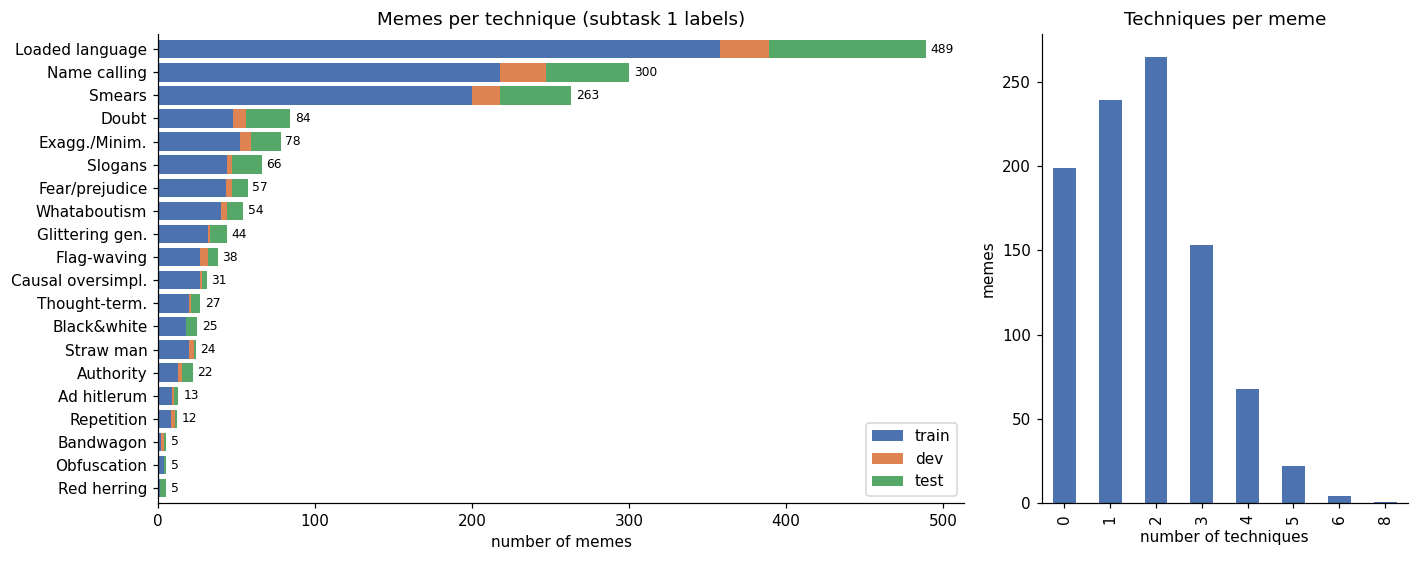

mean techniques/meme = 1.73; memes with none = 199 (21%); train-set counts below 10: ['Obfuscation', 'Red herring', 'Ad hitlerum', 'Repetition', 'Bandwagon']


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.2), gridspec_kw={"width_ratios": [2.2, 1]})
counts = pd.DataFrame({s: np.stack(df_all[df_all.split == s].y).sum(0) for s in SPLIT_FILES},
                      index=[SHORT[t] for t in TECHNIQUES]).astype(int)
counts = counts.loc[counts.sum(axis=1).sort_values().index]
counts.plot.barh(stacked=True, ax=axes[0], color=["#4C72B0", "#DD8452", "#55A868"], width=0.8)
for i, v in enumerate(counts.sum(axis=1)):
    axes[0].text(v + 3, i, str(v), va="center", fontsize=8)
axes[0].set_title("Memes per technique (subtask 1 labels)"); axes[0].set_xlabel("number of memes")
n_labels = df_all.y.apply(lambda y: int(y.sum()))
n_labels.value_counts().sort_index().plot.bar(ax=axes[1], color="#4C72B0")
axes[1].set_title("Techniques per meme"); axes[1].set_xlabel("number of techniques"); axes[1].set_ylabel("memes")
plt.tight_layout(); plt.show()
print(f"mean techniques/meme = {n_labels.mean():.2f}; memes with none = {(n_labels == 0).sum()} "
      f"({(n_labels == 0).mean():.0%}); train-set counts below 10: "
      f"{[SHORT[t] for t in TECHNIQUES if np.stack(df_all[df_all.split=='train'].y).sum(0)[T2I[t]] < 10]}")

**Reading.** The label distribution is extremely long-tailed. Three techniques (Loaded Language, Name calling,
Smears) account for 64% of all labels. Five techniques have fewer than ten training memes, and *Red Herring* has a
single one. Two consequences:
* **Metrics.** Micro-F1, the official metric, is dominated by the head classes, so we also report macro-F1 and
  per-technique F1. A tool that only ever says "Loaded Language" would look acceptable on micro-F1.
* **Expectations.** No method can learn a technique from one to four examples. We expect F1 ≈ 0 on those and plan
  for the tool to say so honestly rather than guess (Section 7).

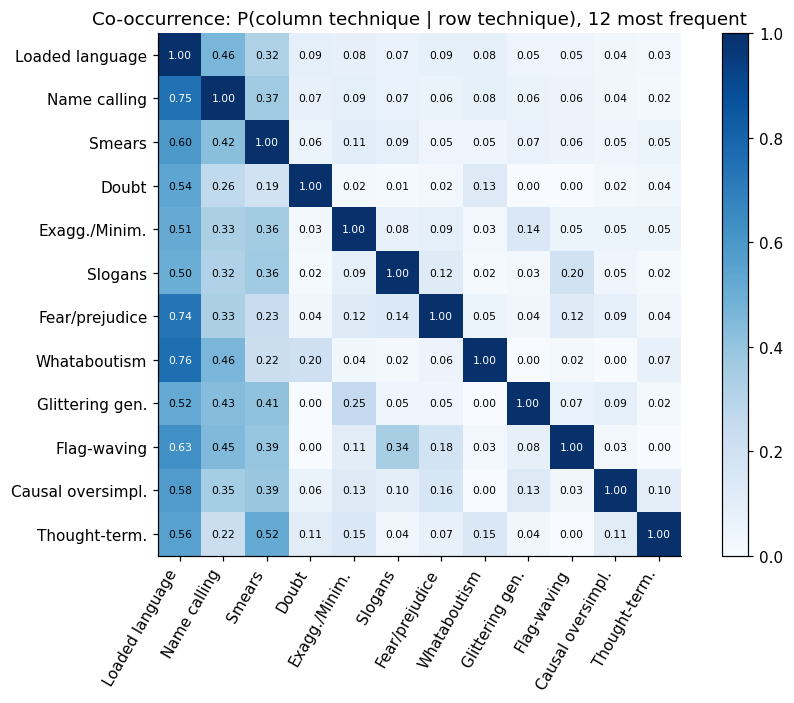

In [4]:
Y_all = np.stack(df_all.y)
co = Y_all.T @ Y_all
cond = co / np.maximum(np.diag(co)[:, None], 1)  # P(column | row)
order = np.argsort(-np.diag(co))[:12]
fig, ax = plt.subplots(figsize=(8.5, 6.5))
im = ax.imshow(cond[np.ix_(order, order)], cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(len(order)), [SHORT[TECHNIQUES[i]] for i in order], rotation=60, ha="right")
ax.set_yticks(range(len(order)), [SHORT[TECHNIQUES[i]] for i in order])
for a, i in enumerate(order):
    for b, j in enumerate(order):
        ax.text(b, a, f"{cond[i, j]:.2f}", ha="center", va="center", fontsize=7,
                color="white" if cond[i, j] > 0.6 else "black")
ax.set_title("Co-occurrence: P(column technique | row technique), 12 most frequent")
plt.colorbar(im, fraction=0.04); plt.tight_layout(); plt.show()

**Reading.** Techniques co-occur strongly. For example, a meme with *Name calling* very often also has
*Loaded Language*, and *Smears* travels with both. The labels are therefore not independent, but the dependence
is soft (conditional probabilities well below 1). That supports **20 independent sigmoid outputs on a shared
representation**: the shared encoder can learn the correlations, and no technique is forced to exclude another
(a softmax would do exactly that).

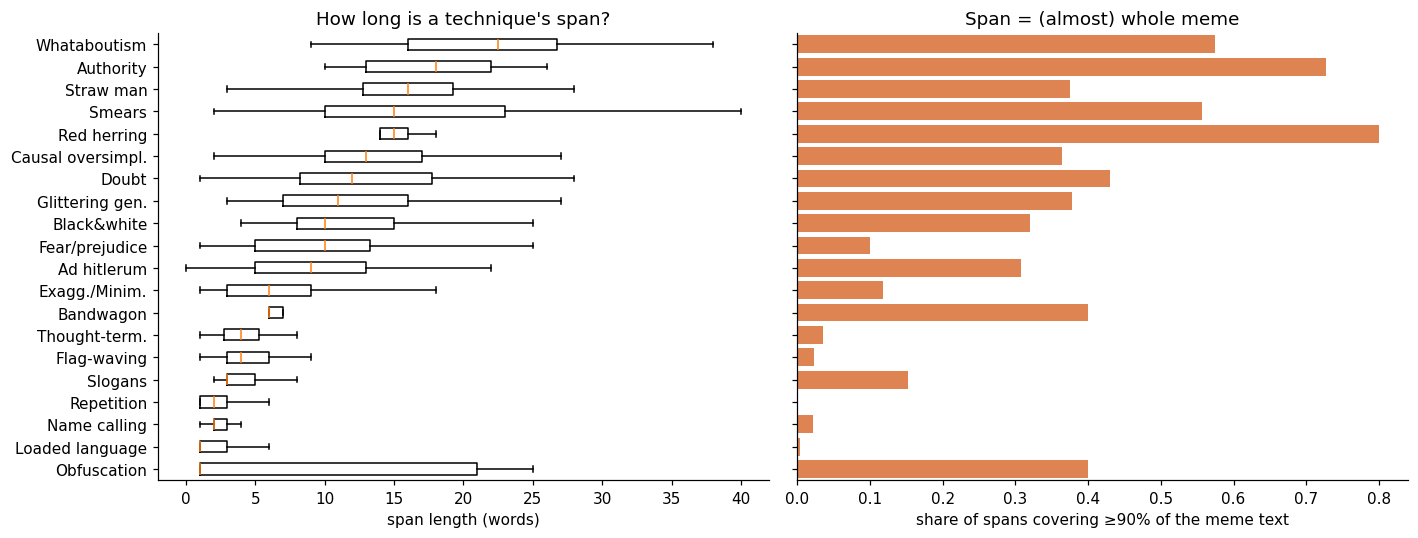

2083 spans; 16% of them cover ≥90% of the meme text


In [5]:
def word_len(s, e, text):
    return len(text[s:e].split())


span_rows = []
for _, r in df_all.iterrows():
    clean_len = max(len(r.text.strip()), 1)
    for s, e, t in r.spans:
        span_rows.append({"technique": SHORT[t], "words": word_len(s, e, r.text),
                          "frac_of_text": (e - s) / clean_len, "split": r.split})
spans_df = pd.DataFrame(span_rows)
stats = spans_df.groupby("technique").agg(spans=("words", "size"), median_words=("words", "median"),
                                          whole_text_share=("frac_of_text", lambda f: (f >= 0.9).mean()))
stats = stats.sort_values("median_words")
fig, ax = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
data = [spans_df[spans_df.technique == t].words.values for t in stats.index]
ax[0].boxplot(data, orientation="horizontal", showfliers=False); ax[0].set_yticks(range(1, len(stats) + 1), stats.index)
ax[0].set_xlabel("span length (words)"); ax[0].set_title("How long is a technique's span?")
ax[1].barh(range(1, len(stats) + 1), stats.whole_text_share, color="#DD8452")
ax[1].set_xlabel("share of spans covering ≥90% of the meme text"); ax[1].set_title("Span = (almost) whole meme")
plt.tight_layout(); plt.show()
print(f"{len(spans_df)} spans; {(spans_df.frac_of_text >= 0.9).mean():.0%} of them cover ≥90% of the meme text")

**Reading.** The techniques split into two kinds:
* **Lexical** techniques (Loaded Language, Name calling, Repetition, Slogans) have spans of 1–4 words. A tagger
  can point at them precisely.
* **Discourse-level** techniques (Whataboutism, Doubt, Causal oversimplification, Smears, Black-and-white) usually
  span most of the meme. "Where is it?" is then answered by "the whole message".

This drives two things. For Part B the evaluation must accept that a span can be the whole text. For C3 we expect
the label head and the span head to agree easily on lexical techniques and to disagree more on discourse-level
ones, which is a hypothesis we can test.

In [6]:
def overlap_stats(df):
    cross, same_overlap, same_adjacent, same_pairs = 0, 0, 0, 0
    for _, r in df.iterrows():
        sp = r.spans
        for i in range(len(sp)):
            for j in range(i + 1, len(sp)):
                if sp[i][0] < sp[j][1] and sp[j][0] < sp[i][1] and sp[i][2] != sp[j][2]:
                    cross += 1
        by = collections.defaultdict(list)
        for s, e, t in sp:
            by[t].append((s, e))
        for v in by.values():
            v.sort()
            for a, b in zip(v, v[1:]):
                same_pairs += 1
                if b[0] < a[1]:
                    same_overlap += 1
                elif re.fullmatch(r"[\s\W]*", r.text[a[1]:b[0]]):
                    same_adjacent += 1
    return cross, same_pairs, same_overlap, same_adjacent


cross, same_pairs, same_ov, same_adj = overlap_stats(df_all)
n_spans = sum(len(s) for s in df_all.spans)
print(f"overlapping span pairs with DIFFERENT techniques: {cross}")
print(f"consecutive spans of the SAME technique in a meme: {same_pairs}; overlapping: {same_ov}; "
      f"separated only by spaces/punctuation: {same_adj} ({(same_ov + same_adj) / n_spans:.1%} of all spans)")

overlapping span pairs with DIFFERENT techniques: 1379
consecutive spans of the SAME technique in a meme: 441; overlapping: 13; separated only by spaces/punctuation: 51 (3.1% of all spans)


**Decision: tagging scheme for Part B.** Spans of *different* techniques overlap all the time. Standard BIO
tagging gives every token a single label, so it cannot represent this. We therefore tag **each technique
independently**: every token gets 20 binary "inside technique *k*?" decisions (IO tagging, one sigmoid per
technique per token).

IO tagging cannot separate two *adjacent* spans of the same technique. Per-technique BIO could, at the cost of
3× the outputs and sparser B tags. The table above shows this case affects only about 3% of spans. The official
scorer also gives partial credit by character overlap: one merged prediction covering two adjacent gold spans
still collects almost all of their recall and precision. IO is therefore the simpler choice and loses almost
nothing. We check this claim numerically once the metric is implemented (Section 2).

In [7]:
dupe_groups = df_all.assign(norm=df_all.text.str.lower().str.replace(r"\W+", " ", regex=True).str.strip()) \
    .groupby("norm").filter(lambda g: len(g) > 1)
show = dupe_groups.assign(labels=dupe_groups.y.apply(lambda y: [SHORT[TECHNIQUES[i]] for i in np.where(y)[0]]))
display(show[["id", "split", "text", "labels"]])
t1_mismatch = sum(set(a["labels"]) != {l["technique"] for l in b["labels"]}
                  for s in SPLIT_FILES for a, b in zip(raw_t1[s], raw[s]))
frag_mismatch = [m["id"] for s in raw for m in raw[s] for l in m["labels"]
                 if m["text"][l["start"]:l["end"]] != l["text_fragment"]]
print("task1 label sets that differ from the techniques present in task2 spans:", t1_mismatch)
print("spans whose stored fragment differs from text[start:end]:", len(frag_mismatch), sorted(set(frag_mismatch)))

,id,split,text,labels
55,93,train,The Real Virus Threatening America\n,[Loaded language]
91,110,train,THE REAL VIRUS THREATENING AMERICA\n,"[Fear/prejudice, Flag-waving]"
436,474_batch_2,train,JOE BIDEN'S LIFETIME ACCOMPLISHMENTS.,[]
466,549_batch_2,train,STILL MORE COHERENT THAN JOE BIDEN\n,[]
504,588_batch_2,train,"HOW TO KILL THE CORONOVIRUS\n\nHey Hillary, I hear the Coronavirus is going to testify against you.","[Loaded language, Smears]"
683,501_batch_2,train,"HOW TO KILL THE CORONOVIRUS...\nHey Hillary, I hear the Coronavirus is going to testify against you.",[Smears]
704,30_batch_2,dev,STILL MORE COHERENT THAN JOE BIDEN,[]
890,474_batch_2,test,JOE BIDEN'S LIFETIME ACCOMPLISHMENTS.,[Slogans]


task1 label sets that differ from the techniques present in task2 spans: 0
spans whose stored fragment differs from text[start:end]: 5 ['500_batch_2', '720_batch_2', '790_batch_2']


**Findings that change the pipeline**
* **Leakage in the official split.** Meme `474_batch_2` ("Joe Biden's lifetime accomplishments.") appears in
  *both* train and test, with different labels (none vs. *Slogans*). We **drop it from the training data**, so the
  test set stays exactly the official one and remains comparable with published results.
* **Label noise.** Identical texts carry different labels. "The real virus threatening America" is *Loaded
  Language* once and *Fear/prejudice + Flag-waving* the other time. The "Hey Hillary, the Coronavirus is going to
  testify against you" meme gains or loses *Loaded Language*. The text was annotated *without* the image, so
  the most plausible explanation is annotator inconsistency. This is a concrete instance of the moderate agreement
  reported in the paper, and it bounds achievable F1. We keep both copies: the noise is part of the task.
* **Labels and spans are consistent:** every task1 label set equals the set of techniques with at least one task2
  span. A meme has technique *k* **if and only if** some part of its text is tagged *k*. This logical link between
  Part A and Part B motivates a joint model (Section 3) and makes the C3 disagreement question well-defined.
* A few stored `text_fragment`s do not match their offsets. We always use the **offsets**, which is what the
  official scorer uses.

In [8]:
LEAK_IDS = set(df_all[df_all.split == "train"].id) & set(df_all[df_all.split == "test"].id)
print("ids in both train and test:", LEAK_IDS)
df_all = df_all[~((df_all.split == "train") & df_all.id.isin(LEAK_IDS))].reset_index(drop=True)
df_dev = df_all[df_all.split.isin(["train", "dev"])].reset_index(drop=True)   # development pool (train + dev)
df_test = df_all[df_all.split == "test"].reset_index(drop=True)               # untouched until Section 5
if FAST_DEV_RUN:  # local smoke test only: tiny subsets
    df_dev = df_dev.sample(150, random_state=SEED).reset_index(drop=True)
    df_test = df_test.sample(60, random_state=SEED).reset_index(drop=True)
print("development pool:", len(df_dev), "| held-out test:", len(df_test))

ids in both train and test: {'474_batch_2'}
development pool: 750 | held-out test: 200


### Style of the text and political composition
Two properties of the text matter later. **Casing:** memes are often set in capitals, which subword tokenisers
split into more, rarer pieces. **Political target:** which side a meme attacks. For the target we use a transparent
keyword heuristic. It is used *only for analysis* (C1, C4), never inside the classifier, as the specification
requires.

In [9]:
LEFT_TERMS = r"\b(biden|obama|hillary|clinton|democrat\w*|dems?|liberal\w*|leftist\w*|libtard\w*|kamala|harris|pelosi|bernie|sanders|aoc|antifa|socialis\w*|communis\w*)\b"
RIGHT_TERMS = r"\b(trump\w*|republican\w*|conservative\w*|maga|gop|pence|right[- ]wing\w*|mcconnell|trumpster\w*)\b"


def political_target(text: str) -> str:
    t = text.lower()
    left, right = bool(re.search(LEFT_TERMS, t)), bool(re.search(RIGHT_TERMS, t))
    return "both" if left and right else "left-figures" if left else "right-figures" if right else "neither"


def upper_ratio(text: str) -> float:
    letters = [c for c in text if c.isalpha()]
    return sum(c.isupper() for c in letters) / max(len(letters), 1)


df_all["target"] = df_all.text.apply(political_target)
df_all["mostly_caps"] = df_all.text.apply(upper_ratio) > 0.7
df_dev["target"] = df_dev.text.apply(political_target); df_test["target"] = df_test.text.apply(political_target)
comp = pd.crosstab(df_all.split, df_all.target)
display(comp)
by_side = df_all[df_all.target.isin(["left-figures", "right-figures"])]
rate = pd.DataFrame({side: np.stack(g.y).mean(0) for side, g in by_side.groupby("target")},
                    index=[SHORT[t] for t in TECHNIQUES])
rate["n"] = 0
rate = rate.loc[rate[["left-figures", "right-figures"]].max(axis=1).sort_values(ascending=False).index[:8]]
display(rate.drop(columns="n").style.format("{:.2f}").set_caption(
    "Share of memes carrying each technique, by which side's figures are named (all splits)"))
print(f"memes mostly in capitals: {df_all.mostly_caps.mean():.0%}")

target,both,left-figures,neither,right-figures
split,,,,
dev,2,8,40,13
test,11,34,130,25
train,32,117,474,64


,left-figures,right-figures
Loaded language,0.48,0.53
Smears,0.50,0.39
Name calling,0.36,0.36
Glittering gen.,0.03,0.15
Slogans,0.09,0.12
Exagg./Minim.,0.09,0.10
Whataboutism,0.04,0.08
Doubt,0.07,0.05


memes mostly in capitals: 49%


**Reading.** Memes naming left-wing figures outnumber memes naming right-wing figures roughly 3:2. Also, about two
thirds of memes name neither side. The *gold* rates of techniques also differ by side. Does this reflect the
memes, or the annotators' reading of them? The data alone cannot separate the two. Either way, a model trained on
it can inherit the asymmetry, which is what C1 tests directly. About half of the memes are written mostly in
capitals, while a teenager's feed in 2026 is mostly mixed case. This is a style shift we test in E8 and C4.

**Summary: data → design**

| Observation | Design consequence |
|---|---|
| 750 development memes, 63 official dev memes | 5-fold cross-validation on train+dev; official test (200) touched once |
| Long tail: 5 techniques < 10 training memes | macro-F1 and per-technique F1 reported; class weighting tested (E5); honest "not supported" list |
| Labels co-occur, but softly | 20 sigmoid outputs on a shared encoder |
| Spans overlap across techniques; same-technique adjacency ≈ 3% | per-technique IO tagging |
| Label ⇔ at least one span (100%) | joint model; label/span consistency is measurable (C3) |
| Lexical vs. discourse-level techniques | technique-specific attention in the label head (Section 3) |
| Leak `474_batch_2`; duplicated texts with conflicting labels | leak removed from training; noise acknowledged as ceiling |
| Half the memes in capitals; US politics 2020 | casing robustness (E8); C1 and C4 |

## 2. Evaluation framework

### 2.1 What we measure, and why
**Part A (labels).**
* **Micro-F1** is the official SemEval metric. Using it makes us comparable with the 2021 leaderboard
  (best .593, majority baseline .374).
* **Macro-F1** weights the 20 techniques equally. Didactically a missed *Straw man* matters as much as a missed
  *Loaded Language*, and macro-F1 exposes a model that ignores the tail.
* **Per-technique F1** tells the teacher *which* labels to trust.

Precision and recall are reported separately. In a classroom a false accusation ("this meme smears someone") is
more damaging than a missed technique, so we look at the precision side explicitly.

**Part B (spans).** We use the official SemEval-2021 subtask-2 measure. It gives partial credit for character
overlap, and credit counts only when the technique matches. With predicted spans $p$ and gold spans $g$ of the
same technique,
$P=\frac{1}{|\text{pred}|}\sum_{p}\sum_{g}\frac{|p\cap g|}{|p|}$ and
$R=\frac{1}{|\text{gold}|}\sum_{g}\sum_{p}\frac{|p\cap g|}{|g|}$. F1 is their harmonic mean.
We re-implement it in a few lines so it can run inside the training loop. Below we **verify it against the
official scorer** on the same inputs.

In [10]:
def label_scores(Y_true: np.ndarray, Y_pred: np.ndarray) -> dict:
    return {
        "micro_f1": f1_score(Y_true, Y_pred, average="micro", zero_division=0),
        "macro_f1": f1_score(Y_true, Y_pred, average="macro", zero_division=0),
        "micro_p": precision_score(Y_true, Y_pred, average="micro", zero_division=0),
        "micro_r": recall_score(Y_true, Y_pred, average="micro", zero_division=0),
    }


def per_technique_f1(Y_true, Y_pred) -> pd.Series:
    return pd.Series(f1_score(Y_true, Y_pred, average=None, zero_division=0, labels=range(K)),
                     index=[SHORT[t] for t in TECHNIQUES])


def span_scores(gold: list, pred: list) -> dict:
    """Official SemEval-2021 subtask-2 measure. gold/pred: per meme a list of (start, end, technique)."""
    p_num = r_num = 0.0
    n_pred = sum(len(p) for p in pred); n_gold = sum(len(g) for g in gold)
    for g_spans, p_spans in zip(gold, pred):
        for ps, pe, pt in p_spans:
            for gs, ge, gt in g_spans:
                if pt == gt:
                    inter = max(0, min(pe, ge) - max(ps, gs))
                    p_num += inter / (pe - ps)
                    r_num += inter / (ge - gs)
    p = p_num / n_pred if n_pred else 0.0
    r = r_num / n_gold if n_gold else 0.0
    f1 = 1.0 if n_pred == 0 and n_gold == 0 else (2 * p * r / (p + r) if p > 0 and r > 0 else 0.0)
    return {"span_f1": f1, "span_p": p, "span_r": r}

### 2.2 Tokenisation and span ↔ token alignment
The gold spans are character offsets, and transformers see sub-word tokens. A token is labelled *inside
technique k* if any of its (whitespace-trimmed) characters fall inside a gold span of *k*. To decode, each
maximal run of tokens above the threshold for *k* becomes one predicted span, from the first token's first
character to the last token's last character. Some tokenisers (e.g. DeBERTa) include the leading space in a
token's offsets, so offsets are trimmed first.

In [11]:
MAX_LEN = 160  # longest meme is 142 RoBERTa tokens


def trimmed_offsets(text, offsets):
    out = []
    for a, b in offsets:
        while a < b and text[a].isspace():
            a += 1
        while b > a and text[b - 1].isspace():
            b -= 1
        out.append((a, b))
    return out


def token_labels(text, offsets, spans):
    """offsets already trimmed; returns (T, K) float array, special tokens (a == b) all-zero."""
    lab = np.zeros((len(offsets), K), dtype=np.float32)
    for i, (a, b) in enumerate(offsets):
        if a == b:
            continue
        for s, e, t in spans:
            if a < e and s < b:
                lab[i, T2I[t]] = 1
    return lab


def decode_spans(offsets, probs, thr, text=None):
    """probs: (T, K) token probabilities; thr: scalar or (K,) thresholds -> list of (start, end, technique).
    If the text is given, spans without any letter or digit (a lone '.' or '!') are dropped: nothing to point at."""
    thr = np.broadcast_to(np.asarray(thr, dtype=np.float32), (K,))
    spans = []
    for k in range(K):
        start = end = None
        for (a, b), p in zip(offsets, probs[:, k]):
            if a == b:          # special / padding token
                continue
            if p > thr[k]:
                start = a if start is None else start
                end = b
            elif start is not None:
                spans.append((start, end, TECHNIQUES[k])); start = None
        if start is not None:
            spans.append((start, end, TECHNIQUES[k]))
    if text is not None:
        spans = [sp for sp in spans if any(c.isalnum() for c in text[sp[0]:sp[1]])]
    return spans


def tokenize_frame(df, tok):
    enc = tok(list(df.text), truncation=True, max_length=MAX_LEN, return_offsets_mapping=True)
    offs = [trimmed_offsets(t, o) for t, o in zip(df.text, enc["offset_mapping"])]
    labs = [token_labels(t, o, s) for t, o, s in zip(df.text, offs, df.spans)]
    return {"input_ids": enc["input_ids"], "offsets": offs, "token_labels": labs}

**Two checks before trusting any number.**
1. *Representation ceiling.* Convert every gold span to token IO tags with the RoBERTa tokeniser, decode back,
   and score against the original spans. This is the best Part-B score any IO tagger could reach. It quantifies
   what the IO decision from Section 1 costs.
2. *Metric correctness.* Score the same predictions with our implementation and with the official scorer
   (`propaganda-techniques-scorer`, the commit pinned by the SemEval repository).

In [12]:
TOK_CHECK = AutoTokenizer.from_pretrained("roberta-base")
enc_dev = tokenize_frame(df_dev, TOK_CHECK)
roundtrip = [decode_spans(o, l, 0.5) for o, l in zip(enc_dev["offsets"], enc_dev["token_labels"])]
print("IO representation ceiling on the development pool:",
      {k: round(v, 4) for k, v in span_scores(list(df_dev.spans), roundtrip).items()})


def official_span_score(gold_df, pred_spans):
    """Runs the official SemEval-2021 task-2 scorer; returns F1 or None if it cannot be fetched."""
    repo = Path("propaganda-techniques-scorer")
    try:
        if not repo.exists():
            subprocess.run(["git", "clone", "-q", "https://gitlab.com/joedsm/propaganda-techniques-scorer.git",
                            str(repo)], check=True, timeout=120)
            subprocess.run(["git", "-C", str(repo), "checkout", "-q", "05fe8d38c4a729dfea749e401456ef35b8476cf4"],
                           check=True)
        to_json = lambda spans_list: [{"id": i, "labels": [{"start": s, "end": e, "technique": t} for s, e, t in sp]}
                                      for i, sp in zip(gold_df.id, spans_list)]
        Path("_gold.json").write_text(json.dumps(to_json(list(gold_df.spans))), encoding="utf8")
        Path("_pred.json").write_text(json.dumps(to_json(pred_spans)), encoding="utf8")
        Path("_techniques.txt").write_text("\n".join(TECHNIQUES) + "\n", encoding="utf8")
        out = subprocess.run([sys.executable, "task-2-semeval21_scorer.py", "-s", "../_pred.json", "-r", "../_gold.json",
                              "-p", "../_techniques.txt", "-o"], cwd=repo, capture_output=True, text=True, timeout=300,
                             env={**os.environ, "PYTHONUTF8": "1"})
        return float(out.stdout.strip().split("\t")[0])
    except Exception as exc:  # no network / git: the check is skipped, not faked
        print("official scorer unavailable:", type(exc).__name__, exc)
        return None


# Sanity predictions with partial overlaps: shift every gold span by 3 characters and drop every third one.
perturbed = [[(s + 3, e + 3, t) for j, (s, e, t) in enumerate(sp) if j % 3] for sp in df_dev.spans]
for name, pred in [("IO round-trip", roundtrip), ("shifted+dropped", perturbed)]:
    ours = span_scores(list(df_dev.spans), pred)["span_f1"]
    print(f"{name:16s} ours={ours:.6f} official={official_span_score(df_dev, pred)}")

IO representation ceiling on the development pool: {'span_f1': 1.0002, 'span_p': 1.0015, 'span_r': 0.999}


IO round-trip    ours=1.000212 official=1.000212


shifted+dropped  ours=0.526215 official=0.526215


### 2.3 Data splits
* **Test (200 memes, official split)** is held out and used **once**, in Section 5. Every choice before that
  (encoder, adaptation, head, loss, hyper-parameters, thresholds) is made on the development pool. Otherwise the
  test number would be optimistically biased, which is exactly the "leaky evaluation" that makes a deployment
  claim meaningless.
* The official dev set (63 memes) is too small to select models with. One meme changes micro-F1 by about 1 point,
  and several techniques have zero dev examples. We therefore pool train and dev (750 memes) and use
  **5-fold cross-validation**. Every model comparison is then made on 750 out-of-fold predictions instead of 63,
  and is **paired**: all configurations see identical folds, so we can compare them fold by fold.
* Folds are built with **iterative stratification** (Sechidis et al., 2011). It balances all 20 labels across folds
  at once, so rare techniques appear in every fold where possible. A random split could leave a fold with no
  example of a technique.

The test set is still in-distribution: same Facebook groups, same months, same annotators. The test score
therefore estimates performance *on 2020 US/Canadian Facebook memes*, not on an Australian Year 10 feed. That gap
is measured separately in C4 rather than assumed away.

In [13]:
def iterative_stratification(Y: np.ndarray, n_folds: int, seed: int = SEED) -> np.ndarray:
    """Sechidis et al. (2011): assign examples so every label is spread evenly over folds. Returns fold id per row."""
    rng = np.random.RandomState(seed)
    n = len(Y)
    fold = -np.ones(n, dtype=int)
    desired = np.full(n_folds, n / n_folds)
    desired_label = np.tile(Y.sum(0) / n_folds, (n_folds, 1))
    remaining = np.ones(n, dtype=bool)
    while remaining.any():
        counts = Y[remaining].sum(0)
        if counts.sum() == 0:  # rows without labels: fill folds by remaining capacity
            for i in rng.permutation(np.where(remaining)[0]):
                f = rng.choice(np.flatnonzero(desired == desired.max())); fold[i] = f; desired[f] -= 1
            break
        lab = np.argmin(np.where(counts > 0, counts, np.inf))       # rarest label still unassigned
        for i in rng.permutation(np.where(remaining & (Y[:, lab] == 1))[0]):
            cand = np.flatnonzero(desired_label[:, lab] == desired_label[:, lab].max())
            if len(cand) > 1:
                cand = cand[desired[cand] == desired[cand].max()]
            f = rng.choice(cand)
            fold[i] = f; remaining[i] = False
            desired[f] -= 1; desired_label[f] -= Y[i]
    return fold


N_FOLDS = 2 if FAST_DEV_RUN else 5
Y_dev = np.stack(df_dev.y)
df_dev["fold"] = iterative_stratification(Y_dev, N_FOLDS)
fold_tab = pd.DataFrame({f: Y_dev[df_dev.fold == f].sum(0) for f in range(N_FOLDS)},
                        index=[SHORT[t] for t in TECHNIQUES]).astype(int)
fold_tab.insert(0, "total", Y_dev.sum(0).astype(int))
display(fold_tab.T.style.set_caption("Memes per technique in each fold (iterative stratification)"))

,Authority,Fear/prejudice,Black&white,Causal oversimpl.,Doubt,Exagg./Minim.,Flag-waving,Glittering gen.,Loaded language,Straw man,Name calling,Obfuscation,Red herring,Ad hitlerum,Repetition,Slogans,Smears,Thought-term.,Whataboutism,Bandwagon
total,15,47,18,28,56,59,32,33,389,23,247,4,1,10,11,47,218,21,44,4
0,3,9,4,5,11,11,6,6,78,4,50,1,0,2,2,9,43,4,8,1
1,3,9,4,6,12,12,7,7,78,5,49,1,0,2,3,10,44,4,9,0
2,3,9,3,6,11,12,6,7,78,5,50,1,0,2,2,9,44,4,9,1
3,3,10,3,5,11,12,6,6,77,4,49,0,1,2,2,10,43,4,9,1
4,3,10,4,6,11,12,7,7,78,5,49,1,0,2,2,9,44,5,9,1


### 2.4 Uncertainty
With 200 test memes a difference of a few F1 points can be noise. Test-set numbers therefore get a **95% bootstrap
confidence interval** (1,000 resamples of memes). Model comparisons on the development pool use the **fold-paired
difference** (mean ± standard deviation over the five folds). A configuration is called better only if it wins
consistently, not just on average.

In [14]:
def bootstrap_ci(metric_fn, *arrays, n_boot=1000, seed=SEED):
    rng = np.random.RandomState(seed)
    n = len(arrays[0]); vals = []
    for _ in range(n_boot):
        idx = rng.randint(0, n, n)
        vals.append(metric_fn(*[[a[i] for i in idx] if isinstance(a, list) else a[idx] for a in arrays]))
    return np.percentile(vals, [2.5, 97.5])

### 2.5 Trivial baselines (the floor any model must clear)
* **Majority:** every meme gets *Loaded Language*, and for spans the whole text is tagged as Loaded Language.
* **Prior-random:** each technique is predicted independently with its training frequency (averaged over 50 draws).
  For spans, the whole text gets the sampled techniques.

Both are computed out-of-fold: the frequencies come from the fold's training part only.

In [15]:
def whole_text_spans(text, techs):
    s = len(text) - len(text.lstrip()); e = len(text.rstrip())
    return [(s, e, t) for t in techs] if e > s else []


rng = np.random.RandomState(SEED)
base_rows = []
for f in range(N_FOLDS):
    tr, va = df_dev[df_dev.fold != f], df_dev[df_dev.fold == f]
    Yva = np.stack(va.y); prior = np.stack(tr.y).mean(0)
    maj = np.zeros_like(Yva); maj[:, T2I["Loaded Language"]] = 1
    maj_sp = [whole_text_spans(t, ["Loaded Language"]) for t in va.text]
    base_rows.append({"baseline": "majority", "fold": f, **label_scores(Yva, maj), **span_scores(list(va.spans), maj_sp)})
    for d in range(50):
        rnd = (rng.rand(*Yva.shape) < prior).astype(int)
        rnd_sp = [whole_text_spans(t, [TECHNIQUES[k] for k in np.where(r)[0]]) for t, r in zip(va.text, rnd)]
        base_rows.append({"baseline": "prior-random", "fold": f, **label_scores(Yva, rnd),
                          **span_scores(list(va.spans), rnd_sp)})
baselines = pd.DataFrame(base_rows).groupby("baseline")[["micro_f1", "macro_f1", "micro_p", "micro_r", "span_f1"]].mean()
display(baselines.style.format("{:.3f}").set_caption("Baselines, 5-fold out-of-fold on the development pool"))

,micro_f1,macro_f1,micro_p,micro_r,span_f1
baseline,,,,,
majority,0.378,0.034,0.519,0.298,0.157
prior-random,0.282,0.084,0.283,0.282,0.142


## 3. Model

### 3.1 Architecture
```
  meme text ──► pretrained encoder (frozen / LoRA / fully fine-tuned) ──► contextual token vectors H (T × d)
                                  ┌───────────────────────────────┴───────────────────────────────┐
              [self-built] LABEL HEAD (Part A)                              [self-built] SPAN HEAD (Part B)
   one learned query per technique attends over the tokens            per token: d → 256 → 20 sigmoids
   → 20 technique-specific summaries → 20 sigmoids                    ("is this token inside technique k?")
```
**Why one shared encoder with two heads (multi-task)?**
* Only 750 training memes. Both tasks need the same competence, recognising persuasive language, so sharing the
  encoder lets each task regularise the other (Caruana, 1997). The span loss gives the encoder dense, token-level
  supervision about *which words* carry each label, which the meme-level label alone cannot provide.
* The data showed that a meme has a technique **iff** it has a span for it. One model keeps both outputs in
  one place, and the remaining disagreement can be measured (C3).
* Deployment: one encoder pass serves both outputs, which halves latency and memory on the school T4.

The alternatives (two separate models; deriving labels as "any token tagged") are tested in E3, not assumed away.

**Why technique-specific (label-wise) attention in the label head?** Section 1 showed that lexical techniques
live in 1–3 words while discourse techniques span the whole meme. A single `[CLS]` vector must summarise all of
them at once. Label-wise attention (as in CAML, Mullenbach et al., 2018) gives each technique its own query vector,
so *Name calling* can attend to the insult and *Whataboutism* to the "what about…" clause. A useful side effect:
the attention weights show which words the label head relied on, which feeds the explainability analysis and C3.
We compare it with `[CLS]` and mean pooling in E4.

**The self-built segment** is both heads plus the joint loss below. They are designed, initialised and trained
from scratch, and their variants are tuned in Section 4.

In [16]:
ENCODERS = {
    "roberta-base": {"hf": "roberta-base", "amp": True},
    # RoBERTa further pre-trained (MLM only, no labels) on 2020-2021 tweets: same era and register as the memes.
    "twitter-roberta-2021": {"hf": "cardiffnlp/twitter-roberta-base-2021-124m", "amp": True},
    # Stronger general encoder (disentangled attention). Mixed precision is used; the gradient scaler guards overflow.
    "deberta-v3-base": {"hf": "microsoft/deberta-v3-base", "amp": True},
}
if FAST_DEV_RUN:
    ENCODERS = {k: {"hf": "distilroberta-base", "amp": True} for k in ENCODERS}


class LabelAttentionHead(nn.Module):
    """Label-wise attention: each technique k has a query q_k; logit_k = w_k · sum_t softmax_t(q_k·key_t) h_t + b_k."""

    def __init__(self, d, k, dropout):
        super().__init__()
        self.key = nn.Sequential(nn.Linear(d, d), nn.Tanh())
        self.query = nn.Parameter(torch.randn(k, d) * d ** -0.5)
        self.out_w = nn.Parameter(torch.randn(k, d) * d ** -0.5)
        self.out_b = nn.Parameter(torch.zeros(k))
        self.drop = nn.Dropout(dropout)

    def forward(self, H, mask):
        scores = torch.einsum("btd,kd->bkt", self.key(self.drop(H)), self.query) / math.sqrt(H.size(-1))
        att = scores.masked_fill(~mask[:, None, :], torch.finfo(scores.dtype).min).softmax(-1)
        pooled = torch.einsum("bkt,btd->bkd", att, H)
        return (self.drop(pooled) * self.out_w).sum(-1) + self.out_b, att


class PooledHead(nn.Module):
    """Baseline label heads: [CLS] vector or masked mean of token vectors, then a 2-layer MLP."""

    def __init__(self, d, k, dropout, pooling):
        super().__init__()
        self.pooling = pooling
        self.mlp = nn.Sequential(nn.Dropout(dropout), nn.Linear(d, d), nn.GELU(), nn.Dropout(dropout), nn.Linear(d, k))

    def forward(self, H, mask):
        if self.pooling == "cls":
            v = H[:, 0]
        else:
            m = mask.unsqueeze(-1).to(H.dtype)
            v = (H * m).sum(1) / m.sum(1).clamp(min=1)
        return self.mlp(v), None


class LoRALinear(nn.Module):
    """LoRA (Hu et al., 2022): y = W x + (alpha / r) * B A x, with W frozen and only A (r x d_in), B (d_out x r) trained.
    B starts at zero, so training starts exactly from the pretrained encoder."""

    def __init__(self, base: nn.Linear, r: int, alpha: float, dropout: float = 0.1):
        super().__init__()
        self.base = base
        for p in self.base.parameters():
            p.requires_grad = False
        self.A = nn.Parameter(torch.randn(r, base.in_features) / math.sqrt(base.in_features))
        self.B = nn.Parameter(torch.zeros(base.out_features, r))
        self.scale, self.drop = alpha / r, nn.Dropout(dropout)

    def forward(self, x):
        return self.base(x) + (self.drop(x) @ self.A.t() @ self.B.t()) * self.scale


def add_lora(encoder, r, targets):
    for p in encoder.parameters():
        p.requires_grad = False
    for name, module in list(encoder.named_modules()):
        for child_name, child in list(module.named_children()):
            if child_name in targets and isinstance(child, nn.Linear):
                setattr(module, child_name, LoRALinear(child, r, alpha=2 * r))


class PersuasionModel(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.cfg = cfg
        # .float(): some checkpoints (e.g. DeBERTa-v3) are stored in fp16 and recent transformers keep that dtype.
        self.encoder = AutoModel.from_pretrained(ENCODERS[cfg["encoder"]]["hf"]).float()
        d = self.encoder.config.hidden_size
        if cfg.get("init_encoder") == "ptc":  # encoder after intermediate training on PTC news (E9)
            self.encoder.load_state_dict(PTC_ENCODER_STATE[cfg["encoder"]])
        if cfg["adaptation"] == "frozen":
            for p in self.encoder.parameters():
                p.requires_grad = False
        elif cfg["adaptation"] == "lora":
            add_lora(self.encoder, cfg["lora_r"], targets=("query", "value", "query_proj", "value_proj"))
        head = cfg["label_head"]
        self.label_head = (LabelAttentionHead(d, K, cfg["dropout"]) if head == "label_attention"
                           else PooledHead(d, K, cfg["dropout"], head) if head in ("cls", "mean") else None)
        self.span_head = (nn.Sequential(nn.Dropout(cfg["dropout"]), nn.Linear(d, 256), nn.GELU(),
                                        nn.Dropout(cfg["dropout"]), nn.Linear(256, K))
                          if cfg["span_loss_weight"] > 0 or head == "from_spans" else None)

    def forward(self, input_ids, attention_mask, token_mask):
        H = self.encoder(input_ids=input_ids, attention_mask=attention_mask).last_hidden_state
        span_logits = self.span_head(H) if self.span_head is not None else None
        att = None
        if self.label_head is not None:
            label_logits, att = self.label_head(H, attention_mask.bool())
        else:  # "from_spans": a meme has technique k iff some token is tagged k  ->  max over tokens
            label_logits = span_logits.masked_fill(~token_mask[..., None], -1e4).max(1).values
        return label_logits, span_logits, att

### 3.2 Objective
$\mathcal{L} = \alpha\,\mathcal{L}_{\text{label}} + \lambda\,\mathcal{L}_{\text{span}}$, with α = λ = 1 unless an
ablation switches one task off.
Both terms are binary cross-entropies (multi-label, one sigmoid per technique).
* The **span term** averages over real tokens only (special and padding tokens are masked).
* **Class imbalance** (E5) is handled by one of: plain BCE; BCE with a per-technique positive weight
  $w_k=\sqrt{N_{neg,k}/N_{pos,k}}$ (square root, so a technique with 4 examples does not get a 180× weight that
  destabilises training); or focal loss (Lin et al., 2017), which down-weights easy negatives.

In [17]:
def bce_loss(logits, targets, pos_weight=None, focal_gamma=0.0, mask=None):
    loss = F.binary_cross_entropy_with_logits(logits, targets, pos_weight=pos_weight, reduction="none")
    if focal_gamma > 0:
        p = torch.sigmoid(logits)
        p_t = p * targets + (1 - p) * (1 - targets)
        loss = loss * (1 - p_t) ** focal_gamma
    if mask is not None:
        loss = loss[mask]
    return loss.mean()

### 3.3 Data pipeline and training loop
* **Dynamic padding** per batch: memes are short (median 28 tokens), so padding to 160 would waste ~80% of compute.
* **Optional casing augmentation** (E8): with probability *p* a training meme is shown upper-cased, lower-cased or
  sentence-cased. Changing case does not move character offsets, so the spans stay valid.
* **AdamW**, linear warm-up (10%) and decay, gradient clipping at 1.0, mixed precision on GPU.
  Encoder and heads get separate learning rates: the heads start from random weights and need larger steps.
* **Model selection per fold**: after every epoch we score the validation fold. We keep the epoch with the best
  average of label micro-F1 and span F1 (each at its best threshold on that fold), with early stopping after
  `patience` epochs without improvement. Because this epoch choice uses the validation fold, out-of-fold numbers
  are slightly optimistic. They are used only to *compare* configurations; the unbiased number is the test set.

In [18]:
def recase(text, rng):
    r = rng.rand()
    return text.upper() if r < 1 / 3 else text.lower() if r < 2 / 3 else text[:1].upper() + text[1:].lower()


class MemeDataset(torch.utils.data.Dataset):
    def __init__(self, df, tok, casing_aug=0.0, seed=SEED):
        self.df, self.tok, self.casing_aug = df.reset_index(drop=True), tok, casing_aug
        self.rng = np.random.RandomState(seed)
        self.cache = tokenize_frame(self.df, tok)

    def __len__(self):
        return len(self.df)

    def __getitem__(self, i):
        if self.casing_aug > 0 and self.rng.rand() < self.casing_aug:
            row = self.df.iloc[[i]].copy()
            row["text"] = recase(row.text.iloc[0], self.rng)
            enc = tokenize_frame(row, self.tok)
            ids, offs, lab = enc["input_ids"][0], enc["offsets"][0], enc["token_labels"][0]
        else:
            ids, offs, lab = self.cache["input_ids"][i], self.cache["offsets"][i], self.cache["token_labels"][i]
        return {"ids": ids, "offs": offs, "lab": lab, "y": self.df.y.iloc[i], "idx": i}


def make_collate(pad_id):
    def collate(batch):
        T = max(len(b["ids"]) for b in batch)
        n = len(batch)
        ids = torch.full((n, T), pad_id, dtype=torch.long)
        att = torch.zeros((n, T), dtype=torch.long)
        tmask = torch.zeros((n, T), dtype=torch.bool)
        tlab = torch.zeros((n, T, K))
        for j, b in enumerate(batch):
            L = len(b["ids"])
            ids[j, :L] = torch.tensor(b["ids"]); att[j, :L] = 1
            tmask[j, :L] = torch.tensor([a < c for a, c in b["offs"]])
            tlab[j, :L] = torch.from_numpy(b["lab"])
        y = torch.from_numpy(np.stack([b["y"] for b in batch]))
        return {"input_ids": ids, "attention_mask": att, "token_mask": tmask, "token_labels": tlab, "y": y,
                "idx": [b["idx"] for b in batch], "offs": [b["offs"] for b in batch]}
    return collate


@torch.no_grad()
def predict(model, loader, amp):
    model.eval()
    label_p, token_p, offsets, atts = [], [], [], []
    for b in loader:
        with torch.autocast("cuda", dtype=torch.float16, enabled=amp and DEVICE.type == "cuda"):
            ll, sl, att = model(b["input_ids"].to(DEVICE), b["attention_mask"].to(DEVICE), b["token_mask"].to(DEVICE))
        label_p.append(torch.sigmoid(ll.float()).cpu().numpy())
        for j, offs in enumerate(b["offs"]):
            L = len(offs)
            token_p.append(torch.sigmoid(sl[j, :L].float()).cpu().numpy() if sl is not None else None)
            offsets.append(offs)
            atts.append(att[j, :, :L].float().cpu().numpy() if att is not None else None)
    return np.concatenate(label_p), token_p, offsets, atts


LABEL_THR_GRID = np.round(np.arange(0.10, 0.91, 0.05), 2)
SPAN_THR_GRID = np.round(np.arange(0.20, 0.81, 0.10), 2)


def best_label_thr(Y, P):
    scores = [f1_score(Y, P >= t, average="micro", zero_division=0) for t in LABEL_THR_GRID]
    i = int(np.argmax(scores)); return LABEL_THR_GRID[i], scores[i]


def spans_from_probs(token_p, offsets, thr, texts=None):
    texts = texts if texts is not None else [None] * len(offsets)
    return [decode_spans(o, p, thr, t) if p is not None else [] for o, p, t in zip(offsets, token_p, texts)]


def best_span_thr(gold_spans, token_p, offsets, texts=None):
    if token_p[0] is None:
        return None, float("nan")
    scores = [span_scores(gold_spans, spans_from_probs(token_p, offsets, t, texts))["span_f1"] for t in SPAN_THR_GRID]
    i = int(np.argmax(scores)); return SPAN_THR_GRID[i], scores[i]


DEFAULT_CFG = {
    "encoder": "roberta-base", "adaptation": "full", "lora_r": 16, "label_head": "label_attention",
    "label_loss_weight": 1.0, "span_loss_weight": 1.0, "loss": "bce", "focal_gamma": 2.0,
    "lr_encoder": 3e-5, "lr_head": 5e-4, "weight_decay": 0.01, "dropout": 0.1,
    "epochs": 15, "patience": 4, "batch_size": 16, "warmup": 0.1, "casing_aug": 0.0, "init_encoder": None,
    "seed": SEED,
}
if FAST_DEV_RUN:
    DEFAULT_CFG.update(epochs=1, patience=1)


def train_fold(cfg, df_tr, df_va, tok, keep_model=False):
    seed_everything(cfg["seed"])
    amp = ENCODERS[cfg["encoder"]]["amp"] and DEVICE.type == "cuda"
    collate = make_collate(tok.pad_token_id)
    g = torch.Generator(); g.manual_seed(cfg["seed"])
    dl_tr = torch.utils.data.DataLoader(MemeDataset(df_tr, tok, cfg["casing_aug"], cfg["seed"]),
                                        batch_size=cfg["batch_size"], shuffle=True, collate_fn=collate, generator=g)
    dl_va = torch.utils.data.DataLoader(MemeDataset(df_va, tok), batch_size=64, collate_fn=collate)
    model = PersuasionModel(cfg).to(DEVICE)
    Ytr = np.stack(df_tr.y)
    pos, neg = Ytr.sum(0), len(Ytr) - Ytr.sum(0)
    pw = torch.tensor(np.sqrt(neg / np.maximum(pos, 1)), dtype=torch.float32, device=DEVICE) \
        if cfg["loss"] == "bce_pw" else None
    gamma = cfg["focal_gamma"] if cfg["loss"] == "focal" else 0.0
    enc_params = [p for p in model.encoder.parameters() if p.requires_grad]
    head_params = [p for n, p in model.named_parameters() if not n.startswith("encoder.") and p.requires_grad]
    groups = [{"params": head_params, "lr": cfg["lr_head"]}]
    if enc_params:
        groups.append({"params": enc_params, "lr": cfg["lr_encoder"] if cfg["adaptation"] == "full" else cfg["lr_head"]})
    opt = torch.optim.AdamW(groups, weight_decay=cfg["weight_decay"])
    steps = cfg["epochs"] * len(dl_tr)
    sched = get_linear_schedule_with_warmup(opt, int(cfg["warmup"] * steps), steps)
    scaler = torch.amp.GradScaler("cuda", enabled=amp)
    Yva, gold_va = np.stack(df_va.y), list(df_va.spans)
    best, best_state, history, bad = -1, None, [], 0
    for epoch in range(cfg["epochs"]):
        model.train(); t0 = time.time(); tr_loss = 0.0
        for b in dl_tr:
            b_dev = {k: v.to(DEVICE) for k, v in b.items() if torch.is_tensor(v)}
            with torch.autocast("cuda", dtype=torch.float16, enabled=amp):
                ll, sl, _ = model(b_dev["input_ids"], b_dev["attention_mask"], b_dev["token_mask"])
                loss = cfg["label_loss_weight"] * bce_loss(ll.float(), b_dev["y"], pw, gamma)
                if sl is not None and cfg["span_loss_weight"] > 0:
                    loss = loss + cfg["span_loss_weight"] * bce_loss(sl.float(), b_dev["token_labels"], None, gamma,
                                                                     mask=b_dev["token_mask"])
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.unscale_(opt); torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(opt); scaler.update(); sched.step()
            tr_loss += loss.item() * len(b["idx"])
        lp, tp, offs, _ = predict(model, dl_va, amp)
        _, f_lab = best_label_thr(Yva, lp)
        _, f_span = best_span_thr(gold_va, tp, offs, list(df_va.text))
        score = np.nanmean([f_lab, f_span])
        history.append({"epoch": epoch + 1, "train_loss": tr_loss / len(df_tr), "val_label_f1": f_lab,
                        "val_span_f1": f_span, "secs": time.time() - t0})
        if score > best:
            best, bad = score, 0
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
            best_pred = (lp, tp, offs)
        else:
            bad += 1
            if bad >= cfg["patience"]:
                break
    model.load_state_dict(best_state)
    out = {"label_p": best_pred[0], "token_p": best_pred[1], "offsets": best_pred[2], "history": history,
           "n_trainable": sum(p.numel() for p in model.parameters() if p.requires_grad),
           "n_total": sum(p.numel() for p in model.parameters())}
    if keep_model:
        out["model"] = model.cpu()
    else:
        del model
    gc.collect(); torch.cuda.empty_cache() if DEVICE.type == "cuda" else None
    return out

## 4. Experiments on the development pool (5-fold cross-validation)

**Protocol.** Experiments run in a fixed order, and each one fixes one design dimension for the experiments after
it (greedy, coordinate-wise search). A full grid over all dimensions is out of reach (3 encoders × 3 adaptations ×
4 architectures × … ≈ 500 configurations × 5 folds), and the dimensions are largely separable.

Every experiment is stated **before** it runs:
* **H:** the hypothesis, i.e. what we expect.
* **Decision rule:** how the result feeds the next step.

**Selection score** = mean of out-of-fold label micro-F1 and span F1, each at its best global threshold. The tool
needs both outputs, so neither alone decides.

**Tie rule:** a candidate replaces the current choice only if it wins on the selection score **and** its
fold-paired advantage is larger than the fold-to-fold standard deviation of that advantage. Otherwise we keep the
simpler or cheaper option. With 750 memes, differences of about one F1 point are within noise, so this rule
prevents "tuning on noise".

**Robustness is measured in every run.** Each validation fold is also scored after lower-casing and after
sentence-casing the text (labels and offsets unchanged). This tells us how each choice behaves on text that does
not look like the 2020 corpus (E8, C4).

In [19]:
_TOKENIZERS = {}


def get_tok(encoder):
    if encoder not in _TOKENIZERS:
        _TOKENIZERS[encoder] = AutoTokenizer.from_pretrained(ENCODERS[encoder]["hf"])
    return _TOKENIZERS[encoder]


ROBUST_VIEWS = {"lower": str.lower, "sentence": lambda t: t[:1].upper() + t[1:].lower()}
RESULTS = {}


def run_cv(name, keep_models=False, **overrides):
    """5-fold CV of one configuration. Stores out-of-fold predictions and fold-level scores in RESULTS[name]."""
    cfg = {**DEFAULT_CFG, **overrides}
    if name in RESULTS and not keep_models:
        return RESULTS[name]
    tok = get_tok(cfg["encoder"])
    n = len(df_dev)
    label_p = np.zeros((n, K)); token_p = [None] * n; offsets = [None] * n
    robust = {v: np.zeros((n, K)) for v in ROBUST_VIEWS}
    histories, models, t0 = [], [], time.time()
    for f in range(N_FOLDS):
        tr, va = df_dev[df_dev.fold != f], df_dev[df_dev.fold == f]
        out = train_fold(cfg, tr, va, tok, keep_model=True)
        idx = np.where(df_dev.fold == f)[0]
        label_p[idx] = out["label_p"]
        for j, i in enumerate(idx):
            token_p[i], offsets[i] = out["token_p"][j], out["offsets"][j]
        model = out["model"].to(DEVICE)
        for v, fn in ROBUST_VIEWS.items():
            va_v = va.assign(text=va.text.map(fn))
            dl = torch.utils.data.DataLoader(MemeDataset(va_v, tok), batch_size=64, collate_fn=make_collate(tok.pad_token_id))
            robust[v][idx] = predict(model, dl, ENCODERS[cfg["encoder"]]["amp"])[0]
        if keep_models:
            models.append(model.cpu())
        del model, out["model"]; gc.collect()
        histories.append(pd.DataFrame(out["history"]).assign(fold=f))
    thr_l, _ = best_label_thr(Y_dev, label_p)
    thr_s, _ = best_span_thr(list(df_dev.spans), token_p, offsets, list(df_dev.text))
    pred_spans = spans_from_probs(token_p, offsets, thr_s, list(df_dev.text)) if thr_s is not None else [[] for _ in range(n)]
    folds = []
    for f in range(N_FOLDS):
        m = (df_dev.fold == f).values
        row = {"fold": f, **label_scores(Y_dev[m], label_p[m] >= thr_l)}
        row["span_f1"] = span_scores([s for s, k in zip(df_dev.spans, m) if k],
                                     [s for s, k in zip(pred_spans, m) if k])["span_f1"] if thr_s is not None else np.nan
        for v in ROBUST_VIEWS:
            row[f"micro_f1_{v}"] = f1_score(Y_dev[m], robust[v][m] >= thr_l, average="micro", zero_division=0)
        folds.append(row)
    folds = pd.DataFrame(folds)
    folds["select"] = folds[["micro_f1", "span_f1"]].mean(axis=1, skipna=True)
    overall = {**label_scores(Y_dev, label_p >= thr_l),
               "span_f1": span_scores(list(df_dev.spans), pred_spans)["span_f1"] if thr_s is not None else np.nan}
    overall["select"] = np.nanmean([overall["micro_f1"], overall["span_f1"]])
    for v in ROBUST_VIEWS:
        overall[f"micro_f1_{v}"] = f1_score(Y_dev, robust[v] >= thr_l, average="micro", zero_division=0)
    RESULTS[name] = {"cfg": cfg, "label_p": label_p, "token_p": token_p, "offsets": offsets, "robust": robust,
                     "thr_label": thr_l, "thr_span": thr_s, "pred_spans": pred_spans, "folds": folds,
                     "overall": overall, "history": pd.concat(histories), "minutes": (time.time() - t0) / 60,
                     "n_trainable": out["n_trainable"], "n_total": out["n_total"], "models": models}
    o = overall
    print(f"{name:28s} micro={o['micro_f1']:.3f} macro={o['macro_f1']:.3f} span={o['span_f1']:.3f} "
          f"select={o['select']:.3f} | lower={o['micro_f1_lower']:.3f} | {RESULTS[name]['minutes']:.1f} min")
    return RESULTS[name]


def compare(names, reference):
    """Summary table; 'Δ select' is the fold-paired difference to `reference` (mean ± sd over folds)."""
    ref = RESULTS[reference]["folds"]["select"].values
    rows = []
    for nm in names:
        r = RESULTS[nm]; d = r["folds"]["select"].values - ref
        rows.append({"config": nm, "micro_f1": r["overall"]["micro_f1"], "macro_f1": r["overall"]["macro_f1"],
                     "span_f1": r["overall"]["span_f1"], "select": r["overall"]["select"],
                     "Δ select (paired)": f"{d.mean():+.3f} ± {d.std(ddof=1) if len(d) > 1 else 0:.3f}",
                     "folds won": f"{int((d > 0).sum())}/{len(d)}" if nm != reference else "–",
                     "micro_f1 lower-cased": r["overall"]["micro_f1_lower"],
                     "trainable params (M)": r["n_trainable"] / 1e6, "minutes": r["minutes"]})
    return pd.DataFrame(rows).set_index("config")


def choose(current, candidates):
    """Tie rule: switch only if the candidate's paired advantage exceeds its fold-to-fold sd."""
    best = current
    for c in candidates:
        d = RESULTS[c]["folds"]["select"].values - RESULTS[best]["folds"]["select"].values
        if d.mean() > 0 and d.mean() > d.std(ddof=1):
            best = c
    return best


def show(names, reference, title):
    tab = compare(names, reference)
    display(tab.style.format({c: "{:.3f}" for c in ["micro_f1", "macro_f1", "span_f1", "select", "micro_f1 lower-cased"]}
                             | {"trainable params (M)": "{:.1f}", "minutes": "{:.1f}"}).set_caption(title))

### E1: Which pretrained encoder?
Candidates (all ~125–185M parameters, comfortably T4-sized):
* **RoBERTa-base:** strong general baseline.
* **Twitter-RoBERTa-2021:** RoBERTa further pre-trained, *without labels*, on tweets from 2020–2021. That is the
  same era and a similar register to the memes, and it was never trained on persuasion labels.
* **DeBERTa-v3-base:** usually the strongest base-size encoder on classification benchmarks.

**H:** the social-media encoder helps, because meme language is informal, shouty and topical (COVID, elections).
DeBERTa may match it through general strength. **Decision rule:** the winner under the tie rule becomes the encoder
for all later experiments. Ties go to RoBERTa-base (fastest, fp16-stable).

In [20]:
run_cv("E1 roberta-base", encoder="roberta-base")
run_cv("E1 twitter-roberta-2021", encoder="twitter-roberta-2021")
run_cv("E1 deberta-v3-base", encoder="deberta-v3-base")
show(["E1 roberta-base", "E1 twitter-roberta-2021", "E1 deberta-v3-base"], "E1 roberta-base", "E1: encoder")
BEST = choose("E1 roberta-base", ["E1 twitter-roberta-2021", "E1 deberta-v3-base"])
print("→ chosen:", BEST)

E1 roberta-base              micro=0.561 macro=0.245 span=0.338 select=0.449 | lower=0.561 | 5.9 min


E1 twitter-roberta-2021      micro=0.553 macro=0.213 span=0.334 select=0.443 | lower=0.558 | 5.3 min


E1 deberta-v3-base           micro=0.570 macro=0.242 span=0.401 select=0.486 | lower=0.561 | 7.4 min


,micro_f1,macro_f1,span_f1,select,Δ select (paired),folds won,micro_f1 lower-cased,trainable params (M),minutes
config,,,,,,,,,
E1 roberta-base,0.561,0.245,0.338,0.449,+0.000 ± 0.000,–,0.561,125.5,5.9
E1 twitter-roberta-2021,0.553,0.213,0.334,0.443,-0.005 ± 0.016,2/5,0.558,125.5,5.3
E1 deberta-v3-base,0.570,0.242,0.401,0.486,+0.038 ± 0.033,5/5,0.561,184.7,7.4


→ chosen: E1 deberta-v3-base


<!-- E1-RESULT -->

**E1 result.** DeBERTa-v3 wins on all five folds (paired +0.038 ± 0.033 on the selection score). The gain comes
mainly from span F1 (0.401 vs. 0.338 for RoBERTa). The tweet-pretrained RoBERTa did **not** help (−0.005 ± 0.016,
won 2/5 folds), so the hypothesis is rejected: pretraining text from the same era and register did not beat a
stronger general encoder. DeBERTa has 185M parameters instead of 125M, which is still small for a T4.

### E2: How should the encoder be adapted? (frozen vs. LoRA vs. full fine-tuning)
* **Frozen encoder:** only the two heads are trained. Cheapest, but the representation cannot learn what
  persuasion looks like.
* **LoRA** (Hu et al., 2022), implemented from scratch in Section 3: low-rank adapters (r = 16) in the attention
  query/value projections; about 1% of the encoder's parameters train. Parameter-efficient, and on small data it may overfit less.
* **Full fine-tuning:** all parameters train.

LoRA adapters start at zero and usually need a larger learning rate than full fine-tuning, so LoRA is run at two
rates (5e-4, 2e-3) and the better one represents it. Frozen and full fine-tuning use their standard rates.

**H:** frozen is clearly worse (micro-F1 roughly 0.05–0.10 lower), because general encoders do not linearly separate
rhetorical techniques. LoRA is within noise of full fine-tuning. **Decision rule:** take full fine-tuning only if it
beats LoRA under the tie rule. Otherwise take LoRA: it is cheaper to train, and per-school adapters are only a few
MB, which matters for updating the tool later (C4).

In [21]:
ENC = RESULTS[BEST]["cfg"]["encoder"]
run_cv("E2 frozen", encoder=ENC, adaptation="frozen", lr_head=1e-3)
run_cv("E2 lora", encoder=ENC, adaptation="lora", lr_head=5e-4)
run_cv("E2 lora lr=2e-3", encoder=ENC, adaptation="lora", lr_head=2e-3)
show([BEST, "E2 frozen", "E2 lora", "E2 lora lr=2e-3"], BEST, f"E2: adaptation strategy (encoder = {ENC})")
LORA = max(["E2 lora", "E2 lora lr=2e-3"], key=lambda nm: RESULTS[nm]["overall"]["select"])
BEST = choose(LORA, [BEST, "E2 frozen"])  # LoRA unless an alternative clearly beats it
print("→ chosen:", BEST)

E2 frozen                    micro=0.545 macro=0.158 span=0.382 select=0.464 | lower=0.547 | 2.8 min


E2 lora                      micro=0.539 macro=0.143 span=0.366 select=0.453 | lower=0.530 | 4.7 min


E2 lora lr=2e-3              micro=0.524 macro=0.163 span=0.323 select=0.423 | lower=0.527 | 3.2 min


,micro_f1,macro_f1,span_f1,select,Δ select (paired),folds won,micro_f1 lower-cased,trainable params (M),minutes
config,,,,,,,,,
E1 deberta-v3-base,0.570,0.242,0.401,0.486,+0.000 ± 0.000,–,0.561,184.7,7.4
E2 frozen,0.545,0.158,0.382,0.464,-0.022 ± 0.021,1/5,0.547,0.8,2.8
E2 lora,0.539,0.143,0.366,0.453,-0.034 ± 0.018,0/5,0.530,1.4,4.7
E2 lora lr=2e-3,0.524,0.163,0.323,0.423,-0.072 ± 0.051,0/5,0.527,1.4,3.2


→ chosen: E1 deberta-v3-base


<!-- E2-RESULT -->

**E2 result.** Full fine-tuning beats every cheaper strategy on the selection score: frozen −0.022 ± 0.021,
LoRA −0.034 ± 0.018 (0/5 folds won), LoRA at 2e-3 −0.072 ± 0.051. The gap is largest on macro-F1 (0.24 vs.
0.14–0.16): the rare techniques need the encoder itself to change. Our hypothesis ("LoRA within noise") is
**rejected**. LoRA trains only 1.4M parameters, so it is the right choice when many task adapters must be stored,
but here accuracy matters more and one 185M model per school machine is cheap. A surprise worth noting: the frozen
encoder (0.8M trainable parameters) scored slightly *higher* than LoRA. With 600 training memes per fold, LoRA's
extra capacity seems to add noise rather than signal.

### E3: One joint model, or two?
* **Joint** (current): shared encoder, label head + span head, both losses.
* **Label-only:** the same model trained without the span loss (λ = 0). Does span supervision help Part A?
* **Span-only, labels derived:** only the span head is trained, and a label is predicted when any token is tagged
  (max over tokens). This is the "extend Part A from Part B" design. It cannot disagree by construction.
* **Derived labels + label loss:** as above, but the max-pooled span logits are also trained against meme labels.

**H:** joint ≥ label-only on label F1, because span supervision tells the encoder which words matter. Derived labels
are worse on discourse techniques, where no single token is decisive. **Decision rule:** keep the joint model
unless an alternative wins under the tie rule. The joint model is also what makes C3 a meaningful question.

In [22]:
base = {k: v for k, v in RESULTS[BEST]["cfg"].items() if k != "seed"}
run_cv("E3 label-only", **{**base, "span_loss_weight": 0.0})
run_cv("E3 span-only (labels derived)", **{**base, "label_head": "from_spans", "label_loss_weight": 0.0})
run_cv("E3 derived + label loss", **{**base, "label_head": "from_spans"})
show([BEST, "E3 label-only", "E3 span-only (labels derived)", "E3 derived + label loss"], BEST,
     "E3: joint vs. separate objectives (label-only has no span output: compare its micro_f1, not its select score)")
BEST = choose(BEST, ["E3 span-only (labels derived)", "E3 derived + label loss"])
print("→ chosen:", BEST)

E3 label-only                micro=0.560 macro=0.181 span=nan select=0.560 | lower=0.561 | 5.8 min


E3 span-only (labels derived) micro=0.494 macro=0.171 span=0.356 select=0.425 | lower=0.503 | 7.4 min


E3 derived + label loss      micro=0.570 macro=0.204 span=0.421 select=0.495 | lower=0.574 | 9.3 min


,micro_f1,macro_f1,span_f1,select,Δ select (paired),folds won,micro_f1 lower-cased,trainable params (M),minutes
config,,,,,,,,,
E1 deberta-v3-base,0.570,0.242,0.401,0.486,+0.000 ± 0.000,–,0.561,184.7,7.4
E3 label-only,0.560,0.181,nan,0.560,+0.075 ± 0.018,5/5,0.561,184.5,5.8
E3 span-only (labels derived),0.494,0.171,0.356,0.425,-0.067 ± 0.077,1/5,0.503,184.0,7.4
E3 derived + label loss,0.570,0.204,0.421,0.495,+0.009 ± 0.018,3/5,0.574,184.0,9.3


→ chosen: E1 deberta-v3-base


<!-- E3-RESULT -->

**E3 result.** The joint model stays.
* Removing the span loss (label-only) changes label micro-F1 by about one point (0.560 vs. 0.570) but lowers
  macro-F1 from 0.24 to 0.18, so the span supervision helps the rare techniques. (Its "select" score is not
  comparable because it has no span output.)
* Deriving labels from spans alone is clearly worse on labels (0.494). Many techniques are a property of the whole
  message, not of single tokens.
* "Derived + label loss" is +0.009 ± 0.018, within noise, so the tie rule keeps the simpler joint model.

### E4: The self-built label head (pooling)
Label-wise attention (current) versus the two standard alternatives, `[CLS]` and mean pooling, each followed by a
2-layer MLP. **H:** label-wise attention ≥ `[CLS]`, with the largest gain on lexical techniques that occupy a few
words in a longer meme. **Decision rule:** the tie rule. A tie goes to label-wise attention, because it also gives an
interpretable per-technique attention map for the teacher.

In [23]:
base = {k: v for k, v in RESULTS[BEST]["cfg"].items() if k != "seed"}
if base["label_head"] == "label_attention":
    run_cv("E4 cls", **{**base, "label_head": "cls"})
    run_cv("E4 mean", **{**base, "label_head": "mean"})
    show([BEST, "E4 cls", "E4 mean"], BEST, "E4: label head")
    BEST = choose(BEST, ["E4 cls", "E4 mean"])
print("→ chosen:", BEST)

E4 cls                       micro=0.545 macro=0.144 span=0.412 select=0.478 | lower=0.552 | 8.9 min


E4 mean                      micro=0.562 macro=0.186 span=0.398 select=0.480 | lower=0.560 | 8.4 min


,micro_f1,macro_f1,span_f1,select,Δ select (paired),folds won,micro_f1 lower-cased,trainable params (M),minutes
config,,,,,,,,,
E1 deberta-v3-base,0.570,0.242,0.401,0.486,+0.000 ± 0.000,–,0.561,184.7,7.4
E4 cls,0.545,0.144,0.412,0.478,-0.007 ± 0.017,2/5,0.552,184.6,8.9
E4 mean,0.562,0.186,0.398,0.480,-0.005 ± 0.026,3/5,0.560,184.6,8.4


→ chosen: E1 deberta-v3-base


<!-- E4-RESULT -->

**E4 result.** Label-wise attention is not worse than [CLS] (−0.007 ± 0.017) or mean pooling (−0.005 ± 0.026) on
the selection score, and it has the highest label macro-F1 (0.24 vs. 0.14 and 0.19). The differences are within
noise, so our self-built head is kept by the tie rule and for its per-technique attention maps.

### E5: Handling class imbalance
Plain BCE (current) vs. BCE with √-damped positive weights vs. focal loss (γ = 2).
**H:** weighting raises recall on rare techniques. That should help macro-F1 a little but cost precision, and
micro-F1 may not move. **Decision rule:** the selection score (micro-weighted) decides via the tie rule. We also
report macro-F1 because the classroom cares about the tail. If a loss wins clearly on macro-F1 without losing on
the selection score, we take it.

In [24]:
base = {k: v for k, v in RESULTS[BEST]["cfg"].items() if k != "seed"}
run_cv("E5 bce+pos_weight", **{**base, "loss": "bce_pw"})
run_cv("E5 focal", **{**base, "loss": "focal"})
show([BEST, "E5 bce+pos_weight", "E5 focal"], BEST, "E5: loss")
cand = choose(BEST, ["E5 bce+pos_weight", "E5 focal"])
if cand == BEST:  # no win on the selection score: accept a clear macro-F1 gain that does not hurt it
    for c in ["E5 bce+pos_weight", "E5 focal"]:
        d_sel = RESULTS[c]["folds"]["select"].values - RESULTS[BEST]["folds"]["select"].values
        d_mac = RESULTS[c]["folds"]["macro_f1"].values - RESULTS[BEST]["folds"]["macro_f1"].values
        if d_mac.mean() > d_mac.std(ddof=1) and d_sel.mean() > -d_sel.std(ddof=1):
            cand = c; break
BEST = cand
print("→ chosen:", BEST)

E5 bce+pos_weight            micro=0.562 macro=0.296 span=0.408 select=0.485 | lower=0.554 | 9.4 min


E5 focal                     micro=0.569 macro=0.288 span=0.422 select=0.496 | lower=0.559 | 8.6 min


,micro_f1,macro_f1,span_f1,select,Δ select (paired),folds won,micro_f1 lower-cased,trainable params (M),minutes
config,,,,,,,,,
E1 deberta-v3-base,0.570,0.242,0.401,0.486,+0.000 ± 0.000,–,0.561,184.7,7.4
E5 bce+pos_weight,0.562,0.296,0.408,0.485,-0.002 ± 0.027,3/5,0.554,184.7,9.4
E5 focal,0.569,0.288,0.422,0.496,+0.010 ± 0.023,3/5,0.559,184.7,8.6


→ chosen: E5 bce+pos_weight


<!-- E5-RESULT -->

**E5 result.** As expected, weighting rare positives barely moves the selection score (−0.002 ± 0.027) but lifts
macro-F1 from 0.242 to 0.296: the tail techniques start to be found. Focal loss behaves similarly (0.288). The
macro-F1 rule therefore selects BCE with positive weights. Precision drops (0.56 → 0.53) while recall rises
(0.58 → 0.60), the trade-off we predicted.

### E6: Learning rates and regularisation
A small, targeted search instead of a large grid. The literature on fine-tuning BERT-style encoders (Mosbach et
al., 2021) identifies the **encoder learning rate** as the most influential and most unstable choice. The
**head learning rate** matters because the heads start from scratch. **Dropout** matters on 600 training memes
per fold. Epochs are not searched: early stopping on the validation fold picks them, and the learning curves
below show where training saturates.

**H:** the default (encoder 3e-5) is near-optimal; 1e-5 under-fits within 15 epochs and 5e-5 is less stable.
**Decision rule:** the tie rule, one dimension at a time, in the order encoder LR → head LR → dropout.

In [25]:
base = {k: v for k, v in RESULTS[BEST]["cfg"].items() if k != "seed"}
lr_key = "lr_encoder" if base["adaptation"] == "full" else "lr_head"
grid = [1e-5, 5e-5] if lr_key == "lr_encoder" else [2e-4, 1e-3]
names = [run_cv(f"E6 {lr_key}={v:g}", **{**base, lr_key: v}) and f"E6 {lr_key}={v:g}" for v in grid]
show([BEST] + names, BEST, f"E6a: {lr_key}")
BEST = choose(BEST, names)
base = {k: v for k, v in RESULTS[BEST]["cfg"].items() if k != "seed"}
if lr_key == "lr_encoder":
    names = [run_cv(f"E6 lr_head={v:g}", **{**base, "lr_head": v}) and f"E6 lr_head={v:g}" for v in [1e-4, 2e-3]]
    show([BEST] + names, BEST, "E6b: head learning rate")
    BEST = choose(BEST, names)
    base = {k: v for k, v in RESULTS[BEST]["cfg"].items() if k != "seed"}
run_cv("E6 dropout=0.3", **{**base, "dropout": 0.3})
show([BEST, "E6 dropout=0.3"], BEST, "E6c: dropout")
BEST = choose(BEST, ["E6 dropout=0.3"])
print("→ chosen:", BEST, RESULTS[BEST]["cfg"])

E6 lr_encoder=1e-05          micro=0.525 macro=0.251 span=0.373 select=0.449 | lower=0.510 | 7.5 min


E6 lr_encoder=5e-05          micro=0.570 macro=0.309 span=0.428 select=0.499 | lower=0.575 | 9.4 min


,micro_f1,macro_f1,span_f1,select,Δ select (paired),folds won,micro_f1 lower-cased,trainable params (M),minutes
config,,,,,,,,,
E5 bce+pos_weight,0.562,0.296,0.408,0.485,+0.000 ± 0.000,–,0.554,184.7,9.4
E6 lr_encoder=1e-05,0.525,0.251,0.373,0.449,-0.036 ± 0.011,0/5,0.510,184.7,7.5
E6 lr_encoder=5e-05,0.570,0.309,0.428,0.499,+0.015 ± 0.015,4/5,0.575,184.7,9.4


E6 lr_head=0.0001            micro=0.548 macro=0.284 span=0.355 select=0.451 | lower=0.550 | 9.1 min


E6 lr_head=0.002             micro=0.563 macro=0.286 span=0.427 select=0.495 | lower=0.554 | 8.8 min


,micro_f1,macro_f1,span_f1,select,Δ select (paired),folds won,micro_f1 lower-cased,trainable params (M),minutes
config,,,,,,,,,
E5 bce+pos_weight,0.562,0.296,0.408,0.485,+0.000 ± 0.000,–,0.554,184.7,9.4
E6 lr_head=0.0001,0.548,0.284,0.355,0.451,-0.034 ± 0.008,0/5,0.550,184.7,9.1
E6 lr_head=0.002,0.563,0.286,0.427,0.495,+0.011 ± 0.012,4/5,0.554,184.7,8.8


E6 dropout=0.3               micro=0.554 macro=0.294 span=0.397 select=0.475 | lower=0.562 | 9.4 min


,micro_f1,macro_f1,span_f1,select,Δ select (paired),folds won,micro_f1 lower-cased,trainable params (M),minutes
config,,,,,,,,,
E5 bce+pos_weight,0.562,0.296,0.408,0.485,+0.000 ± 0.000,–,0.554,184.7,9.4
E6 dropout=0.3,0.554,0.294,0.397,0.475,-0.010 ± 0.010,1/5,0.562,184.7,9.4


→ chosen: E5 bce+pos_weight {'encoder': 'deberta-v3-base', 'adaptation': 'full', 'lora_r': 16, 'label_head': 'label_attention', 'label_loss_weight': 1.0, 'span_loss_weight': 1.0, 'loss': 'bce_pw', 'focal_gamma': 2.0, 'lr_encoder': 3e-05, 'lr_head': 0.0005, 'weight_decay': 0.01, 'dropout': 0.1, 'epochs': 15, 'patience': 4, 'batch_size': 16, 'warmup': 0.1, 'casing_aug': 0.0, 'init_encoder': None, 'seed': 42}


<!-- E6-RESULT -->

**E6 result.** No change passes the tie rule. Encoder learning rate 1e-5 clearly underfits (−0.036 ± 0.011);
5e-5 is better on 4/5 folds (+0.015 ± 0.015), but its advantage only equals its spread, so the default is kept. A
head learning rate of 1e-4 is too slow (−0.034); 2e-3 is +0.011 ± 0.012; dropout 0.3 is worse (−0.010). The
selected configuration is DeBERTa-v3, full fine-tuning, label-wise attention head, joint loss, BCE with positive
weights, encoder LR 3e-5, head LR 5e-4, dropout 0.1.

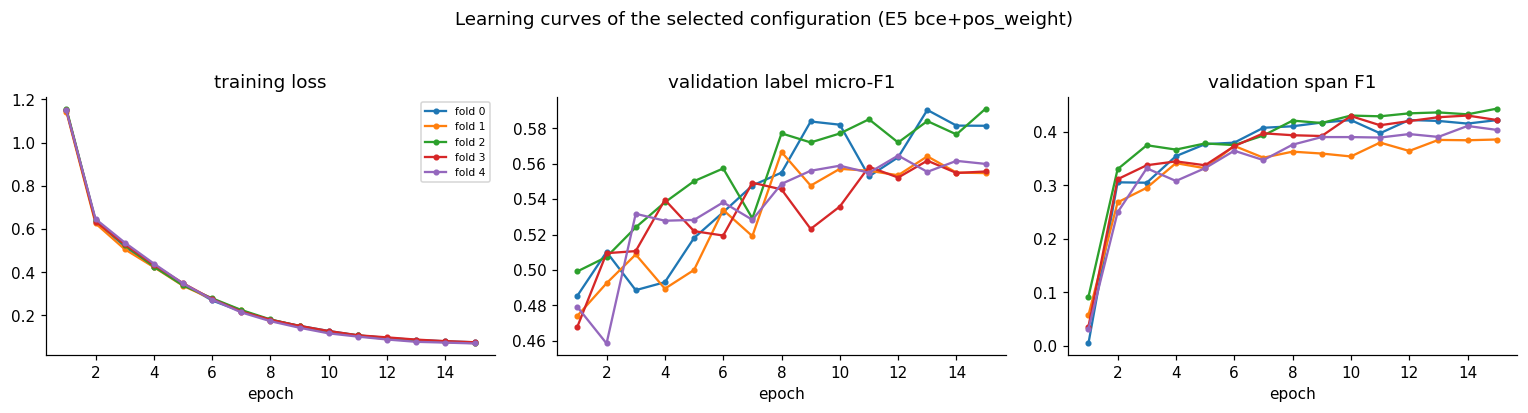

In [26]:
hist = RESULTS[BEST]["history"]
fig, ax = plt.subplots(1, 3, figsize=(14, 3.6))
for f, h in hist.groupby("fold"):
    ax[0].plot(h.epoch, h.train_loss, marker=".", label=f"fold {f}")
    ax[1].plot(h.epoch, h.val_label_f1, marker=".")
    ax[2].plot(h.epoch, h.val_span_f1, marker=".")
for a, t in zip(ax, ["training loss", "validation label micro-F1", "validation span F1"]):
    a.set_title(t); a.set_xlabel("epoch")
ax[0].legend(fontsize=7); fig.suptitle(f"Learning curves of the selected configuration ({BEST})", y=1.03)
plt.tight_layout(); plt.show()

<!-- CURVES-RESULT -->

**Reading the curves.** Training loss falls smoothly in every fold. Validation span F1 levels off after about 8
epochs. Validation label F1 is noisy (one meme moves it by almost a point) and still drifts upwards at epoch 15 in
some folds, so early stopping never had to stop training. There is no sign of the validation score collapsing
(overfitting), but a few more epochs might add a little. We note this as a limitation rather than tune it, because
it would mean selecting on the same noisy folds again.

### E7: One threshold or one per technique?
The model outputs probabilities, and the tool needs yes/no. We compare one global threshold with per-technique
thresholds, both tuned on out-of-fold predictions. Per-technique thresholds are estimated on few positives for
rare classes, so they risk overfitting. To measure that honestly we use **nested** tuning: thresholds are fitted on
four folds' out-of-fold predictions and applied to the fifth.

**H:** per-technique thresholds help only for techniques with enough positives. **Decision rule:** use
per-technique thresholds for techniques with at least `MIN_POS` development positives, and the global threshold
otherwise, *only if* this beats the global threshold in the nested comparison.

In [27]:
MIN_POS = 30
R = RESULTS[BEST]


def fit_thresholds(Y, P, per_class):
    g, _ = best_label_thr(Y, P)
    thr = np.full(K, g)
    if per_class:
        for k in range(K):
            if Y[:, k].sum() >= MIN_POS:
                scores = [f1_score(Y[:, k], P[:, k] >= t, zero_division=0) for t in LABEL_THR_GRID]
                thr[k] = LABEL_THR_GRID[int(np.argmax(scores))]
    return thr


rows = []
for f in range(N_FOLDS):
    fit, ev = (df_dev.fold != f).values, (df_dev.fold == f).values
    for mode in [False, True]:
        thr = fit_thresholds(Y_dev[fit], R["label_p"][fit], mode)
        rows.append({"fold": f, "thresholds": "per-technique" if mode else "global",
                     **label_scores(Y_dev[ev], R["label_p"][ev] >= thr)})
e7 = pd.DataFrame(rows)
display(e7.groupby("thresholds")[["micro_f1", "macro_f1", "micro_p", "micro_r"]].agg(["mean", "std"]).round(3))
d = (e7[e7.thresholds == "per-technique"].micro_f1.values - e7[e7.thresholds == "global"].micro_f1.values)
PER_CLASS_THR = d.mean() > 0 and d.mean() > d.std(ddof=1)
LABEL_THR = fit_thresholds(Y_dev, R["label_p"], PER_CLASS_THR)
print(f"paired Δ micro-F1 (per-technique − global) = {d.mean():+.3f} ± {d.std(ddof=1):.3f} → "
      f"{'per-technique' if PER_CLASS_THR else 'global'} thresholds; span threshold = {R['thr_span']}")

micro_f1        macro_f1        micro_p        micro_r       
                  mean    std     mean    std    mean    std    mean    std
thresholds                                                                 
global           0.553  0.009    0.274  0.043   0.543  0.023   0.565  0.032
per-technique    0.549  0.009    0.278  0.044   0.507  0.013   0.601  0.022

paired Δ micro-F1 (per-technique − global) = -0.003 ± 0.006 → global thresholds; span threshold = 0.3


<!-- E7-RESULT -->

**E7 result.** Per-technique thresholds do not help in the nested comparison (−0.003 ± 0.006 micro-F1). They raise
recall but cost more precision. One global threshold is used.

### E8: Robustness to casing, and casing augmentation
Every run above was also scored on lower-cased and sentence-cased validation text. About half the training
memes are in capitals, while students' feeds are mostly mixed case. **H:** performance drops on re-cased text,
and training with random re-casing (p = 0.5) removes most of the drop at little cost on the original text.
**Decision rule:** adopt augmentation if it keeps the selection score within noise (tie rule in reverse: it must
not *lose* by more than one sd) and improves lower-cased micro-F1 by more than one sd. Robustness is a deployment
requirement, not a tie-breaker.

In [28]:
base = {k: v for k, v in RESULTS[BEST]["cfg"].items() if k != "seed"}
run_cv("E8 casing-aug", **{**base, "casing_aug": 0.5})
rob = pd.DataFrame({nm: {"original": RESULTS[nm]["overall"]["micro_f1"],
                         "lower-cased": RESULTS[nm]["overall"]["micro_f1_lower"],
                         "sentence-cased": RESULTS[nm]["overall"]["micro_f1_sentence"]}
                    for nm in [BEST, "E8 casing-aug"]}).T
display(rob.style.format("{:.3f}").set_caption("Label micro-F1 (out-of-fold) under re-casing"))
d_sel = RESULTS["E8 casing-aug"]["folds"]["select"].values - RESULTS[BEST]["folds"]["select"].values
d_low = RESULTS["E8 casing-aug"]["folds"]["micro_f1_lower"].values - RESULTS[BEST]["folds"]["micro_f1_lower"].values
if d_sel.mean() > -d_sel.std(ddof=1) and d_low.mean() > d_low.std(ddof=1):
    BEST = "E8 casing-aug"
print(f"Δ select {d_sel.mean():+.3f} ± {d_sel.std(ddof=1):.3f}; Δ lower-cased micro-F1 {d_low.mean():+.3f} ± "
      f"{d_low.std(ddof=1):.3f} → chosen: {BEST}")

E8 casing-aug                micro=0.563 macro=0.305 span=0.406 select=0.485 | lower=0.554 | 9.2 min


,original,lower-cased,sentence-cased
E5 bce+pos_weight,0.562,0.554,0.560
E8 casing-aug,0.563,0.554,0.557


Δ select +0.000 ± 0.003; Δ lower-cased micro-F1 -0.001 ± 0.017 → chosen: E5 bce+pos_weight


<!-- E8-RESULT -->

**E8 result.** The hypothesis is rejected in an informative way: the model is **already robust to casing**
(0.562 original, 0.554 lower-cased, 0.560 sentence-cased), so augmentation has nothing to fix (Δ lower-cased
−0.001 ± 0.017). DeBERTa's tokenizer handles capitals well enough. Augmentation is not adopted.

### E9: Additional public data, the Propaganda Techniques Corpus (PTC)
**Declared external data.** The PTC is SemEval-2020 Task 11 (Da San Martino et al., 2020; Zenodo record 3952415,
CC-BY 4.0): 371 English **news articles** (2017–2019) with 6,129 character-level technique spans, annotated with the
same family of guidelines as our corpus.
* **Why it might help:** about 3× more span annotations than our 750 memes (2,083 spans), for the same techniques.
* **Why it might not:** news prose is long, formal and mixed-case. Memes are short, shouty and depend on images. The
  PTC taxonomy is also coarser: two of its classes merge several of ours (*Whataboutism + Straw Man + Red Herring*;
  *Bandwagon + Reductio ad hitlerum*), and it has no *Smears*, *Glittering generalities* or *Obfuscation*.
* **No leakage:** the PTC contains news articles, not memes. Below we check that no meme of our corpus (≥ 6 words)
  occurs in it verbatim, so it cannot contain the labels of our evaluation set.
* **Compliance:** this is *data* that we train on ourselves. No checkpoint trained by anyone else on propaganda
  labels is used.

**How it is used:** intermediate training (Phang et al., 2018). The encoder plus both heads are first trained on PTC
sentences for 2 epochs. Techniques that the PTC does not annotate cleanly are **masked out** of the loss, i.e.
treated as neither positive nor negative. The resulting encoder weights are the starting point for the normal
5-fold training on memes.

**H:** a small gain on techniques that are frequent in the PTC (Loaded Language, Name calling, Doubt, Exaggeration),
partly cancelled by the domain shift. **Decision rule:** adopt it only if it wins under the tie rule.

In [29]:
import tarfile, urllib.request
PTC_URL = "https://zenodo.org/api/records/3952415/files/datasets-v2.tgz/content"
PTC_MAP = {"Loaded_Language": "Loaded Language", "Name_Calling,Labeling": "Name calling/Labeling", "Repetition": "Repetition",
           "Doubt": "Doubt", "Exaggeration,Minimisation": "Exaggeration/Minimisation",
           "Appeal_to_fear-prejudice": "Appeal to fear/prejudice", "Flag-Waving": "Flag-waving",
           "Causal_Oversimplification": "Causal Oversimplification", "Appeal_to_Authority": "Appeal to authority",
           "Slogans": "Slogans", "Black-and-White_Fallacy": "Black-and-white Fallacy/Dictatorship",
           "Thought-terminating_Cliches": "Thought-terminating cliché"}  # merged PTC classes are deliberately not mapped
PTC_KNOWN = np.array([t in PTC_MAP.values() for t in TECHNIQUES])


def load_ptc():
    path = Path("ptc_datasets-v2.tgz")
    if not path.exists():
        download(PTC_URL, path)
    arts, labels = {}, collections.defaultdict(list)
    with tarfile.open(path) as tf:
        for mem in tf.getmembers():
            if mem.name.startswith("datasets/train-articles/") and mem.name.endswith(".txt"):
                arts[re.findall(r"article(\d+)", mem.name)[0]] = tf.extractfile(mem).read().decode("utf8")
            elif mem.name == "datasets/train-task2-TC.labels":
                for line in tf.extractfile(mem).read().decode("utf8").splitlines():
                    aid, tech, s, e = line.split("\t")
                    if tech in PTC_MAP:
                        labels[aid].append((int(s), int(e), PTC_MAP[tech]))
    rows = []
    for aid, text in arts.items():
        start = 0
        for line in text.split("\n"):
            end = start + len(line)
            if line.strip():
                sp = [(max(s, start) - start, min(e, end) - start, t) for s, e, t in labels[aid] if s < end and e > start]
                sp = [x for x in sp if x[1] > x[0]]
                y = np.zeros(K, np.float32)
                for _, _, t in sp:
                    y[T2I[t]] = 1
                rows.append({"id": f"ptc{aid}_{start}", "text": line, "spans": sp, "y": y})
            start = end + 1
    return pd.DataFrame(rows)


df_ptc = load_ptc()
_meme_norm = [re.sub(r"\s+", " ", t.lower().strip()) for t in df_all.text if len(t.split()) >= 6]
_ptc_blob = re.sub(r"\s+", " ", " ".join(df_ptc.text).lower())
print(f"PTC sentences: {len(df_ptc)}, with a mapped technique: {(np.stack(df_ptc.y).sum(1) > 0).sum()} | "
      f"memes (≥6 words) found verbatim in the PTC: {sum(m in _ptc_blob for m in _meme_norm)}")
_has = np.stack(df_ptc.y).sum(1) > 0
df_ptc_train = pd.concat([df_ptc[_has], df_ptc[~_has].sample(int(_has.sum()), random_state=SEED)]) \
    .sample(frac=1, random_state=SEED).reset_index(drop=True)
if FAST_DEV_RUN:
    df_ptc_train = df_ptc_train.head(200)
PTC_ENCODER_STATE = {}


def pretrain_on_ptc(encoder, epochs=2, lr=3e-5):
    seed_everything()
    cfg = {**DEFAULT_CFG, "encoder": encoder, "adaptation": "full", "label_head": "label_attention", "init_encoder": None}
    tok, amp = get_tok(encoder), ENCODERS[encoder]["amp"] and DEVICE.type == "cuda"
    dl = torch.utils.data.DataLoader(MemeDataset(df_ptc_train, tok), batch_size=32, shuffle=True,
                                     collate_fn=make_collate(tok.pad_token_id))
    model = PersuasionModel(cfg).to(DEVICE)
    opt = torch.optim.AdamW([{"params": model.encoder.parameters(), "lr": lr},
                             {"params": [p for n, p in model.named_parameters() if not n.startswith("encoder.")], "lr": 5e-4}],
                            weight_decay=0.01)
    steps = epochs * len(dl); sched = get_linear_schedule_with_warmup(opt, int(0.1 * steps), steps)
    scaler = torch.amp.GradScaler("cuda", enabled=amp)
    known = torch.tensor(PTC_KNOWN, device=DEVICE)
    for ep in range(epochs):
        model.train(); tot = 0.0
        for b in dl:
            bd = {k: v.to(DEVICE) for k, v in b.items() if torch.is_tensor(v)}
            with torch.autocast("cuda", dtype=torch.float16, enabled=amp):
                ll, sl, _ = model(bd["input_ids"], bd["attention_mask"], bd["token_mask"])
                loss = bce_loss(ll.float(), bd["y"], mask=known.expand_as(ll)) + bce_loss(
                    sl.float(), bd["token_labels"], mask=bd["token_mask"][..., None] & known)
            opt.zero_grad(set_to_none=True); scaler.scale(loss).backward(); scaler.unscale_(opt)
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0); scaler.step(opt); scaler.update(); sched.step()
            tot += loss.item()
        print(f"PTC intermediate training, epoch {ep + 1}: mean loss {tot / len(dl):.4f}")
    PTC_ENCODER_STATE[encoder] = {k: v.detach().cpu() for k, v in model.encoder.state_dict().items()}
    del model; gc.collect()


base = {k: v for k, v in RESULTS[BEST]["cfg"].items() if k != "seed"}
pretrain_on_ptc(base["encoder"])
run_cv("E9 + PTC intermediate training", **{**base, "init_encoder": "ptc"})
show([BEST, "E9 + PTC intermediate training"], BEST, "E9: additional data (PTC)")
pt_gain = pd.DataFrame({nm: f1_score(Y_dev, RESULTS[nm]["label_p"] >= RESULTS[nm]["thr_label"], average=None, zero_division=0)
                        for nm in [BEST, "E9 + PTC intermediate training"]}, index=[SHORT[t] for t in TECHNIQUES])
pt_gain["annotated in PTC"] = PTC_KNOWN
display(pt_gain.sort_values("annotated in PTC", ascending=False).style.format(
    "{:.3f}", subset=[BEST, "E9 + PTC intermediate training"]).set_caption("Out-of-fold F1 per technique"))
BEST = choose(BEST, ["E9 + PTC intermediate training"])
print("→ chosen:", BEST)

PTC sentences: 16673, with a mapped technique: 4629 | memes (≥6 words) found verbatim in the PTC: 0


PTC intermediate training, epoch 1: mean loss 0.3327


PTC intermediate training, epoch 2: mean loss 0.2044


E9 + PTC intermediate training micro=0.563 macro=0.295 span=0.403 select=0.483 | lower=0.562 | 8.6 min


,micro_f1,macro_f1,span_f1,select,Δ select (paired),folds won,micro_f1 lower-cased,trainable params (M),minutes
config,,,,,,,,,
E5 bce+pos_weight,0.562,0.296,0.408,0.485,+0.000 ± 0.000,–,0.554,184.7,9.4
E9 + PTC intermediate training,0.563,0.295,0.403,0.483,-0.001 ± 0.014,2/5,0.562,184.7,8.6


,E5 bce+pos_weight,E9 + PTC intermediate training,annotated in PTC
Authority,0.538,0.370,True
Loaded language,0.780,0.801,True
Thought-term.,0.000,0.162,True
Slogans,0.364,0.376,True
Repetition,0.696,0.480,True
Fear/prejudice,0.227,0.295,True
Name calling,0.628,0.668,True
Flag-waving,0.508,0.583,True
Exagg./Minim.,0.248,0.323,True
Doubt,0.333,0.400,True


→ chosen: E5 bce+pos_weight


<!-- E9-RESULT -->

**E9 result.** PTC intermediate training does not help overall (−0.001 ± 0.014). Per technique the picture is
mixed: it helps several techniques that the PTC annotates (Loaded Language, Name calling, Flag-waving, Doubt,
Exaggeration, Fear) but hurts others (Appeal to authority, Repetition, Causal oversimplification). News prose seems
to teach the *vocabulary* of propaganda but not the *meme format*. The extra data is therefore not used in the final
model, and no external data enters the final system.

### How large is the noise? (seed variance)
The tie rule uses fold-to-fold variation. As a second check, the selected configuration is re-trained with two
more seeds on the same folds. If seeds alone move the score by as much as the differences between design choices
above, those choices should be read as "no measurable difference", not as wins.

In [30]:
base = {k: v for k, v in RESULTS[BEST]["cfg"].items() if k != "seed"}
seed_names = [BEST] + [run_cv(f"seed {s}", **{**base, "seed": s}) and f"seed {s}" for s in (1, 2)]
seed_tab = pd.DataFrame({nm: RESULTS[nm]["overall"] for nm in seed_names}).T[["micro_f1", "macro_f1", "span_f1", "select"]]
display(seed_tab.style.format("{:.3f}").set_caption("Same configuration, three seeds"))
print("sd across seeds:", seed_tab.std().round(3).to_dict())

seed 1                       micro=0.561 macro=0.267 span=0.401 select=0.481 | lower=0.534 | 9.3 min


seed 2                       micro=0.550 macro=0.289 span=0.395 select=0.472 | lower=0.555 | 8.9 min


,micro_f1,macro_f1,span_f1,select
E5 bce+pos_weight,0.562,0.296,0.408,0.485
seed 1,0.561,0.267,0.401,0.481
seed 2,0.550,0.289,0.395,0.472


sd across seeds: {'micro_f1': 0.007, 'macro_f1': 0.015, 'span_f1': 0.007, 'select': 0.007}


<!-- SEED-RESULT -->

**Noise level.** Changing only the seed moves the selection score by a standard deviation of 0.007 and macro-F1 by
0.015. Most design differences above (E3–E9) are of the same size. They should be read as "no measurable
difference", which is exactly why the tie rule kept the simpler options. Only E1 (encoder), E2 (adaptation) and the
learning-rate extremes in E6 are clearly larger than this noise.

### Summary of the development experiments

In [31]:
summary = pd.DataFrame({nm: {**r["overall"], "trainable (M)": r["n_trainable"] / 1e6, "minutes": r["minutes"]}
                        for nm, r in RESULTS.items()}).T
summary = summary[["micro_f1", "macro_f1", "micro_p", "micro_r", "span_f1", "select", "micro_f1_lower",
                   "trainable (M)", "minutes"]]
summary.loc["baseline: majority"] = baselines.loc["majority"]
summary.loc["baseline: prior-random"] = baselines.loc["prior-random"]
display(summary.style.format("{:.3f}", na_rep="–").format({"trainable (M)": "{:.1f}", "minutes": "{:.1f}"}, na_rep="–")
        .highlight_max(subset=["micro_f1", "macro_f1", "span_f1", "select"], color="#d4edda")
        .set_caption("All development runs (out-of-fold, 750 memes)"))
FINAL_CFG = {k: v for k, v in RESULTS[BEST]["cfg"].items()}
print("FINAL configuration:", BEST, FINAL_CFG)

,micro_f1,macro_f1,micro_p,micro_r,span_f1,select,micro_f1_lower,trainable (M),minutes
E1 roberta-base,0.560847,0.245137,0.554145,0.567712,0.338150,0.449498,0.561033,125.5,5.9
E1 twitter-roberta-2021,0.553191,0.213079,0.570268,0.537108,0.333625,0.443408,0.558426,125.5,5.3
E1 deberta-v3-base,0.569824,0.242073,0.557918,0.582249,0.401467,0.485645,0.561364,184.7,7.4
E2 frozen,0.545391,0.158401,0.503234,0.595256,0.382469,0.463930,0.546898,0.8,2.8
E2 lora,0.539426,0.142676,0.572041,0.510329,0.366134,0.452780,0.530029,1.4,4.7
E2 lora lr=2e-3,0.523513,0.162830,0.477603,0.579189,0.323157,0.423335,0.527410,1.4,3.2
E3 label-only,0.560405,0.181368,0.571088,0.550115,–,0.560405,0.561157,184.5,5.8
E3 span-only (labels derived),0.493585,0.171400,0.441692,0.559296,0.355767,0.424676,0.503145,184.0,7.4
E3 derived + label loss,0.569888,0.204433,0.573643,0.566182,0.420678,0.495283,0.574219,184.0,9.3
E4 cls,0.545036,0.144091,0.546083,0.543994,0.411866,0.478451,0.552067,184.6,8.9


FINAL configuration: E5 bce+pos_weight {'encoder': 'deberta-v3-base', 'adaptation': 'full', 'lora_r': 16, 'label_head': 'label_attention', 'label_loss_weight': 1.0, 'span_loss_weight': 1.0, 'loss': 'bce_pw', 'focal_gamma': 2.0, 'lr_encoder': 3e-05, 'lr_head': 0.0005, 'weight_decay': 0.01, 'dropout': 0.1, 'epochs': 15, 'patience': 4, 'batch_size': 16, 'warmup': 0.1, 'casing_aug': 0.0, 'init_encoder': None, 'seed': 42}


## 5. The final model on the held-out test set

**Final system.** The selected configuration is trained once per fold, and the **five fold models are averaged**
(a 5-model ensemble). Why not retrain one model on all 750 memes?
* The ensemble's thresholds were tuned on exactly the kind of model they are applied to (out-of-fold predictions
  of fold models). A retrained model would have no held-out data left to calibrate them.
* On 600-meme training sets, single runs vary noticeably with initialisation and data order. Averaging five models
  reduces that variance (Section 4, seed check).
* The latency cost is measured below and is acceptable on a T4.

The test set is used **here for the first time**, with every choice already fixed.

In [32]:
FINAL = run_cv("FINAL", keep_models=True, **FINAL_CFG)
LABEL_THR = fit_thresholds(Y_dev, FINAL["label_p"], PER_CLASS_THR)
SPAN_THR = FINAL["thr_span"]
FINAL_TOK = get_tok(FINAL_CFG["encoder"])
AMP = ENCODERS[FINAL_CFG["encoder"]]["amp"]


def ensemble_predict(df, models=None):
    models = models or FINAL["models"]
    dl = torch.utils.data.DataLoader(MemeDataset(df, FINAL_TOK), batch_size=64, collate_fn=make_collate(FINAL_TOK.pad_token_id))
    lps, tps, atts = [], [], []
    for m in models:
        m.to(DEVICE)
        lp, tp, offs, att = predict(m, dl, AMP)
        lps.append(lp); tps.append(tp); atts.append(att)
        m.cpu()
    label_p = np.mean(lps, 0)
    token_p = [np.mean([tp[i] for tp in tps], 0) if tps[0][i] is not None else None for i in range(len(df))]
    att = [np.mean([a[i] for a in atts], 0) if atts[0][i] is not None else None for i in range(len(df))]
    return {"label_p": label_p, "labels": (label_p >= LABEL_THR).astype(int), "token_p": token_p, "offsets": offs,
            "spans": spans_from_probs(token_p, offs, SPAN_THR, list(df.text)) if SPAN_THR is not None else [[] for _ in range(len(df))],
            "att": att}


TEST = ensemble_predict(df_test)
Y_test = np.stack(df_test.y)
gold_test = list(df_test.spans)

FINAL                        micro=0.562 macro=0.296 span=0.408 select=0.485 | lower=0.554 | 9.5 min


In [33]:
def test_row(name, Yp, spans):
    s = {**label_scores(Y_test, Yp), **span_scores(gold_test, spans)}
    lo, hi = bootstrap_ci(lambda a, b: f1_score(a, b, average="micro", zero_division=0), Y_test, Yp)
    s["micro_f1 95% CI"] = f"[{lo:.3f}, {hi:.3f}]"
    lo, hi = bootstrap_ci(lambda g, p: span_scores(g, p)["span_f1"], gold_test, spans)
    s["span_f1 95% CI"] = f"[{lo:.3f}, {hi:.3f}]"
    return pd.Series(s, name=name)


maj = np.zeros_like(Y_test); maj[:, T2I["Loaded Language"]] = 1
single = ensemble_predict(df_test, FINAL["models"][:1])
test_tab = pd.DataFrame([
    test_row("final ensemble (5 models)", TEST["labels"], TEST["spans"]),
    test_row("single fold model (for reference)", single["labels"], single["spans"]),
    test_row("majority baseline", maj, [whole_text_spans(t, ["Loaded Language"]) for t in df_test.text]),
])
test_tab.loc["SemEval-2021 best team (Dimitrov et al.)"] = pd.Series({"micro_f1": .593, "macro_f1": .290, "span_f1": .482})
display(test_tab[["micro_f1", "micro_f1 95% CI", "macro_f1", "micro_p", "micro_r", "span_f1", "span_f1 95% CI",
                  "span_p", "span_r"]].style.format("{:.3f}", na_rep="–", subset=["micro_f1", "macro_f1", "micro_p",
                  "micro_r", "span_f1", "span_p", "span_r"]).set_caption("Held-out official test set (200 memes)"))

,micro_f1,micro_f1 95% CI,macro_f1,micro_p,micro_r,span_f1,span_f1 95% CI,span_p,span_r
final ensemble (5 models),0.519,"[0.469, 0.565]",0.221,0.479,0.567,0.405,"[0.357, 0.442]",0.407,0.403
single fold model (for reference),0.495,"[0.444, 0.540]",0.238,0.449,0.552,0.376,"[0.330, 0.418]",0.357,0.396
majority baseline,0.374,"[0.331, 0.419]",0.033,0.500,0.299,0.165,"[0.137, 0.196]",0.106,0.372
SemEval-2021 best team (Dimitrov et al.),0.593,nan,0.290,–,–,0.482,nan,–,–


<!-- TEST-RESULT -->

**Test result.**
* Labels: **micro-F1 0.519 (95% CI 0.469–0.565)**, macro-F1 0.221. Precision 0.48, recall 0.57.
* Spans: **span F1 0.405 (95% CI 0.357–0.442)**.
* This is clearly above the majority baseline (0.374, and 0.165 for spans). It is below the SemEval-2021 winner
  (0.593 / 0.482), which used PTC-pretrained ensembles that our rules forbid.
* It is **lower than the cross-validation estimate (0.562)**. Two reasons: the CV numbers were used to select the
  configuration and thresholds, so they are optimistic; and the test memes are harder for the tail techniques. This
  gap is the honest price of a clean protocol. **0.52 is the number to expect on memes like these.**
* The ensemble beats a single fold model (0.495 / 0.376), as intended.

### Per-technique behaviour

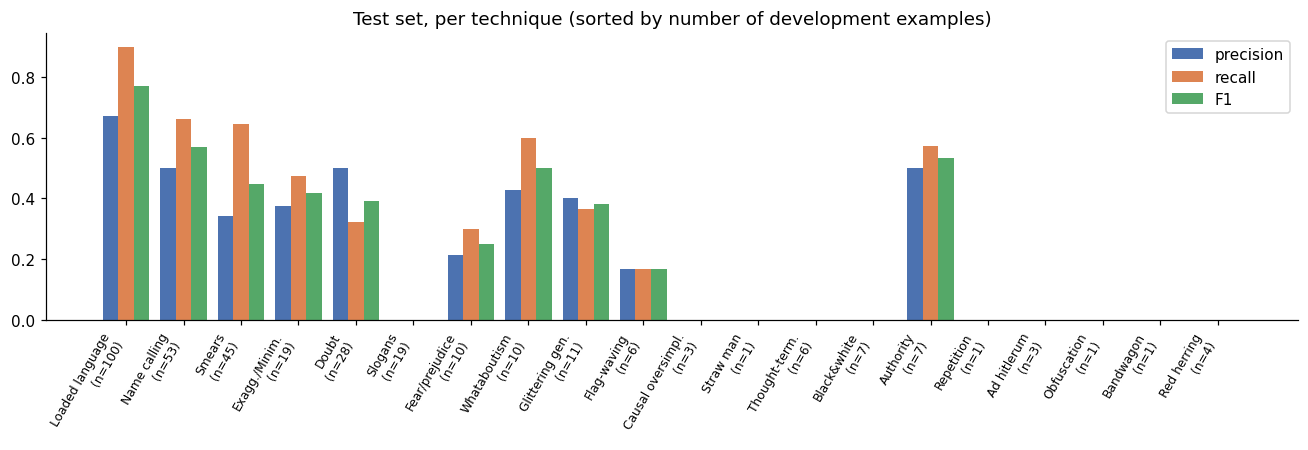

techniques with ≥ 30 development examples: ['Fear/prejudice', 'Doubt', 'Exagg./Minim.', 'Flag-waving', 'Glittering gen.', 'Loaded language', 'Name calling', 'Slogans', 'Smears', 'Whataboutism']


In [34]:
sup = Y_test.sum(0).astype(int)
pt = pd.DataFrame({
    "test support": sup,
    "precision": precision_score(Y_test, TEST["labels"], average=None, zero_division=0),
    "recall": recall_score(Y_test, TEST["labels"], average=None, zero_division=0),
    "F1": f1_score(Y_test, TEST["labels"], average=None, zero_division=0),
    "dev support": Y_dev.sum(0).astype(int),
}, index=[SHORT[t] for t in TECHNIQUES]).sort_values("dev support", ascending=False)
fig, ax = plt.subplots(figsize=(12, 4.2))
x = np.arange(len(pt))
ax.bar(x - 0.27, pt.precision, 0.27, label="precision", color="#4C72B0")
ax.bar(x, pt.recall, 0.27, label="recall", color="#DD8452")
ax.bar(x + 0.27, pt.F1, 0.27, label="F1", color="#55A868")
ax.set_xticks(x, [f"{i}\n(n={n})" for i, n in zip(pt.index, pt["test support"])], rotation=60, ha="right", fontsize=8)
ax.set_title("Test set, per technique (sorted by number of development examples)"); ax.legend()
plt.tight_layout(); plt.show()
SUPPORTED = [t for t in TECHNIQUES if Y_dev[:, T2I[t]].sum() >= MIN_POS]
print("techniques with ≥", MIN_POS, "development examples:", [SHORT[t] for t in SUPPORTED])

<!-- PERTECH-RESULT -->

**Reading.** Only a handful of techniques are usable: Loaded Language (F1 0.77), Name calling (0.57), Whataboutism
(0.50), Exaggeration (0.42), Smears (0.45) and Appeal to authority (0.53, but only 7 test examples). Slogans gets
F1 0 on test despite 47 development examples. All techniques with fewer than 10 development examples are never
found. For the classroom this means the tool can support a lesson on a few core techniques, not the whole taxonomy.

### Which techniques get confused with which?
In multi-label output, "confusion" means: when the gold technique *a* is **missed**, which wrong technique *b* was
predicted for the same meme instead?

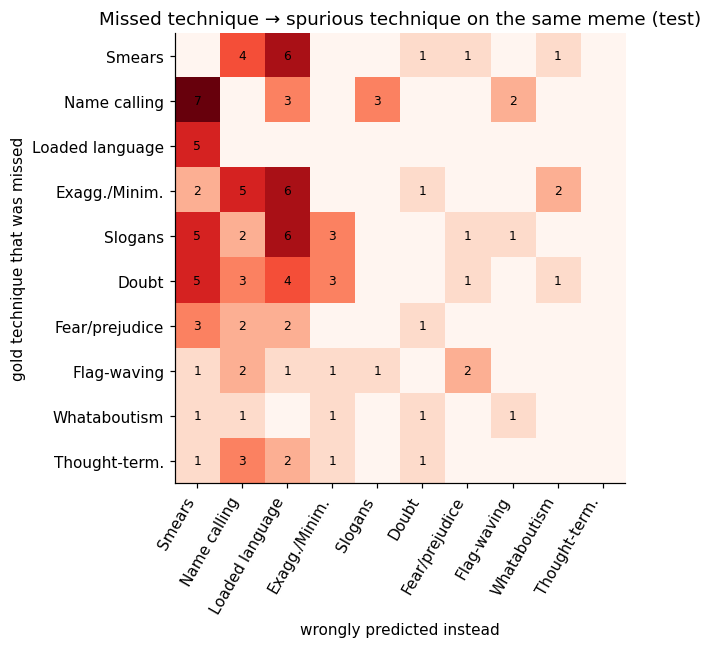

In [35]:
conf = np.zeros((K, K))
for yt, yp in zip(Y_test, TEST["labels"]):
    for a in np.where((yt == 1) & (yp == 0))[0]:
        for b in np.where((yp == 1) & (yt == 0))[0]:
            conf[a, b] += 1
top = np.argsort(-(conf.sum(1) + conf.sum(0)))[:10]
fig, ax = plt.subplots(figsize=(7.5, 6))
ax.imshow(conf[np.ix_(top, top)], cmap="Reds")
for i, a in enumerate(top):
    for j, b in enumerate(top):
        if conf[a, b]:
            ax.text(j, i, int(conf[a, b]), ha="center", va="center", fontsize=8)
ax.set_xticks(range(len(top)), [SHORT[TECHNIQUES[i]] for i in top], rotation=60, ha="right")
ax.set_yticks(range(len(top)), [SHORT[TECHNIQUES[i]] for i in top])
ax.set_xlabel("wrongly predicted instead"); ax.set_ylabel("gold technique that was missed")
ax.set_title("Missed technique → spurious technique on the same meme (test)")
plt.tight_layout(); plt.show()

<!-- CONF-RESULT -->

**Reading.** The errors have a pattern. When the model misses a subtler technique (Slogans, Doubt, Exaggeration,
Fear), it usually predicts one of the three frequent "attack" techniques instead (Smears, Name calling, Loaded
Language). The model has learned that a meme is hostile, but not always *how* it argues.

### Reading individual outputs
A sample of test memes with gold and predicted techniques. Spans are shown for one technique each, to keep the
table readable.

In [36]:
def fmt_labels(y):
    return ", ".join(SHORT[TECHNIQUES[i]] for i in np.where(y)[0]) or "—"


ex = df_test.assign(gold=[fmt_labels(y) for y in Y_test], predicted=[fmt_labels(y) for y in TEST["labels"]],
                    jaccard=[(a & b).sum() / (a | b).sum() if (a | b).any() else 1.0
                             for a, b in zip(Y_test.astype(bool), TEST["labels"].astype(bool))],
                    predicted_spans=["; ".join(f"{SHORT[t]}: «{txt[s:e][:40]}»" for s, e, t in sp[:3])
                                     for txt, sp in zip(df_test.text, TEST["spans"])])
pick = lambda d, n: d.sample(min(n, len(d)), random_state=0)
sample = pd.concat([pick(ex[ex.jaccard == 1], 3), pick(ex[(ex.jaccard > 0) & (ex.jaccard < 1)], 3), pick(ex[ex.jaccard == 0], 4)])
display(sample[["text", "gold", "predicted", "predicted_spans"]].assign(text=sample.text.str.slice(0, 110)))

,text,gold,predicted,predicted_spans
49,"Enjoy Communism\n""it's finger lickin'good""\n\n","Loaded language, Name calling","Loaded language, Name calling",Loaded language: «Communism»; Loaded language: «finger lickin»; Loaded language: «good»
144,IF YOU CAN DO THIS SIX FEET APART...\n\nYOU CAN DO THIS SIX FEET APART\n,—,—,
174,TCF Center fraudster Ruby Freeman criminal\n\nRuby Freeman criminal\n,"Loaded language, Name calling","Loaded language, Name calling",Loaded language: «fraudster»; Loaded language: «criminal»; Loaded language: «criminal»
48,He's been telling us for months about election fraud...\nDo you really believe he hasn't been preparing for thi,"Doubt, Loaded language, Thought-term.",Loaded language,
105,WEARING A MASK INTO A RESTAURANT JUST TO SIT DOWN AND TAKE IT OFF?\n\nIS LIKE HAVING A PISSING SECTION IN A SWIM,"Doubt, Loaded language",Loaded language,Loaded language: «MASK»; Loaded language: «PISSING SECTION»
5,HYPOCRISY MUCH?!\nMacy's Thanksgiving Day Parade to March On Despite Pandemic\n\nBusinesses Are Closing Permanent,"Loaded language, Smears, Whataboutism","Loaded language, Smears",Loaded language: «HYPOCRISY»; Loaded language: «Pandemic»; Loaded language: «Closing Permanently»
142,I DID NOT HAVE SEXUAL RELATIONS WITH THAT WOMAN.\n\nI HAVE NEVER BEEN TO EPSTEIN'S ISLAND.\n\n,Red herring,Doubt,Doubt: «WOMAN»
159,A NEW MASK HAS BEEN RELEASED THAT WILL SAVE COUNTLESS LIVES!,Slogans,"Exagg./Minim., Loaded language",
196,HE'S MAKING HIS LIST\n\nHE'S CHECKING IT TWICE\n\nVoter fraud\n,Loaded language,—,
166,GOYA\nEMPLOYEE OF THE MONTH\n\nBoosting sales 1000%\nWhile using 0% brain cells,Exagg./Minim.,"Loaded language, Name calling",Loaded language: «Boosting»; Loaded language: «1000»; Loaded language: «0»


### Can it run on the school's machine? (size and latency)
The department's machine is "no better than one T4 (16 GB)". The ensemble is five base-size encoders. We measure
parameter memory and the wall-clock latency for one meme (batch size 1, the classroom case) on the hardware this
notebook runs on. A T4 is the Colab default, so on Colab the numbers are measured on the target hardware.

In [37]:
def latency(models, texts, reps=30):
    ms = []
    for m in models:
        m.to(DEVICE).eval()
    with torch.no_grad():
        for i in range(reps + 3):
            enc = FINAL_TOK([texts[i % len(texts)]], return_tensors="pt", truncation=True, max_length=MAX_LEN).to(DEVICE)
            tm = enc["attention_mask"].bool()
            if DEVICE.type == "cuda":
                torch.cuda.synchronize()
            t0 = time.perf_counter()
            for m in models:
                with torch.autocast("cuda", dtype=torch.float16, enabled=AMP and DEVICE.type == "cuda"):
                    m(enc["input_ids"], enc["attention_mask"], tm)
            if DEVICE.type == "cuda":
                torch.cuda.synchronize()
            if i >= 3:
                ms.append((time.perf_counter() - t0) * 1000)
    for m in models:
        m.cpu()
    return np.median(ms), np.percentile(ms, 95)


params = sum(p.numel() for p in FINAL["models"][0].parameters())
if DEVICE.type == "cuda":
    torch.cuda.reset_peak_memory_stats()
lat1 = latency(FINAL["models"][:1], list(df_test.text))
lat5 = latency(FINAL["models"], list(df_test.text))
peak = torch.cuda.max_memory_allocated() / 1e9 if DEVICE.type == "cuda" else float("nan")
display(pd.DataFrame({
    "parameters per model (M)": [params / 1e6] * 2,
    "weights in fp16 (GB)": [params * 2 / 1e9, 5 * params * 2 / 1e9],
    "median latency per meme (ms)": [lat1[0], lat5[0]], "p95 latency (ms)": [lat1[1], lat5[1]],
}, index=["single model", "5-model ensemble"]).round(2))
print(f"device: {torch.cuda.get_device_name(0) if DEVICE.type == 'cuda' else 'CPU'}; peak GPU memory during the benchmark: {peak:.2f} GB")

,parameters per model (M),weights in fp16 (GB),median latency per meme (ms),p95 latency (ms)
single model,184.65,0.37,28.35,29.73
5-model ensemble,184.65,1.85,141.61,145.28


device: Tesla T4; peak GPU memory during the benchmark: 7.64 GB


<!-- LATENCY-RESULT -->

**Deployment fit.** Measured on a Tesla T4: one model answers in **28 ms**, the five-model ensemble in **142 ms**
per meme. The ensemble's weights take 1.85 GB in fp16. That is far inside a 16 GB T4 and instant from a
student's point of view. (The 7.6 GB peak includes the models kept in memory for the whole notebook.)

### Explainability: what does the label head look at?
A label is only useful in class if we can show *why*. We use two complementary views on the final models:
* **Integrated Gradients** (Sundararajan et al., 2017). This is model-agnostic: the technique's logit is integrated
  along a straight path from a neutral input (every token embedding replaced by the padding embedding) to the real
  input, giving each token a share of the logit. It satisfies *completeness*: the attributions sum to the change
  in the logit.
* **Label-wise attention weights** from our own head: where each technique's query looked.

**Quantitative test.** If the label head relies on the persuasive words, attribution mass should concentrate inside
the **gold span** of that technique. For every correctly predicted (meme, technique) pair on the test set we compute
the share of positive IG attribution that falls on gold-span tokens. We compare it with the share of tokens that
are in the gold span: this is what a head that looks everywhere uniformly would get.

In [38]:
def integrated_gradients(model, text, k, steps=32):
    enc = FINAL_TOK([text], return_tensors="pt", truncation=True, max_length=MAX_LEN, return_offsets_mapping=True)
    offs = trimmed_offsets(text, enc.pop("offset_mapping")[0].tolist())
    enc = enc.to(DEVICE); model.to(DEVICE).eval()
    emb_layer = model.encoder.get_input_embeddings()
    x = emb_layer(enc["input_ids"]).detach()
    x0 = emb_layer(torch.full_like(enc["input_ids"], FINAL_TOK.pad_token_id)).detach()
    tmask = torch.tensor([[a < b for a, b in offs]], device=DEVICE)
    grads = torch.zeros_like(x)
    for a in torch.linspace(0, 1, steps + 1, device=DEVICE)[1:]:
        xi = (x0 + a * (x - x0)).requires_grad_(True)
        H = model.encoder(inputs_embeds=xi, attention_mask=enc["attention_mask"]).last_hidden_state
        if model.label_head is not None:
            logit = model.label_head(H, enc["attention_mask"].bool())[0][0, k]
        else:
            logit = model.span_head(H)[0, :, k].masked_fill(~tmask[0], -1e4).max()
        grads += torch.autograd.grad(logit, xi)[0]
    attr = ((x - x0) * grads / steps).sum(-1)[0].detach().cpu().numpy()
    model.cpu()
    return attr, offs


ig_rows, ig_examples = [], []
explain_model = FINAL["models"][0]
for i, (text, spans) in enumerate(zip(df_test.text, gold_test)):
    for k in np.where((Y_test[i] == 1) & (TEST["labels"][i] == 1))[0]:
        attr, offs = integrated_gradients(explain_model, text, k)
        real = np.array([a < b for a, b in offs])
        inside = np.array([any(a < e and s < b for s, e, t in spans if t == TECHNIQUES[k]) for a, b in offs]) & real
        pos = np.clip(attr, 0, None) * real
        if pos.sum() > 0 and inside.sum() > 0:
            ig_rows.append({"technique": SHORT[TECHNIQUES[k]], "attribution in gold span": pos[inside].sum() / pos.sum(),
                            "tokens in gold span": inside.sum() / real.sum()})
        if len(ig_examples) < 4 and TECHNIQUES[k] in ("Name calling/Labeling", "Loaded Language", "Slogans", "Doubt") \
                and len(text.split()) < 30 and TECHNIQUES[k] not in [e[2] for e in ig_examples]:
            ig_examples.append((text, offs, TECHNIQUES[k], attr, inside))
ig = pd.DataFrame(ig_rows)
ig_tab = ig.groupby("technique").agg(n=("technique", "size"), attribution_in_span=("attribution in gold span", "mean"),
                                     uniform_expectation=("tokens in gold span", "mean")).sort_values("n", ascending=False)
ig_tab.loc["ALL"] = [len(ig), ig["attribution in gold span"].mean(), ig["tokens in gold span"].mean()]
display(ig_tab.style.format({"attribution_in_span": "{:.2f}", "uniform_expectation": "{:.2f}"})
        .set_caption("Share of positive IG attribution on gold-span tokens vs. share of tokens in the span"))

,n,attribution_in_span,uniform_expectation
technique,,,
Loaded language,89.000000,0.28,0.22
Name calling,35.000000,0.36,0.34
Smears,29.000000,0.75,0.75
Doubt,9.000000,0.89,0.87
Exagg./Minim.,9.000000,0.48,0.43
Whataboutism,6.000000,0.96,0.92
Authority,4.000000,0.85,0.86
Glittering gen.,4.000000,0.76,0.76
Fear/prejudice,3.000000,0.52,0.58


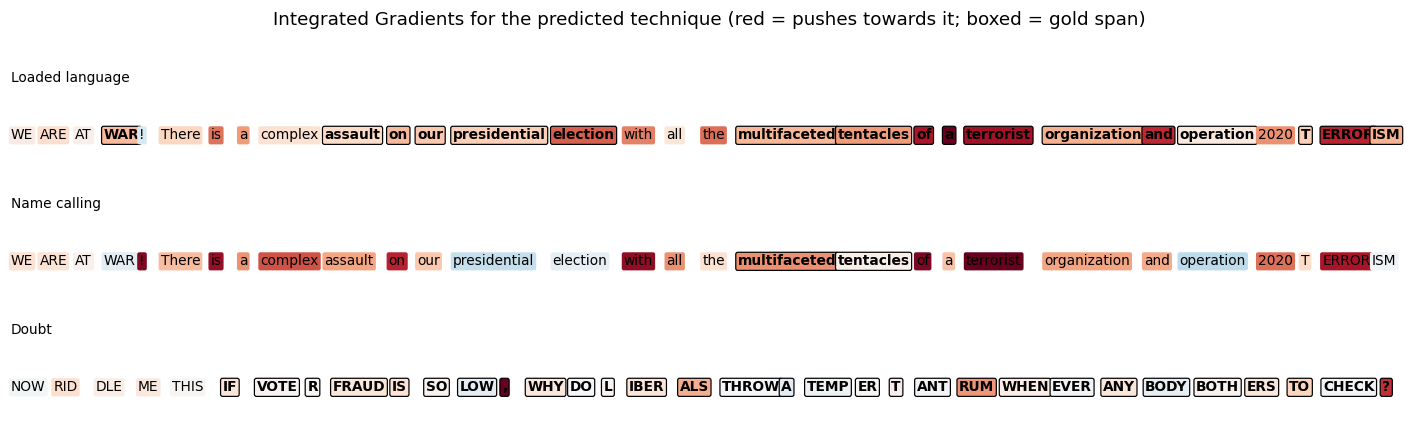

In [39]:
fig, axes = plt.subplots(len(ig_examples), 1, figsize=(13, 1.3 * len(ig_examples)))
for ax, (text, offs, tech, attr, inside) in zip(np.atleast_1d(axes), ig_examples):
    toks = [(text[a:b], v, ins) for (a, b), v, ins in zip(offs, attr, inside) if a < b]
    vmax = max(abs(v) for _, v, _ in toks) or 1
    xpos = 0.0
    for w, v, ins in toks:
        ax.text(xpos, 0.5, w, fontsize=9, va="center", fontweight="bold" if ins else "normal",
                bbox=dict(facecolor=plt.cm.RdBu_r(0.5 + 0.5 * v / vmax), edgecolor="black" if ins else "none",
                          boxstyle="round,pad=0.15", linewidth=0.8))
        xpos += 0.011 * (len(w) + 2)
    ax.set_xlim(0, max(xpos, 1)); ax.axis("off"); ax.set_title(f"{SHORT[tech]}", loc="left", fontsize=9)
fig.suptitle("Integrated Gradients for the predicted technique (red = pushes towards it; boxed = gold span)", y=1.02)
plt.tight_layout(); plt.show()

<!-- IG-RESULT -->

**Explainability result.** Overall, 45% of the positive attribution falls on gold-span tokens, against 42% for a
uniform spread. For short, lexical techniques the concentration is a little stronger (Loaded Language 0.28 vs.
0.22), and for whole-message techniques the two are equal by construction. So the label head does **not** rely
mainly on the exact words the annotators marked: it uses the whole meme. For a teacher this means the IG heatmap
alone is not a reliable "here is the technique" pointer. The span head, which is trained for that job, should be
the pointer, and C3 below checks how often the two agree.

## 6. Part C: product evaluation
All four questions are answered with experiments on the final system. For more statistical power, several
analyses use **all 950 memes**. The 750 development memes are scored *out-of-fold*: each by the fold model that
never saw it. The 200 test memes are scored by the ensemble. No model is ever scored on a meme it was trained on.

In [40]:
def oof_and_test_predict(texts_dev, texts_test):
    """Out-of-fold predictions for (possibly modified) development texts + ensemble predictions for test texts."""
    lab_dev = np.zeros((len(df_dev), K)); tok_dev = [None] * len(df_dev); off_dev = [None] * len(df_dev)
    for f, m in enumerate(FINAL["models"]):
        idx = np.where(df_dev.fold == f)[0]
        sub = df_dev.iloc[idx].assign(text=[texts_dev[i] for i in idx])
        r = ensemble_predict(sub, [m])
        lab_dev[idx] = r["label_p"]
        for j, i in enumerate(idx):
            tok_dev[i], off_dev[i] = r["token_p"][j], r["offsets"][j]
    rt = ensemble_predict(df_test.assign(text=list(texts_test)))
    return (np.concatenate([lab_dev, rt["label_p"]]), tok_dev + rt["token_p"], off_dev + rt["offsets"])


df_both = pd.concat([df_dev.assign(part="dev (out-of-fold)"), df_test.assign(part="test")], ignore_index=True)
Y_both = np.stack(df_both.y)
P_both, TOKP_both, OFF_both = oof_and_test_predict(list(df_dev.text), list(df_test.text))
L_both = (P_both >= LABEL_THR).astype(int)
SPANS_both = spans_from_probs(TOKP_both, OFF_both, SPAN_THR, list(df_both.text))

### C3. Does the label head agree with the span head?
For each meme and technique there are two independent yes/no answers:
* the **label head** says "the meme uses *k*" (probability ≥ threshold);
* the **span head** says "these words are *k*" (at least one decoded span of *k*).

We count four cases: both yes, label-only (a label with nothing to point at), span-only (words underlined but no
label), and both no. For the disagreements we also check **who was right** against the gold annotation. That is
what decides what the screen should show.

**H:** disagreement concentrates on discourse-level techniques. Their evidence is the whole message, so the span
head's per-token decisions are less confident than the label head's meme-level decision.

C3 measured on the final system (950 memes: out-of-fold + test)
overall: 1308 agreed positives, 583 label-only, 117 span-only → 34.9% of flagged (meme, technique) pairs disagree; label-only correct 29%, span-only correct 36%, both-yes correct 62%


,gold memes,both,label only,span only,disagree % of flagged,label-only correct %,span-only correct %,median gold span / text
technique,,,,,,,,
Loaded language,489,480,175,10,28,37,60,0
Name calling,300,240,128,17,38,30,59,0
Smears,263,328,44,46,22,36,28,1
Doubt,84,60,34,6,40,26,17,1
Exagg./Minim.,78,38,48,4,58,15,100,0
Slogans,66,19,19,2,52,5,100,0
Fear/prejudice,57,19,36,2,67,17,50,0
Whataboutism,54,62,6,17,27,0,6,1
Glittering gen.,44,8,23,3,76,26,33,1


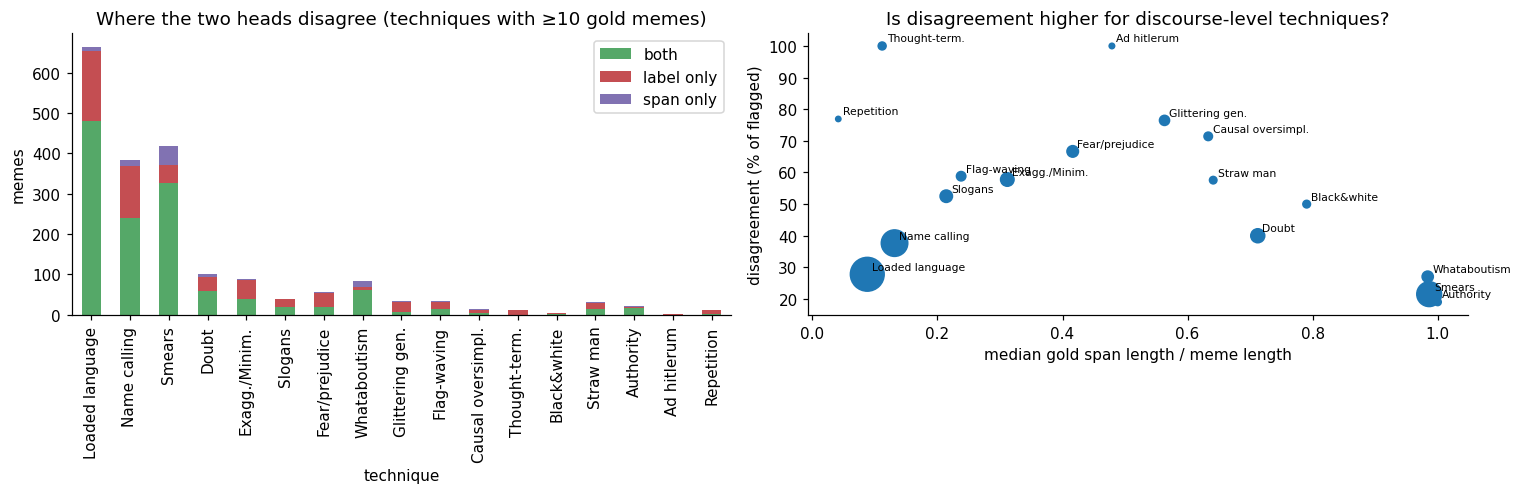

Spearman correlation (span length share vs. disagreement) over 17 techniques: -0.50


In [41]:
if FINAL_CFG["label_head"] == "from_spans":
    # The selected architecture derives labels from spans, so its two outputs agree by construction (one reason it
    # may have been chosen). To still answer C3 we measure the best two-head configuration from Section 4 on its
    # 750 out-of-fold predictions.
    two_head = [nm for nm, r in RESULTS.items() if r["cfg"]["label_head"] != "from_spans" and r["thr_span"] is not None]
    src = max(two_head, key=lambda nm: RESULTS[nm]["overall"]["select"])
    R3 = RESULTS[src]
    C3_TEXT, C3_GOLD = df_dev, Y_dev
    C3_L = (R3["label_p"] >= R3["thr_label"]).astype(int)
    C3_SPANS = spans_from_probs(R3["token_p"], R3["offsets"], R3["thr_span"], list(df_dev.text))
    print(f"C3 measured on the two-head configuration '{src}' ({len(C3_TEXT)} out-of-fold memes)")
else:
    C3_TEXT, C3_GOLD, C3_L, C3_SPANS = df_both, Y_both, L_both, SPANS_both
    print(f"C3 measured on the final system ({len(C3_TEXT)} memes: out-of-fold + test)")
pct = lambda a: f"{100 * a.mean():.0f}%" if a.size else "n/a"
span_flag = np.zeros_like(C3_L)
for i, sp in enumerate(C3_SPANS):
    for _, _, t in sp:
        span_flag[i, T2I[t]] = 1
rows = []
for k, t in enumerate(TECHNIQUES):
    lab, spn, gold = C3_L[:, k], span_flag[:, k], C3_GOLD[:, k]
    lo, so = (lab == 1) & (spn == 0), (lab == 0) & (spn == 1)
    rows.append({"technique": SHORT[t], "gold memes": int(gold.sum()), "both": int(((lab == 1) & (spn == 1)).sum()),
                 "label only": int(lo.sum()), "span only": int(so.sum()),
                 "disagree % of flagged": 100 * (lo.sum() + so.sum()) / max(((lab == 1) | (spn == 1)).sum(), 1),
                 "label-only correct %": 100 * gold[lo].mean() if lo.any() else np.nan,
                 "span-only correct %": 100 * gold[so].mean() if so.any() else np.nan,
                 "median gold span / text": np.median([(e - s) / max(len(C3_TEXT.text.iloc[i].strip()), 1)
                                                       for i in range(len(C3_TEXT)) for s, e, tt in C3_TEXT.spans.iloc[i] if tt == t])
                 if gold.any() else np.nan})
c3 = pd.DataFrame(rows).set_index("technique").sort_values("gold memes", ascending=False)
tot = c3[["both", "label only", "span only"]].sum()
lo_all, so_all = (C3_L == 1) & (span_flag == 0), (C3_L == 0) & (span_flag == 1)
print(f"overall: {tot['both']} agreed positives, {tot['label only']} label-only, {tot['span only']} span-only → "
      f"{100 * (tot['label only'] + tot['span only']) / tot.sum():.1f}% of flagged (meme, technique) pairs disagree; "
      f"label-only correct {pct(C3_GOLD[lo_all])}, span-only correct {pct(C3_GOLD[so_all])}, "
      f"both-yes correct {pct(C3_GOLD[(C3_L == 1) & (span_flag == 1)])}")
display(c3.style.format("{:.0f}", na_rep="–").set_caption(f"Label head vs. span head ({len(C3_TEXT)} memes)"))

fig, ax = plt.subplots(1, 2, figsize=(14, 4.6))
show_t = c3[c3["gold memes"] >= 10]
show_t[["both", "label only", "span only"]].plot.bar(stacked=True, ax=ax[0], color=["#55A868", "#C44E52", "#8172B2"])
ax[0].set_title("Where the two heads disagree (techniques with ≥10 gold memes)"); ax[0].set_ylabel("memes")
ax[1].scatter(show_t["median gold span / text"], show_t["disagree % of flagged"], s=show_t["gold memes"])
for nm, r in show_t.iterrows():
    ax[1].annotate(nm, (r["median gold span / text"], r["disagree % of flagged"]), fontsize=7, xytext=(3, 3), textcoords="offset points")
ax[1].set_xlabel("median gold span length / meme length"); ax[1].set_ylabel("disagreement (% of flagged)")
ax[1].set_title("Is disagreement higher for discourse-level techniques?")
plt.tight_layout(); plt.show()
rho = pd.Series(show_t["median gold span / text"]).corr(show_t["disagree % of flagged"], method="spearman")
print(f"Spearman correlation (span length share vs. disagreement) over {len(show_t)} techniques: {rho:.2f}")

**What should the screen show?** We turn the evidence into a display policy and score each candidate with the
same label metrics. A label is displayed if the policy says so.

In [42]:
policies = {
    "label head only": C3_L,
    "only when both agree": C3_L & span_flag,
    "either head": C3_L | span_flag,
}
pol = pd.DataFrame({nm: label_scores(C3_GOLD, P) for nm, P in policies.items()}).T
display(pol.style.format("{:.3f}").set_caption(f"Display policies scored as labels ({len(C3_TEXT)} memes)"))

,micro_f1,macro_f1,micro_p,micro_r
label head only,0.553,0.288,0.517,0.595
only when both agree,0.549,0.241,0.619,0.493
either head,0.558,0.296,0.507,0.621


**C3 conclusion.** The two heads disagree on **35% of all flagged (meme, technique) pairs**: 1,308 times both say
yes, 583 times only the label head does, 117 times only the span head does.

**Who is right when they disagree?** A label the span head does not support is correct only **29%** of the time; an
underlined span without a label is correct **36%** of the time. When both agree, the technique is correct **62%** of
the time. Agreement is therefore a strong signal of reliability, and the display-policy table shows the trade-off:
showing only agreed labels raises precision from 0.52 to **0.62** but lowers recall from 0.60 to 0.49.

**Our hypothesis was wrong.** We expected more disagreement for whole-message techniques. The opposite holds
(Spearman −0.50): disagreement is highest for short, rarer techniques such as Fear/prejudice (67%), Exaggeration
(58%), Slogans (52%) and Glittering generalities (76%). For those, the label head fires but the span head rarely
dares to underline anything. Whataboutism and Smears, which cover the whole meme, agree well (27% and 22%).

**What the screen should show.**
1. **Both agree:** show the technique and underline the words. This is the default teaching moment (62% correct).
2. **Label only:** show it greyed out as *"possible: the tool can't point to the words, can you?"*. Never show it as a
   finding: it is wrong 71% of the time.
3. **Span only:** underline in a neutral colour with a question, *"could this be Smears?"*.

This rule never produces a label with nothing to point at, and it matches the classroom goal: the tool prompts
students to look, the teacher decides.

**Limits.** Measured on 950 in-distribution memes, against one consensus annotation with moderate agreement. On
Australian memes (C4) both heads are less reliable, so the share of agreed labels will drop.

### C1. Does it treat all sides the same?
"Fair to all sides" can fail in three places, and each needs a different test:

| Where bias could enter | Test | Why this test can detect it |
|---|---|---|
| **The labels** (whose reading?) | Gold technique rates for memes naming left- vs. right-wing figures (Section 1) | Shows asymmetries the model can only inherit |
| **The model's errors** | False-positive and false-negative rates per political target, 950 memes, bootstrap CIs | A tool that over-accuses one side shows a higher FP rate there |
| **The model's use of names** | **Counterfactual swap:** exchange names/parties (Trump↔Biden, Republicans↔Democrats, …) and re-score the *same* meme | Paired: the rhetoric is held constant, only the side changes. Any change in output is caused by the side alone |
| **Spurious associations** | **Neutral templates** ("{X} held a press conference today.") with figures, parties and social groups | A neutral sentence contains no technique, so any probability mass is bias attached to the name itself |

The group comparison has little power (about 160 vs. 100 memes, and they differ in content, not only in side).
The counterfactual test is the main experiment because every meme is its own control.

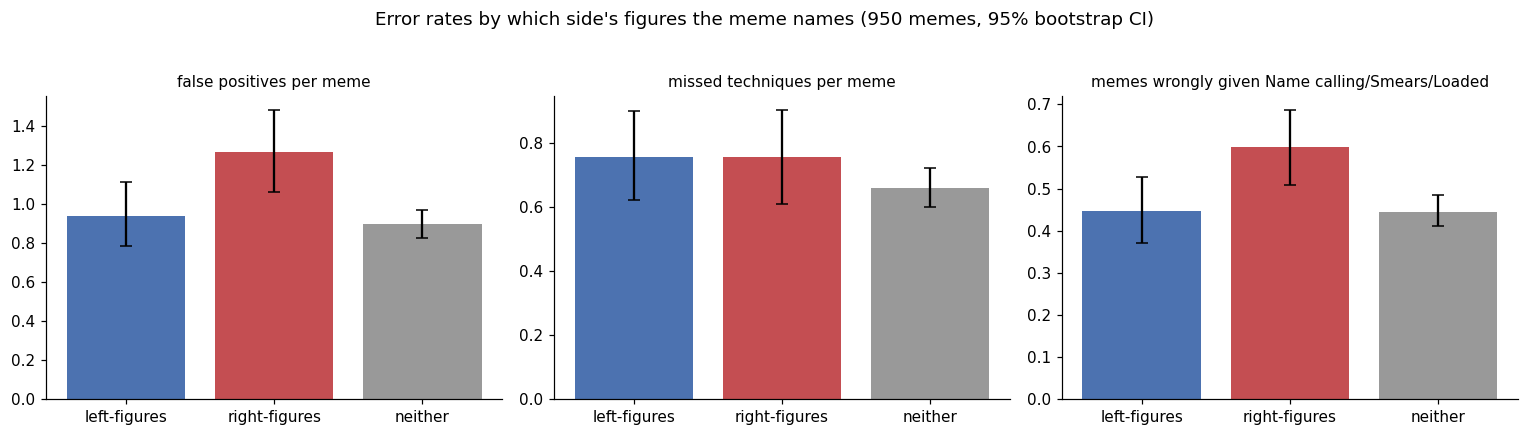

,memes,micro_f1,micro_p,micro_r,false positives / meme,false negatives / meme,spurious attack label (share of memes)
target,,,,,,,
left-figures,159,0.584235,0.559172,0.611650,0.937107,0.754717,0.446541
right-figures,102,0.567227,0.511364,0.636792,1.264706,0.754902,0.598039
neither,644,0.539098,0.503869,0.579624,0.895963,0.659938,0.445652


In [43]:
def bootstrap_rate(x, n_boot=1000, seed=SEED):
    rng = np.random.RandomState(seed); x = np.asarray(x, dtype=float)
    return np.percentile([x[rng.randint(0, len(x), len(x))].mean() for _ in range(n_boot)], [2.5, 97.5])


df_both["target"] = df_both.text.apply(political_target)
grp_rows = []
for g in ["left-figures", "right-figures", "neither"]:
    m = (df_both.target == g).values
    fp = ((L_both[m] == 1) & (Y_both[m] == 0)).sum(1); fn = ((L_both[m] == 0) & (Y_both[m] == 1)).sum(1)
    attack = [T2I[t] for t in ["Name calling/Labeling", "Smears", "Loaded Language"]]
    fp_attack = ((L_both[m][:, attack] == 1) & (Y_both[m][:, attack] == 0)).any(1)
    grp_rows.append({"target": g, "memes": int(m.sum()), **label_scores(Y_both[m], L_both[m]),
                     "false positives / meme": fp.mean(), "FP 95% CI": bootstrap_rate(fp),
                     "false negatives / meme": fn.mean(), "FN 95% CI": bootstrap_rate(fn),
                     "spurious attack label (share of memes)": fp_attack.mean(), "attack CI": bootstrap_rate(fp_attack)})
grp = pd.DataFrame(grp_rows).set_index("target")
fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))
for a, (col, ci, title) in zip(ax, [("false positives / meme", "FP 95% CI", "false positives per meme"),
                                    ("false negatives / meme", "FN 95% CI", "missed techniques per meme"),
                                    ("spurious attack label (share of memes)", "attack CI",
                                     "memes wrongly given Name calling/Smears/Loaded")]):
    v = grp[col].values; err = np.abs(np.stack(grp[ci].values).T - v)
    a.bar(grp.index, v, yerr=err, capsize=4, color=["#4C72B0", "#C44E52", "#999999"]); a.set_title(title, fontsize=10)
plt.suptitle("Error rates by which side's figures the meme names (950 memes, 95% bootstrap CI)", y=1.03)
plt.tight_layout(); plt.show()
display(grp[["memes", "micro_f1", "micro_p", "micro_r", "false positives / meme", "false negatives / meme",
             "spurious attack label (share of memes)"]].style.format("{:.3f}").format({"memes": "{:.0f}"}))

**Counterfactual swap.** Every meme that names a figure or party from the list below is rewritten with the
counterpart from the other side, preserving capitalisation. The swapped meme is scored by the same model as the
original (its out-of-fold model, or the ensemble for test memes). We measure:
* the **flip rate**: how often the displayed label set changes;
* the **mean change in probability** of each technique, separately for memes that originally named left-wing
  figures (now naming right-wing ones) and the reverse.

A model that treats sides the same has flip rates near zero and mean changes centred on zero in both directions.
A model that associates attacks with one side shows changes of *opposite sign* in the two directions.

memes containing a swappable name: 285 | label set changed after the swap: 87 (30.5%, 95% CI [25.3 35.8])
example: TRUMP → BIDEN


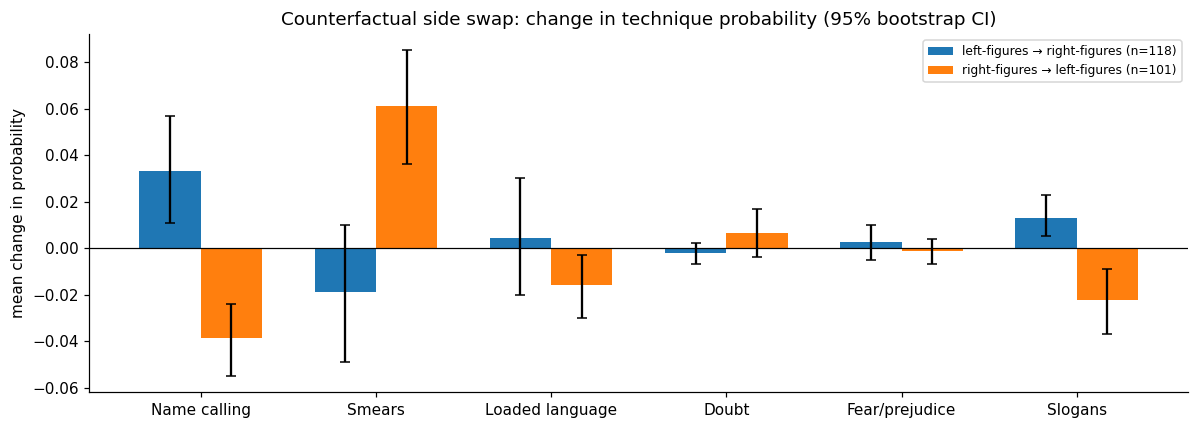

,original target → swapped,technique,n,mean Δp,95% CI,Wilcoxon p,label flips
0,left-figures → right-figures,Name calling,118,+0.033,[0.011 0.057],0.010,9
1,left-figures → right-figures,Smears,118,-0.019,[-0.049 0.01 ],0.008,13
2,left-figures → right-figures,Loaded language,118,+0.004,[-0.02 0.03],0.820,5
3,left-figures → right-figures,Doubt,118,-0.002,[-0.007 0.002],0.147,1
4,left-figures → right-figures,Fear/prejudice,118,+0.003,[-0.005 0.01 ],0.118,3
5,left-figures → right-figures,Slogans,118,+0.013,[0.005 0.023],0.001,4
6,right-figures → left-figures,Name calling,101,-0.039,[-0.055 -0.024],0.000,8
7,right-figures → left-figures,Smears,101,+0.061,[0.036 0.085],0.000,7
8,right-figures → left-figures,Loaded language,101,-0.016,[-0.03 -0.003],0.001,6
9,right-figures → left-figures,Doubt,101,+0.007,[-0.004 0.017],0.000,4


In [44]:
SWAP_PAIRS = [("trump", "biden"), ("donald", "joe"), ("republicans", "democrats"), ("republican", "democrat"),
              ("conservatives", "liberals"), ("conservative", "liberal"), ("gop", "dnc"), ("pence", "harris"),
              ("mcconnell", "pelosi"), ("right-wing", "left-wing"), ("right wing", "left wing"),
              ("melania", "jill"), ("ivanka", "hunter"), ("kamala", "mike"), ("obama", "bush")]
_swap_map = {**{a: b for a, b in SWAP_PAIRS}, **{b: a for a, b in SWAP_PAIRS}}
_swap_re = re.compile(r"\b(" + "|".join(sorted(map(re.escape, _swap_map), key=len, reverse=True)) + r")\b", re.I)


def match_case(src, word):
    return word.upper() if src.isupper() else word.title() if src[:1].isupper() else word


def fold_key(s):
    """Lower-case and strip accents: 'HARRİS'.lower() is 'harri̇s' (dotted capital I), which must still match."""
    import unicodedata
    return "".join(c for c in unicodedata.normalize("NFKD", s.lower()) if not unicodedata.combining(c))


def swap_sides(text):
    return _swap_re.sub(lambda m: match_case(m.group(0), _swap_map.get(fold_key(m.group(0)), m.group(0))), text)


swapped_dev = [swap_sides(t) for t in df_dev.text]; swapped_test = [swap_sides(t) for t in df_test.text]
P_sw, _, _ = oof_and_test_predict(swapped_dev, swapped_test)
changed = np.array([a != b for a, b in zip(list(df_dev.text) + list(df_test.text), swapped_dev + swapped_test)])
direction = df_both.target.values
L_sw = (P_sw >= LABEL_THR).astype(int)
flip = (L_sw != L_both).any(1)
print(f"memes containing a swappable name: {changed.sum()} | label set changed after the swap: {flip[changed].sum()} "
      f"({100 * flip[changed].mean():.1f}%, 95% CI {np.round(100 * bootstrap_rate(flip[changed]), 1)})")
_ex = min(np.where(changed)[0], key=lambda i: len(df_both.text[i]))
print("example:", df_both.text[_ex].replace("\n", " "), "→", (swapped_dev + swapped_test)[_ex].replace("\n", " "))

from scipy.stats import wilcoxon
focus = ["Name calling/Labeling", "Smears", "Loaded Language", "Doubt", "Appeal to fear/prejudice", "Slogans"]
rows = []
for d in ["left-figures", "right-figures"]:
    m = changed & (direction == d)
    for t in focus:
        delta = P_sw[m, T2I[t]] - P_both[m, T2I[t]]
        p = wilcoxon(delta).pvalue if np.any(delta != 0) else 1.0
        rows.append({"original target → swapped": f"{d} → {'right' if d.startswith('left') else 'left'}-figures",
                     "technique": SHORT[t], "n": int(m.sum()), "mean Δp": delta.mean(),
                     "95% CI": np.round(bootstrap_rate(delta), 3), "Wilcoxon p": p,
                     "label flips": int((L_sw[m, T2I[t]] != L_both[m, T2I[t]]).sum())})
cf = pd.DataFrame(rows)
fig, ax = plt.subplots(figsize=(11, 4))
for j, (d, g) in enumerate(cf.groupby("original target → swapped", sort=False)):
    x = np.arange(len(focus)) + (j - 0.5) * 0.35
    err = np.abs(np.stack(g["95% CI"].values).T - g["mean Δp"].values)
    ax.bar(x, g["mean Δp"], 0.35, yerr=err, capsize=3, label=f"{d} (n={g.n.iloc[0]})")
ax.axhline(0, color="black", lw=0.8); ax.set_xticks(np.arange(len(focus)), [SHORT[t] for t in focus])
ax.set_ylabel("mean change in probability"); ax.legend(fontsize=8)
ax.set_title("Counterfactual side swap: change in technique probability (95% bootstrap CI)")
plt.tight_layout(); plt.show()
display(cf.style.format({"mean Δp": "{:+.3f}", "Wilcoxon p": "{:.3f}"}))

**Control: is it the side, or any name change?** A flip rate on its own cannot tell bias from general sensitivity
to names. So the same memes are rewritten a second time, with names and party words replaced by **another name
from the same side** (Trump→Pence, Biden→Obama, Republicans→GOP, liberals→leftists, …). If the side swap flips
labels clearly more often than the same-side swap, the extra flips are caused by the side.

In [45]:
CONTROL_PAIRS = [("trump", "pence"), ("mcconnell", "trump"), ("melania", "ivanka"), ("ivanka", "melania"),
                 ("republicans", "gop"), ("republican", "gop"), ("gop", "republicans"), ("conservatives", "right-wingers"),
                 ("conservative", "right-wing"), ("right-wing", "conservative"),
                 ("biden", "obama"), ("obama", "biden"), ("hillary", "pelosi"), ("pelosi", "hillary"), ("clinton", "pelosi"),
                 ("kamala", "hillary"), ("harris", "clinton"), ("bernie", "obama"), ("sanders", "obama"),
                 ("democrats", "dems"), ("democrat", "dem"), ("dems", "democrats"), ("liberals", "leftists"),
                 ("liberal", "leftist"), ("left-wing", "liberal"), ("jill", "michelle"), ("hunter", "chelsea")]
_ctrl_map = dict(CONTROL_PAIRS)
_ctrl_re = re.compile(r"\b(" + "|".join(sorted(map(re.escape, _ctrl_map), key=len, reverse=True)) + r")\b", re.I)
same_side = lambda t: _ctrl_re.sub(lambda m: match_case(m.group(0), _ctrl_map.get(fold_key(m.group(0)), m.group(0))), t)
ctrl_dev = [same_side(t) for t in df_dev.text]; ctrl_test = [same_side(t) for t in df_test.text]
P_ctrl, _, _ = oof_and_test_predict(ctrl_dev, ctrl_test)
L_ctrl = (P_ctrl >= LABEL_THR).astype(int)
both_changed = changed & np.array([a != b for a, b in zip(list(df_dev.text) + list(df_test.text), ctrl_dev + ctrl_test)])
flip_ctrl = (L_ctrl != L_both).any(1)
attack = [T2I[t] for t in ["Name calling/Labeling", "Smears"]]
ctl = pd.DataFrame({
    "rewrite": ["side swap (other side)", "control (same side)"],
    "memes": [int(both_changed.sum())] * 2,
    "label set changed": [flip[both_changed].mean(), flip_ctrl[both_changed].mean()],
    "95% CI": [np.round(bootstrap_rate(flip[both_changed]), 3), np.round(bootstrap_rate(flip_ctrl[both_changed]), 3)],
    "mean |Δp| Name calling + Smears": [np.abs(P_sw[both_changed][:, attack] - P_both[both_changed][:, attack]).mean(),
                                        np.abs(P_ctrl[both_changed][:, attack] - P_both[both_changed][:, attack]).mean()],
}).set_index("rewrite")
d_flip = flip[both_changed].astype(float) - flip_ctrl[both_changed].astype(float)
display(ctl.style.format({"label set changed": "{:.1%}", "mean |Δp| Name calling + Smears": "{:.3f}"}))
print(f"paired difference in flip rate (side − control): {d_flip.mean():+.3f}, 95% CI {np.round(bootstrap_rate(d_flip), 3)}")

,memes,label set changed,95% CI,mean |Δp| Name calling + Smears
rewrite,,,,
side swap (other side),266,32.0%,[0.267 0.376],0.072
control (same side),266,32.7%,[0.271 0.383],0.075


paired difference in flip rate (side − control): -0.008, 95% CI [-0.064  0.049]


**Neutral templates.** Sentences that contain no persuasion technique, filled with names of figures, parties and
social groups from both countries. Any probability the model assigns to a technique here comes from the name.

In [46]:
TEMPLATES = ["{X} held a press conference today.", "{X} will announce the new budget on Tuesday.",
             "A spokesperson for {X} said the meeting was productive.", "This is a photo of {X}."]
GROUPS = {"US left": ["Joe Biden", "the Democrats", "Kamala Harris"], "US right": ["Donald Trump", "the Republicans", "Mike Pence"],
          "AU left": ["Anthony Albanese", "the Labor Party", "the Greens"],
          "AU right": ["Sussan Ley", "the Liberal Party", "Pauline Hanson"],
          "social groups": ["Muslims", "Christians", "immigrants", "women", "teenagers", "farmers"],
          "control": ["the weather bureau", "the local library", "my neighbour"]}
tmpl_rows = []
for g, names in GROUPS.items():
    for nm in names:
        texts = [t.format(X=nm) for t in TEMPLATES]
        p = ensemble_predict(pd.DataFrame({"text": texts, "spans": [[] for _ in texts], "y": [np.zeros(K, np.float32)] * len(texts)}))
        tmpl_rows.append({"group": g, "name": nm, "mean P(any technique)": (1 - np.prod(1 - p["label_p"], 1)).mean(),
                          "max P(Name calling)": p["label_p"][:, T2I["Name calling/Labeling"]].max(),
                          "max P(Smears)": p["label_p"][:, T2I["Smears"]].max(),
                          "any label shown": int(p["labels"].any(1).sum())})
tmpl = pd.DataFrame(tmpl_rows)
display(tmpl.style.format({c: "{:.3f}" for c in ["mean P(any technique)", "max P(Name calling)", "max P(Smears)"]})
        .background_gradient(subset=["mean P(any technique)"], cmap="Reds").set_caption(
        f"Neutral templates ({len(TEMPLATES)} per name): should be ≈0 everywhere"))

,group,name,mean P(any technique),max P(Name calling),max P(Smears),any label shown
0,US left,Joe Biden,0.377,0.028,0.639,2
1,US left,the Democrats,0.221,0.010,0.415,1
2,US left,Kamala Harris,0.452,0.025,0.671,2
3,US right,Donald Trump,0.298,0.027,0.592,1
4,US right,the Republicans,0.194,0.017,0.369,1
5,US right,Mike Pence,0.352,0.032,0.590,2
6,AU left,Anthony Albanese,0.365,0.026,0.582,2
7,AU left,the Labor Party,0.251,0.011,0.409,1
8,AU left,the Greens,0.232,0.075,0.300,1
9,AU right,Sussan Ley,0.464,0.025,0.661,3


**C1 conclusion.**
1. **The labels themselves are not symmetric.** In the gold data, memes naming left-wing figures carry Smears more
   often (0.50 vs. 0.39), memes naming right-wing figures more often Glittering generalities (0.15 vs. 0.03). We cannot
   tell whether this reflects the memes or the annotators' reading; a model trained on it can only inherit it.
2. **Group error rates:** memes naming right-wing figures receive more false-positive labels (1.26 per meme vs. 0.94
   left and 0.90 neither) and more often a wrong "attack" label (60% vs. 45%). The confidence intervals barely
   overlap, but the groups also differ in content, so this alone does not prove bias.
3. **Counterfactual swap, the decisive test:** swapping the side changes the predicted label set for 32.0% of the
   266 memes. But swapping to a name of the **same** side changes it for 32.7%. The paired difference is −0.8 points
   (95% CI −6.4 to +4.9). **We find no evidence that the side itself changes the output**; with 266 paired memes the
   test could have detected a difference of about 6 points. Within that, the probabilities shift in a consistent
   direction: left-wing names raise P(Smears) (+0.06, p < 0.001) and right-wing names raise P(Name calling)
   (+0.03 to +0.04). This mirrors the label asymmetry in point 1, at the level of a few percentage points.
4. **The real problem is a different one: the model is very sensitive to *names* in general.** One label set in three
   changes when any name is replaced. The neutral templates make this concrete: "{politician} held a press
   conference today" gets P(any technique) of 0.19–0.46, and a visible label in 1–3 of 4 sentences, for politicians of
   **both** countries and **both** sides. Social groups (Muslims, immigrants, women, …) stay low (0.13–0.17), below
   neutral controls like "the local library" (0.19–0.27).

**Is it fair enough for a room of teenagers?** It treats the sides alike within the precision our tests allow, but it
is **not stable enough to be legible**: a student who swaps a name in their meme will see the labels change one
time in three, and a harmless sentence that only names a politician can be flagged. In class this looks like bias
even when it is not. Mitigations before deployment: name-masking or name-swap augmentation in training, the C3
display rule (only agreed labels shown as findings), and teacher materials that explain uncertainty.

**Limits.** Political side is found with a keyword list (missing memes that attack a side without naming it). The
swap pairs are imperfect counterparts. Group sizes are 102–159. The templates are few and English-only.

### C2. Defend the system you built: zero-shot general-purpose LLMs on the same test memes

**Set-up** (responses collected outside this notebook with `c2_llm/run_llm.py`, embedded below, and parsed and
scored here):

| | Gemini 3.1 Pro | Gemini 3.1 Flash-Lite | Ornith-1.5-9B (Q4_K_M) |
|---|---|---|---|
| Role | strongest general model available to us: the committee's "general-purpose AI" | cheap hosted tier | **deployable alternative**: open weights, runs locally, fits a T4 (5.8 GB) |
| Access | grsai.ai, Gemini-native `generateContent` API | same | LM Studio on a laptop |
| Can it be used in schools? | **No.** Hosted API; the meme would leave the device | No | Yes |

* **Date:** 12–13 October 2026. Model names and versions are the `modelVersion` / `model` fields of each response.
* **Sampling:** temperature 1.0 for all models (the recommended default for Gemini 3; lower values are discouraged
  for this family). Because sampling is stochastic, the main prompt was run **three times** for Gemini Pro, Gemini
  Flash-Lite and Ornith without reasoning, and we report the spread. The names-only prompt for Pro ran once.
* **Thinking:** provider default for Gemini. Ornith ran twice: with its reasoning mode switched off
  (`reasoning_effort = none`, all 200 memes) and switched on (every 4th meme, 50 memes, because each answer takes
  about 3 minutes on local hardware). A configuration run on a subsample is scored on that subsample only, and our
  system is compared on the same memes.
* **Sample:** all **200 test memes** for every other configuration, so the comparison uses the identical memes and
  identical metrics as our system.

**Making it fair.**
* **Same information as the human annotators.** The prompt gives the 20 technique names with the paper's own
  definitions (prompt `def`). A second prompt with names only (`names`) measures how much the definitions matter.
* **Same output as our system.** The model returns techniques *and the exact words* for each, so both label F1
  and span F1 can be computed. Fragments are located in the meme text; if they are not verbatim, a fuzzy match is
  used.
* **Wrong-shaped answers.** Responses are parsed leniently (code fences and surrounding prose are tolerated).
  Technique names are mapped to the 20 labels by exact, alias, then fuzzy matching; names outside the taxonomy
  (e.g. "Transfer") are dropped and counted. A response that cannot be parsed, or a refusal, is reported and scored
  two ways: as "no techniques" (**strict**: what a deployed tool would show), and by excluding those memes for
  *both* systems (**lenient**).
* **Contamination.** The corpus has been public on GitHub since 2021, before these models' training cut-offs, so the
  memes may have been seen. We test **verbatim memorisation** directly: given the first half of a meme, the model
  is asked to continue it, and we compare its continuation with the real second half. As a control we compare it
  with the second half of a *different* meme.

The prompts are printed in full below.

In [47]:
# Raw responses of all LLM runs (gzip + base64 of JSON, generated from c2_llm/outputs/*.jsonl). One line, ~kB.
C2_RAW_B64 = "..."

In [48]:
import base64, gzip, difflib
C2_RAW = json.loads(gzip.decompress(base64.b64decode(C2_RAW_B64)).decode("utf8"))
C2_PROMPTS = C2_RAW["prompts"]
c2 = pd.DataFrame(C2_RAW["records"])
print("records:", len(c2), "| configurations:")
display(c2.groupby(["dataset", "task", "model", "prompt"]).agg(runs=("run", "nunique"), memes=("id", "nunique"),
        errors=("error", lambda e: e.notna().sum()), median_latency_s=("latency_s", "median")))
for k in ["system_def", "system_names", "user_template", "memo_system", "memo_user_template"]:
    print(f"\n===== {k} =====\n{C2_PROMPTS[k]}")

records: 3438 | configurations:


runs  memes  errors  \
dataset  task     model                        prompt                        
au_probe classify gemini-3.1-flash-lite        def        3     44       0   
                  gemini-3.1-pro               def        3     44       0   
                  ornith-1.5-9b-reasoning-none def        1     44       0   
test     classify gemini-3.1-flash-lite        def        3    200       0   
                                               names      3    200       0   
                  gemini-3.1-pro               def        3    200       0   
                                               names      1    200       0   
                  ornith-1.5-9b                def        1     50       0   
                  ornith-1.5-9b-reasoning-none def        3    200       0   
         memo     gemini-3.1-flash-lite        memo       1    160       0   
                  gemini-3.1-pro               memo       1    160       0   
                  ornith-1.5-9b-reasoning-none memo       1    160       0   

                                                       median_latency_s  
dataset  task     model                        prompt                    
au_probe classify gemini-3.1-flash-lite        def                3.830  
                  gemini-3.1-pro               def               14.510  
                  ornith-1.5-9b-reasoning-none def                9.485  
test     classify gemini-3.1-flash-lite        def                4.265  
                                               names              3.800  
                  gemini-3.1-pro               def               17.975  
                                               names             19.845  
                  ornith-1.5-9b                def              160.160  
                  ornith-1.5-9b-reasoning-none def                8.730  
         memo     gemini-3.1-flash-lite        memo               3.570  
                  gemini-3.1-pro               memo              53.730  
                  ornith-1.5-9b-reasoning-none memo              11.625


===== system_def =====
You annotate persuasion techniques in the text of internet memes, following the taxonomy of SemEval-2021 Task 6. The persuasion techniques are:
- Appeal to authority: Stating that a claim is true because a valid authority or expert on the issue said it was true, without any other supporting evidence offered. The special case in which the reference is not an authority or an expert (Testimonial) is also included.
- Appeal to fear/prejudice: Seeking to build support for an idea by instilling anxiety and/or panic in the population towards an alternative. In some cases, the support is built based on preconceived judgments.
- Black-and-white Fallacy/Dictatorship: Presenting two alternative options as the only possibilities, when in fact more possibilities exist. As an extreme case, telling the audience exactly what actions to take, eliminating any other possible choices (Dictatorship).
- Causal Oversimplification: Assuming a single cause or reason, when there are actu

In [49]:
_norm = lambda s: re.sub(r"[^a-z]+", " ", s.lower().replace("é", "e")).strip()
_ALIASES = {_norm(t): t for t in TECHNIQUES}
_ALIASES.update({_norm(a): t for a, t in [
    ("name calling", "Name calling/Labeling"), ("labeling", "Name calling/Labeling"), ("labelling", "Name calling/Labeling"),
    ("loaded language", "Loaded Language"), ("black and white fallacy", "Black-and-white Fallacy/Dictatorship"),
    ("dictatorship", "Black-and-white Fallacy/Dictatorship"), ("false dilemma", "Black-and-white Fallacy/Dictatorship"),
    ("straw man", "Misrepresentation of Someone's Position (Straw Man)"), ("strawman", "Misrepresentation of Someone's Position (Straw Man)"),
    ("red herring", "Presenting Irrelevant Data (Red Herring)"), ("glittering generalities", "Glittering generalities (Virtue)"),
    ("virtue", "Glittering generalities (Virtue)"), ("thought terminating cliche", "Thought-terminating cliché"),
    ("appeal to fear", "Appeal to fear/prejudice"), ("appeal to prejudice", "Appeal to fear/prejudice"),
    ("exaggeration", "Exaggeration/Minimisation"), ("minimisation", "Exaggeration/Minimisation"),
    ("minimization", "Exaggeration/Minimisation"), ("exaggeration minimization", "Exaggeration/Minimisation"),
    ("flag waving", "Flag-waving"), ("obfuscation", "Obfuscation, Intentional vagueness, Confusion"),
    ("intentional vagueness", "Obfuscation, Intentional vagueness, Confusion"), ("causal oversimplification", "Causal Oversimplification"),
    ("reductio ad hitlerum", "Reductio ad hitlerum"), ("appeal to authority", "Appeal to authority"),
    ("whataboutism", "Whataboutism"), ("bandwagon", "Bandwagon"), ("smears", "Smears"), ("smear", "Smears"),
    ("doubt", "Doubt"), ("slogans", "Slogans"), ("slogan", "Slogans"), ("repetition", "Repetition")]})


def map_technique(name):
    n = _norm(str(name))
    if n in _ALIASES:
        return _ALIASES[n]
    close = difflib.get_close_matches(n, list(_ALIASES), n=1, cutoff=0.8)
    return _ALIASES[close[0]] if close else None


def locate(fragment, text):
    if not fragment:
        return None
    for hay, needle in [(text, fragment), (text.lower(), fragment.lower())]:
        i = hay.find(needle)
        if i >= 0:
            return i, i + len(needle)
    sm = difflib.SequenceMatcher(None, text.lower(), fragment.lower(), autojunk=False)
    blocks = [b for b in sm.get_matching_blocks() if b.size > 0]
    if blocks and sum(b.size for b in blocks) >= 0.8 * len(fragment):
        return blocks[0].a, blocks[-1].a + blocks[-1].size
    return None


def parse_response(text, meme_text):
    """→ status, label vector, spans, n_unmapped, n_unlocated"""
    y = np.zeros(K, dtype=int)
    if not isinstance(text, str) or not text.strip():
        return "empty/refused", y, [], 0, 0
    m = re.search(r"```(?:json)?\s*(\{.*?\})\s*```", text, re.S) or re.search(r"(\{.*\})", text, re.S)
    if not m:
        return "no JSON", y, [], 0, 0
    try:
        obj = json.loads(m.group(1))
        items = obj["techniques"]
        assert isinstance(items, list)
    except Exception:
        return "malformed JSON", y, [], 0, 0
    spans, unmapped, unlocated = [], 0, 0
    for it in items:
        if not isinstance(it, dict):
            unmapped += 1; continue
        t = map_technique(it.get("technique", ""))
        if t is None:
            unmapped += 1; continue
        y[T2I[t]] = 1
        loc = locate(str(it.get("fragment", "")), meme_text)
        if loc is None:
            unlocated += 1
        else:
            spans.append((loc[0], loc[1], t))
    return "ok", y, spans, unmapped, unlocated


test_text = dict(zip(df_test.id, df_test.text)); test_pos = {i: n for n, i in enumerate(df_test.id)}
cls = c2[(c2.task == "classify") & (c2.dataset == "test") & c2.id.isin(test_text)].copy()
cls = cls.sort_values("timestamp_utc").groupby(["model", "prompt", "run", "id"]).tail(1)  # last attempt per meme
parsed = cls.apply(lambda r: parse_response(r.text if r.error is None or pd.isna(r.error) else None, test_text[r.id]), axis=1)
cls["status"], cls["y"], cls["spans"], cls["unmapped"], cls["unlocated"] = zip(*parsed)
status_tab = cls.groupby(["model", "prompt", "run"]).agg(
    ok=("status", lambda s: (s == "ok").sum()), failed=("status", lambda s: (s != "ok").sum()),
    unmapped_names=("unmapped", "sum"), fragments_not_found=("unlocated", "sum"))
display(status_tab.style.set_caption("Response shape: how many answers could be used?"))

In [50]:
def score_config(g, lenient):
    """Strict: every meme the model was asked about counts, failed answers as 'no technique'.
    Lenient: only memes with a usable answer. A configuration run on a subsample is scored on that subsample."""
    g = g.set_index("id").reindex(df_test.id)
    asked = g.status.notna().values
    ok = (g.status == "ok").values
    Yp = np.stack([y if isinstance(y, np.ndarray) else np.zeros(K, int) for y in g.y])
    sp = [s if isinstance(s, list) else [] for s in g.spans]
    keep = ok if lenient else asked
    return {**label_scores(Y_test[keep], Yp[keep]),
            **span_scores([gold_test[i] for i in np.where(keep)[0]], [sp[i] for i in np.where(keep)[0]]),
            "memes": int(keep.sum())}, Yp, sp, keep


rows, PRED_LLM = [], {}
for (model, prompt, run), g in cls.groupby(["model", "prompt", "run"]):
    for lenient in (False, True):
        s, Yp, sp, keep = score_config(g, lenient)
        rows.append({"system": model, "prompt": prompt, "run": run, "scoring": "lenient" if lenient else "strict", **s})
        if not lenient:
            PRED_LLM[(model, prompt, run)] = (Yp, sp, keep)
        ours = {**label_scores(Y_test[keep], TEST["labels"][keep]),
                **span_scores([gold_test[i] for i in np.where(keep)[0]], [TEST["spans"][i] for i in np.where(keep)[0]])}
        rows.append({"system": "OURS (same memes)", "prompt": f"vs {model}/{prompt}", "run": run,
                     "scoring": "lenient" if lenient else "strict", **ours, "memes": int(keep.sum())})
c2_all = pd.DataFrame(rows)
c2_sum = (c2_all[c2_all.system != "OURS (same memes)"]
          .groupby(["system", "prompt", "scoring"])[["micro_f1", "macro_f1", "micro_p", "micro_r", "span_f1"]]
          .agg(lambda x: f"{x.mean():.3f} ± {x.std(ddof=1) if len(x) > 1 else 0:.3f}"))
ours_row = pd.DataFrame([{**label_scores(Y_test, TEST["labels"]), **span_scores(gold_test, TEST["spans"])}],
                        index=pd.MultiIndex.from_tuples([("OURS: final ensemble", "–", "–")], names=c2_sum.index.names))
display(pd.concat([ours_row.map(lambda v: f"{v:.3f}"), c2_sum]).style.set_caption(
    "200 test memes, mean ± sd over runs (strict: failed answers = no technique)"))

**Is the gap real?** We use a paired bootstrap over memes on run 1 of each LLM configuration: our micro-F1 minus
the LLM's, resampling the same memes for both systems.

In [51]:
def paired_gap(Yp_llm, n_boot=2000, seed=SEED):
    rng = np.random.RandomState(seed); d = []
    for _ in range(n_boot):
        i = rng.randint(0, len(Y_test), len(Y_test))
        d.append(f1_score(Y_test[i], TEST["labels"][i], average="micro", zero_division=0)
                 - f1_score(Y_test[i], Yp_llm[i], average="micro", zero_division=0))
    return np.mean(d), np.percentile(d, [2.5, 97.5])


def paired_gap_on(Yp, mask, n_boot=2000, seed=SEED):
    rng = np.random.RandomState(seed); d = []
    idx_all = np.where(mask)[0]
    for _ in range(n_boot):
        i = rng.choice(idx_all, len(idx_all))
        d.append(f1_score(Y_test[i], TEST["labels"][i], average="micro", zero_division=0)
                 - f1_score(Y_test[i], Yp[i], average="micro", zero_division=0))
    return np.mean(d), np.percentile(d, [2.5, 97.5])


gap_rows = []
for (model, prompt, run), (Yp, sp, keep) in PRED_LLM.items():
    if run == 1:
        m, ci = paired_gap_on(Yp, keep)
        gap_rows.append({"LLM": f"{model} / {prompt}", "memes": int(keep.sum()),
                         "ours − LLM (micro-F1)": m, "95% CI": np.round(ci, 3),
                         "LLM better?": "yes" if ci[1] < 0 else "no" if ci[0] > 0 else "not distinguishable"})
display(pd.DataFrame(gap_rows).style.format({"ours − LLM (micro-F1)": "{:+.3f}"}))

# agreement between repeated runs of the same LLM configuration (stability for a teacher re-uploading a meme)
stab = []
for (model, prompt), g in cls.groupby(["model", "prompt"]):
    runs = sorted(g.run.unique())
    if len(runs) > 1:
        Ys = [PRED_LLM[(model, prompt, r)][0] for r in runs]
        jac = [np.mean([(a & b).sum() / (a | b).sum() if (a | b).any() else 1.0 for a, b in zip(Ys[i], Ys[j])])
               for i, j in itertools.combinations(range(len(runs)), 2)]
        stab.append({"LLM": f"{model} / {prompt}", "runs": len(runs),
                     "mean pairwise Jaccard of label sets": np.mean(jac),
                     "memes with identical output in all runs": np.mean([all((Ys[0][n] == Y_[n]).all() for Y_ in Ys)
                                                                         for n in range(len(Y_test))])})
display(pd.DataFrame(stab).style.format("{:.2f}", subset=["mean pairwise Jaccard of label sets",
                                                          "memes with identical output in all runs"])
        .set_caption("Run-to-run stability (our system is deterministic: 1.00 by construction)"))

,LLM,memes,ours − LLM (micro-F1),95% CI,LLM better?
0,gemini-3.1-flash-lite / def,200,+0.094,[0.038 0.147],no
1,gemini-3.1-flash-lite / names,200,+0.137,[0.078 0.193],no
2,gemini-3.1-pro / def,200,-0.056,[-0.107 -0.002],yes
3,gemini-3.1-pro / names,200,-0.023,[-0.076 0.033],not distinguishable
4,ornith-1.5-9b / def,50,+0.180,[0.041 0.325],no
5,ornith-1.5-9b-reasoning-none / def,200,+0.334,[0.278 0.39 ],no


,LLM,runs,mean pairwise Jaccard of label sets,memes with identical output in all runs
0,gemini-3.1-flash-lite / def,3,0.70,0.41
1,gemini-3.1-flash-lite / names,3,0.71,0.47
2,gemini-3.1-pro / def,3,0.82,0.45
3,ornith-1.5-9b-reasoning-none / def,3,0.27,0.02


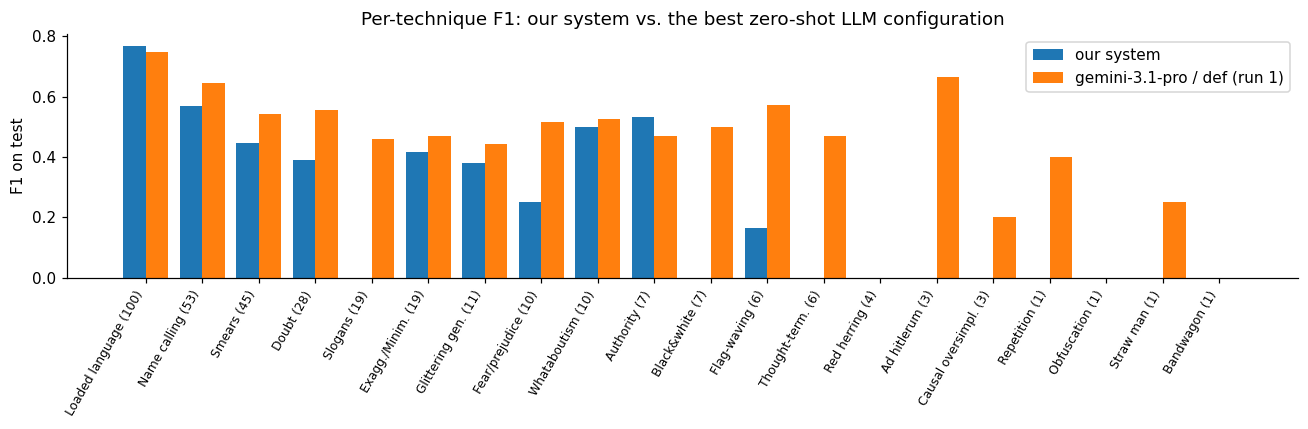

average number of techniques per meme: {'gold': 1.67, 'ours': 1.98, 'gemini-3.1-flash-lite/def': 1.32, 'gemini-3.1-flash-lite/names': 1.1, 'gemini-3.1-pro/def': 2.08, 'gemini-3.1-pro/names': 2.04, 'ornith-1.5-9b/def': 1.34, 'ornith-1.5-9b-reasoning-none/def': 1.53}


In [52]:
full = [k for k in PRED_LLM if k[2] == 1 and PRED_LLM[k][2].all()]
best_llm = max(full, key=lambda k: f1_score(Y_test, PRED_LLM[k][0], average="micro", zero_division=0))
f_ours = f1_score(Y_test, TEST["labels"], average=None, zero_division=0, labels=range(K))
f_llm = f1_score(Y_test, PRED_LLM[best_llm][0], average=None, zero_division=0, labels=range(K))
order_t = np.argsort(-Y_test.sum(0))
fig, ax = plt.subplots(figsize=(12, 4))
x = np.arange(K)
ax.bar(x - 0.2, f_ours[order_t], 0.4, label="our system"); ax.bar(x + 0.2, f_llm[order_t], 0.4, label=f"{best_llm[0]} / {best_llm[1]} (run 1)")
ax.set_xticks(x, [f"{SHORT[TECHNIQUES[i]]} ({int(Y_test[:, i].sum())})" for i in order_t], rotation=60, ha="right", fontsize=8)
ax.set_ylabel("F1 on test"); ax.legend(); ax.set_title("Per-technique F1: our system vs. the best zero-shot LLM configuration")
plt.tight_layout(); plt.show()
n_pred = pd.Series({"gold": Y_test.sum(1).mean(), "ours": TEST["labels"].sum(1).mean(),
                    **{f"{k[0]}/{k[1]}": v[0][v[2]].sum(1).mean() for k, v in PRED_LLM.items() if k[2] == 1}})
print("average number of techniques per meme:", n_pred.round(2).to_dict())

**Contamination probe (verbatim memorisation).** For each test meme of at least 8 words, the model received the
first half and was asked to continue it. We report the share of the true second half recovered (longest common
word sequence / length of the second half). As a control we compare the same continuation with the second half of
a *different*, randomly paired meme.

In [53]:
memo = c2[(c2.task == "memo") & (c2.dataset == "test") & c2.id.isin(test_text)].sort_values("timestamp_utc").groupby(["model", "id"]).tail(1)


def lcs_words(a, b):
    a, b = a.lower().split(), b.lower().split()
    if not a or not b:
        return 0
    m = difflib.SequenceMatcher(None, a, b, autojunk=False).find_longest_match(0, len(a), 0, len(b))
    return m.size


second_half = {i: " ".join(t.split()[len(t.split()) // 2:]) for i, t in test_text.items()}
rng_m = np.random.RandomState(SEED)
memo_rows = []
for model, g in memo.groupby("model"):
    ids = list(g.id); perm = rng_m.permutation(ids)
    for (i, txt), j in zip(zip(g.id, g.text.fillna("")), perm):
        true, other = second_half[i], second_half[j]
        memo_rows.append({"model": model, "id": i, "recovered (true half)": lcs_words(txt, true) / max(len(true.split()), 1),
                          "recovered (other meme, control)": lcs_words(txt, other) / max(len(other.split()), 1)})
memo_df = pd.DataFrame(memo_rows)
memo_tab = memo_df.groupby("model").agg(memes=("id", "size"), true_half=("recovered (true half)", "mean"),
                                        control=("recovered (other meme, control)", "mean"),
                                        verbatim_50pct=("recovered (true half)", lambda x: (x >= 0.5).mean()))
display(memo_tab.style.format("{:.3f}", subset=["true_half", "control", "verbatim_50pct"]).set_caption(
    "Memorisation probe: share of the unseen second half reproduced (verbatim_50pct = memes with ≥50% reproduced)"))

,memes,true_half,control,verbatim_50pct
model,,,,
gemini-3.1-flash-lite,160,0.112,0.030,0.044
gemini-3.1-pro,160,0.160,0.023,0.119
ornith-1.5-9b-reasoning-none,160,0.101,0.092,0.000


**Practical comparison.**

In [54]:
lat = c2[(c2.task == "classify") & (c2.dataset == "test")].groupby("model").latency_s.median()
display(pd.DataFrame({
    "median latency per meme (s)": {**lat.round(1).to_dict(), "OURS (5-model ensemble)": round(lat5[0] / 1000, 3)},
    "student text leaves the device": {**{m: ("no (local)" if "ornith" in m.lower() else "yes (hosted API)") for m in lat.index},
                                       "OURS (5-model ensemble)": "no"},
    "same input → same output": {**{m: "no (sampled)" for m in lat.index}, "OURS (5-model ensemble)": "yes"},
}))

,median latency per meme (s),student text leaves the device,same input → same output
gemini-3.1-flash-lite,4.000,yes (hosted API),no (sampled)
gemini-3.1-pro,18.300,yes (hosted API),no (sampled)
ornith-1.5-9b,160.200,no (local),no (sampled)
ornith-1.5-9b-reasoning-none,8.700,no (local),no (sampled)
OURS (5-model ensemble),0.142,no,yes


**C2 conclusion.**
* **The strongest general-purpose model is better than ours.** Gemini 3.1 Pro, zero-shot, scores micro-F1 0.574 ±
  0.007 over three runs and is significantly better on the same 200 memes (our −0.056, 95% CI −0.107 to −0.002). It
  is much better on rare techniques (macro-F1 0.44 vs. 0.22) and slightly better on spans (0.46 vs. 0.41). With
  the names-only prompt the gap is not significant. We report this as a finding, not a failure.
* **Contamination is plausible but limited.** Pro reproduces 16% of the unseen second halves of memes, against 2% for
  the control, and more than half of the text for 12% of memes, mostly well-known slogans and quotes. It has seen
  these meme texts or their sources, so its test score is likely somewhat optimistic. The labels themselves are not
  public in the same form, so this does not explain the whole advantage.
* **It cannot be deployed.** Every meme would leave the device to a hosted service, which the contract forbids. It is
  also not reproducible: only 45% of memes get the same labels in all three runs (mean Jaccard 0.82), and it takes
  18 s per meme.
* **The deployable alternative is far worse.** Ornith-1.5-9B runs locally on T4-class hardware but scores 0.20
  without reasoning (we are +0.33 better) and 0.35 with reasoning on 50 memes, at 160 s per meme, which is unusable
  while a class waits.
* **Cheap hosted models are worse than ours** (Flash-Lite 0.44, we are +0.09 better).

**Why the department should pay for this system:** among the options that satisfy the privacy constraint, it is the
most accurate by a wide margin, it answers in 0.14 s, and it gives the same answer every time. The honest caveat:
a frontier model is better at the task, so the best use of it is *offline*, on public memes only, for example to
pre-label Australian training data that our local model then learns from.

**Limits of the comparison.** One provider gateway (grsai.ai) whose exact model build we cannot verify beyond the
reported `modelVersion`; temperature 1.0 as recommended; one prompt family; strict and lenient scoring coincide
because every response could be parsed.

### C4. Will it work here? (Australia, 2026, a Year 10 feed)
There is no labelled Australian dataset. Instead we build evidence from three directions. Each answers a different
part of "what goes wrong in the gap":

| Gap | Evidence we can produce | Labels needed? |
|---|---|---|
| **Who and what** (US names, parties, institutions → Australian ones) | Replace US entities in the *test* memes with Australian counterparts. The rhetoric is unchanged, so the gold labels stay valid | no new labels |
| **How it is written** (case, slang, emoji, OCR noise of phone screenshots) | Controlled perturbations of the test memes, gold labels unchanged | no new labels |
| **What it is about** (2026 issues, teen feeds, non-political memes) | A small **probe set of 44 Australian-style memes**: 30 persuasive (12 aimed at each side + 6 non-partisan) and 14 everyday teen memes | written and labelled for this assignment (see the declaration) |
| **Language drift** | Out-of-vocabulary rate and sub-word fragmentation on the probe vs. the corpus | none |

The probe set is small, synthetic and labelled by a single annotator. It cannot estimate Australian accuracy
precisely. What it can show is *failure modes*: false alarms on harmless teen memes, side asymmetries, and
techniques the model never fires on.

In [55]:
AU_MAP = [("donald trump", "peter dutton"), ("trump", "dutton"), ("joe biden", "anthony albanese"), ("biden", "albanese"),
          ("obama", "rudd"), ("hillary clinton", "julia gillard"), ("hillary", "julia"), ("clinton", "gillard"),
          ("kamala harris", "penny wong"), ("kamala", "penny"), ("pelosi", "wong"), ("bernie sanders", "adam bandt"),
          ("bernie", "bandt"), ("mcconnell", "littleproud"), ("pence", "ley"), ("aoc", "the greens"),
          ("democrats", "labor"), ("democrat", "labor"), ("republicans", "liberals"), ("republican", "liberal"),
          ("gop", "coalition"), ("maga", "one nation"), ("congress", "parliament"), ("white house", "the lodge"),
          ("president", "prime minister"), ("america", "australia"), ("americans", "australians"),
          ("american", "australian"), ("usa", "australia"), ("u.s.", "australia"), ("fbi", "afp"), ("cnn", "the abc"),
          ("fox news", "sky news")]
_au_re = re.compile(r"(?<![\w.])(" + "|".join(sorted(map(re.escape, dict(AU_MAP)), key=len, reverse=True)) + r")(?![\w])", re.I)
_au = dict(AU_MAP)


def to_australia(text):
    return _au_re.sub(lambda m: match_case(m.group(0), _au.get(fold_key(m.group(0)), m.group(0))), text)


EMOJI = ["💀", "😭", "🤡", "🔥", "😂"]


def ocr_noise(text, rate=0.03, seed=SEED):
    r = np.random.RandomState(seed + len(text)); chars = list(text)
    sub = {"o": "0", "l": "1", "i": "l", "e": "c", "s": "5", "O": "0", "I": "l", "E": "F", "S": "5"}
    for i, c in enumerate(chars):
        if c in sub and r.rand() < rate * 3:
            chars[i] = sub[c]
    return "".join(chars)


PERTURB = {
    "original": lambda t: t,
    "US → AU entities": to_australia,
    "lower-case": str.lower,
    "sentence case": lambda t: t[:1].upper() + t[1:].lower(),
    "teen slang appended": lambda t: t.rstrip() + " fr fr no cap 💀",
    "emoji inserted": lambda t: " ".join(w + (f" {EMOJI[i % 5]}" if i % 4 == 3 else "") for i, w in enumerate(t.split(" "))),
    "OCR noise (~5% chars)": ocr_noise,
    "AU entities + lower-case": lambda t: to_australia(t).lower(),
}
changed_au = np.array([to_australia(t) != t for t in df_test.text])
pert_rows, pert_pred = [], {}
for nm, fn in PERTURB.items():
    r = ensemble_predict(df_test.assign(text=[fn(t) for t in df_test.text]))
    pert_pred[nm] = r["labels"]
    lo, hi = bootstrap_ci(lambda a, b: f1_score(a, b, average="micro", zero_division=0), Y_test, r["labels"])
    pert_rows.append({"perturbation": nm, "micro_f1": f1_score(Y_test, r["labels"], average="micro", zero_division=0),
                      "95% CI": f"[{lo:.3f}, {hi:.3f}]", "macro_f1": f1_score(Y_test, r["labels"], average="macro", zero_division=0),
                      "predicted techniques / meme": r["labels"].sum(1).mean(),
                      "memes whose labels changed": int((r["labels"] != TEST["labels"]).any(1).sum())})
pert = pd.DataFrame(pert_rows).set_index("perturbation")
display(pert.style.format({"micro_f1": "{:.3f}", "macro_f1": "{:.3f}", "predicted techniques / meme": "{:.2f}"})
        .set_caption(f"Test set (200 memes) under controlled shifts; gold labels unchanged. "
                     f"{changed_au.sum()} memes contain a US entity that was replaced."))
m = changed_au
print(f"on the {m.sum()} memes that actually changed under US→AU: micro-F1 {f1_score(Y_test[m], TEST['labels'][m], average='micro'):.3f}"
      f" → {f1_score(Y_test[m], pert_pred['US → AU entities'][m], average='micro'):.3f}")

,micro_f1,95% CI,macro_f1,predicted techniques / meme,memes whose labels changed
perturbation,,,,,
original,0.519,"[0.469, 0.565]",0.221,1.99,0
US → AU entities,0.523,"[0.472, 0.568]",0.205,1.90,37
lower-case,0.521,"[0.465, 0.569]",0.221,1.90,84
sentence case,0.541,"[0.486, 0.588]",0.227,1.90,78
teen slang appended,0.492,"[0.446, 0.538]",0.210,2.51,125
emoji inserted,0.494,"[0.441, 0.542]",0.192,2.19,99
OCR noise (~5% chars),0.500,"[0.451, 0.545]",0.226,2.15,81
AU entities + lower-case,0.519,"[0.466, 0.564]",0.220,1.81,93


on the 73 memes that actually changed under US→AU: micro-F1 0.531 → 0.541


**The Australian probe set.**

In [56]:
AU_PROBE_JSON = r"""[
  {"id": "au01", "side": "against-left", "text": "Labor: we'll fix the housing crisis\nAlso Labor: lets in half a million people a year",
   "labels": [{"technique": "Whataboutism", "fragment": "Labor: we'll fix the housing crisis\nAlso Labor: lets in half a million people a year"},
              {"technique": "Causal Oversimplification", "fragment": "Labor: we'll fix the housing crisis\nAlso Labor: lets in half a million people a year"}]},
  {"id": "au02", "side": "against-left", "text": "THE GREENS WANT TO BAN YOUR UTE, YOUR BBQ AND YOUR BEACH HOLIDAY",
   "labels": [{"technique": "Misrepresentation of Someone's Position (Straw Man)", "fragment": "THE GREENS WANT TO BAN YOUR UTE, YOUR BBQ AND YOUR BEACH HOLIDAY"},
              {"technique": "Exaggeration/Minimisation", "fragment": "BAN YOUR UTE, YOUR BBQ AND YOUR BEACH HOLIDAY"}]},
  {"id": "au03", "side": "against-left", "text": "CANBERRA LEFTIES KNOW BEST\n\nTHAT'S WHY YOUR RENT DOUBLED",
   "labels": [{"technique": "Name calling/Labeling", "fragment": "CANBERRA LEFTIES"},
              {"technique": "Causal Oversimplification", "fragment": "THAT'S WHY YOUR RENT DOUBLED"}]},
  {"id": "au04", "side": "against-left", "text": "Under-16 social media ban: because Albo thinks your parents can't raise you",
   "labels": [{"technique": "Misrepresentation of Someone's Position (Straw Man)", "fragment": "because Albo thinks your parents can't raise you"}]},
  {"id": "au05", "side": "against-left", "text": "WOKE LABOR IS DESTROYING AUSTRALIA",
   "labels": [{"technique": "Name calling/Labeling", "fragment": "WOKE LABOR"},
              {"technique": "Loaded Language", "fragment": "DESTROYING"}]},
  {"id": "au06", "side": "against-left", "text": "If you voted Labor, don't complain about your power bill",
   "labels": [{"technique": "Causal Oversimplification", "fragment": "If you voted Labor, don't complain about your power bill"}]},
  {"id": "au07", "side": "against-left", "text": "THEY CALL IT A 'TRANSITION'\nWE CALL IT A BLACKOUT",
   "labels": [{"technique": "Doubt", "fragment": "THEY CALL IT A 'TRANSITION'"},
              {"technique": "Appeal to fear/prejudice", "fragment": "WE CALL IT A BLACKOUT"}]},
  {"id": "au08", "side": "against-left", "text": "Real Aussies built this country. Canberra bureaucrats are selling it off.",
   "labels": [{"technique": "Flag-waving", "fragment": "Real Aussies built this country."},
              {"technique": "Name calling/Labeling", "fragment": "Canberra bureaucrats"},
              {"technique": "Smears", "fragment": "Canberra bureaucrats are selling it off."}]},
  {"id": "au09", "side": "against-left", "text": "THE GREENS: SOFT ON CRIME, HARD ON FARMERS",
   "labels": [{"technique": "Slogans", "fragment": "SOFT ON CRIME, HARD ON FARMERS"},
              {"technique": "Smears", "fragment": "THE GREENS: SOFT ON CRIME, HARD ON FARMERS"}]},
  {"id": "au10", "side": "against-left", "text": "Albanese couldn't run a sausage sizzle",
   "labels": [{"technique": "Smears", "fragment": "Albanese couldn't run a sausage sizzle"}]},
  {"id": "au11", "side": "against-left", "text": "Everyone's leaving Victoria for Queensland. Ask yourself why.",
   "labels": [{"technique": "Bandwagon", "fragment": "Everyone's leaving Victoria for Queensland."},
              {"technique": "Doubt", "fragment": "Ask yourself why."}]},
  {"id": "au12", "side": "against-left", "text": "Teal independents: Liberals for people who own a Tesla",
   "labels": [{"technique": "Name calling/Labeling", "fragment": "Liberals for people who own a Tesla"},
              {"technique": "Smears", "fragment": "Teal independents: Liberals for people who own a Tesla"}]},
  {"id": "au13", "side": "against-right", "text": "THE LIBS: 'NUCLEAR IS CHEAP'\nALSO THE LIBS: CAN'T BUILD A CARPARK ON TIME",
   "labels": [{"technique": "Doubt", "fragment": "THE LIBS: 'NUCLEAR IS CHEAP'\nALSO THE LIBS: CAN'T BUILD A CARPARK ON TIME"}]},
  {"id": "au14", "side": "against-right", "text": "Sussan Ley's plan for housing: inherit one",
   "labels": [{"technique": "Misrepresentation of Someone's Position (Straw Man)", "fragment": "Sussan Ley's plan for housing: inherit one"},
              {"technique": "Smears", "fragment": "Sussan Ley's plan for housing: inherit one"}]},
  {"id": "au15", "side": "against-right", "text": "DUTTON'S MATES WANTED NUCLEAR. AUSTRALIA SAID NO.",
   "labels": [{"technique": "Name calling/Labeling", "fragment": "DUTTON'S MATES"},
              {"technique": "Flag-waving", "fragment": "AUSTRALIA SAID NO."}]},
  {"id": "au16", "side": "against-right", "text": "The Coalition: fossil fuel puppets since 1996",
   "labels": [{"technique": "Name calling/Labeling", "fragment": "fossil fuel puppets"},
              {"technique": "Smears", "fragment": "The Coalition: fossil fuel puppets since 1996"}]},
  {"id": "au17", "side": "against-right", "text": "ONE NATION: BECAUSE THINKING IS TOO HARD",
   "labels": [{"technique": "Smears", "fragment": "ONE NATION: BECAUSE THINKING IS TOO HARD"}]},
  {"id": "au18", "side": "against-right", "text": "If you're not angry about climate change, you're not paying attention",
   "labels": [{"technique": "Black-and-white Fallacy/Dictatorship", "fragment": "If you're not angry about climate change, you're not paying attention"}]},
  {"id": "au19", "side": "against-right", "text": "Every scientist agrees. Only the Liberal Party doesn't.",
   "labels": [{"technique": "Appeal to authority", "fragment": "Every scientist agrees."},
              {"technique": "Smears", "fragment": "Only the Liberal Party doesn't."}]},
  {"id": "au20", "side": "against-right", "text": "Big Mining wrote the Liberal policy. Wake up, Australia.",
   "labels": [{"technique": "Smears", "fragment": "Big Mining wrote the Liberal policy."},
              {"technique": "Slogans", "fragment": "Wake up, Australia."}]},
  {"id": "au21", "side": "against-right", "text": "Trump's tariffs. Ley's silence. Coincidence?",
   "labels": [{"technique": "Doubt", "fragment": "Trump's tariffs. Ley's silence. Coincidence?"}]},
  {"id": "au22", "side": "against-right", "text": "Libs cut Medicare. Libs cut TAFE. Libs cut, cut, cut.",
   "labels": [{"technique": "Repetition", "fragment": "cut, cut, cut"},
              {"technique": "Smears", "fragment": "Libs cut Medicare. Libs cut TAFE. Libs cut, cut, cut."}]},
  {"id": "au23", "side": "against-right", "text": "The Nats: protecting your right to breathe coal dust since forever",
   "labels": [{"technique": "Smears", "fragment": "The Nats: protecting your right to breathe coal dust since forever"},
              {"technique": "Exaggeration/Minimisation", "fragment": "since forever"}]},
  {"id": "au24", "side": "against-right", "text": "Billionaires don't pay tax. You do. Vote Greens.",
   "labels": [{"technique": "Black-and-white Fallacy/Dictatorship", "fragment": "Vote Greens."},
              {"technique": "Slogans", "fragment": "Billionaires don't pay tax. You do."}]},
  {"id": "au25", "side": "non-partisan", "text": "VAPES KILL. NO EXCUSES. NO SECOND CHANCES.",
   "labels": [{"technique": "Slogans", "fragment": "VAPES KILL."},
              {"technique": "Appeal to fear/prejudice", "fragment": "VAPES KILL."},
              {"technique": "Thought-terminating cliché", "fragment": "NO EXCUSES. NO SECOND CHANCES."}]},
  {"id": "au26", "side": "non-partisan", "text": "Social media ban for teens? Next they'll ban your thoughts.",
   "labels": [{"technique": "Appeal to fear/prejudice", "fragment": "Next they'll ban your thoughts."},
              {"technique": "Exaggeration/Minimisation", "fragment": "Next they'll ban your thoughts."}]},
  {"id": "au27", "side": "non-partisan", "text": "Proud to be Australian. If you don't like it, leave.",
   "labels": [{"technique": "Flag-waving", "fragment": "Proud to be Australian."},
              {"technique": "Black-and-white Fallacy/Dictatorship", "fragment": "If you don't like it, leave."}]},
  {"id": "au28", "side": "non-partisan", "text": "It is what it is. Houses will never be affordable again.",
   "labels": [{"technique": "Thought-terminating cliché", "fragment": "It is what it is."},
              {"technique": "Exaggeration/Minimisation", "fragment": "Houses will never be affordable again."}]},
  {"id": "au29", "side": "non-partisan", "text": "Doctors recommend: stop doomscrolling after 10pm",
   "labels": [{"technique": "Appeal to authority", "fragment": "Doctors recommend"}]},
  {"id": "au30", "side": "non-partisan", "text": "Every Year 10 kid already has a vape. Don't be the last one.",
   "labels": [{"technique": "Bandwagon", "fragment": "Every Year 10 kid already has a vape. Don't be the last one."}]},
  {"id": "au31", "side": "benign", "text": "When the teacher says 'this won't be on the test' and it's the whole test", "labels": []},
  {"id": "au32", "side": "benign", "text": "me at 2am: one more game\nme at 7am: why am I like this", "labels": []},
  {"id": "au33", "side": "benign", "text": "POV: you forgot your PE uniform again", "labels": []},
  {"id": "au34", "side": "benign", "text": "Mum: we have Maccas at home\nMaccas at home: two-minute noodles", "labels": []},
  {"id": "au35", "side": "benign", "text": "When the bell rings but the teacher says 'the bell doesn't dismiss you'", "labels": []},
  {"id": "au36", "side": "benign", "text": "Nobody:\nAbsolutely nobody:\nMagpies in September:", "labels": []},
  {"id": "au37", "side": "benign", "text": "My group project partner after doing nothing: 'we did great guys'", "labels": []},
  {"id": "au38", "side": "benign", "text": "Footy season is over. What do I even do on weekends now", "labels": []},
  {"id": "au39", "side": "benign", "text": "Trying to explain Fortnite to my nan", "labels": []},
  {"id": "au40", "side": "benign", "text": "When the wifi drops in the middle of a ranked match", "labels": []},
  {"id": "au41", "side": "benign", "text": "Me pretending I read the book for English class", "labels": []},
  {"id": "au42", "side": "benign", "text": "Summer in Australia: 42 degrees and the aircon is broken", "labels": []},
  {"id": "au43", "side": "benign", "text": "When you find $5 in your old school jumper", "labels": []},
  {"id": "au44", "side": "benign", "text": "The canteen ran out of sausage rolls. Worst day of my life.",
   "labels": [{"technique": "Exaggeration/Minimisation", "fragment": "Worst day of my life."}]}
]"""
AU_PROBE = json.loads(AU_PROBE_JSON)
probe_rows = []
for p in AU_PROBE:
    spans = []
    for l in p["labels"]:
        s = p["text"].find(l["fragment"]); assert s >= 0, (p["id"], l["fragment"])
        spans.append((s, s + len(l["fragment"]), l["technique"]))
    y = np.zeros(K, np.float32)
    for _, _, t in spans:
        y[T2I[t]] = 1
    probe_rows.append({"id": p["id"], "side": p["side"], "text": p["text"], "spans": spans, "y": y})
df_probe = pd.DataFrame(probe_rows)
PR = ensemble_predict(df_probe)
Y_probe = np.stack(df_probe.y)
pers = (df_probe.side != "benign").values
rows = []
for nm, mask in [("persuasive (30)", pers), ("aimed at left (12)", (df_probe.side == "against-left").values),
                 ("aimed at right (12)", (df_probe.side == "against-right").values),
                 ("non-partisan (6)", (df_probe.side == "non-partisan").values), ("everyday teen memes (14)", ~pers)]:
    rows.append({"subset": nm, **label_scores(Y_probe[mask], PR["labels"][mask]),
                 **span_scores([df_probe.spans[i] for i in np.where(mask)[0]], [PR["spans"][i] for i in np.where(mask)[0]]),
                 "memes with any label shown": f"{int(PR['labels'][mask].any(1).sum())}/{int(mask.sum())}",
                 "gold memes with a technique": f"{int(Y_probe[mask].any(1).sum())}/{int(mask.sum())}"})
display(pd.DataFrame(rows).set_index("subset").style.format("{:.3f}", subset=["micro_f1", "macro_f1", "micro_p", "micro_r", "span_f1"])
        .set_caption("Australian probe set (author-written, single annotator)"))
display(df_probe.assign(gold=[fmt_labels(y) for y in Y_probe], predicted=[fmt_labels(y) for y in PR["labels"]],
                        top_prob=PR["label_p"].max(1).round(2))[["side", "text", "gold", "predicted", "top_prob"]])

,micro_f1,macro_f1,micro_p,micro_r,span_f1,span_p,span_r,memes with any label shown,gold memes with a technique
subset,,,,,,,,,
persuasive (30),0.275,0.158,0.286,0.264,0.229,0.327381,0.176664,25/30,30/30
aimed at left (12),0.273,0.106,0.273,0.273,0.266,0.310345,0.232039,10/12,12/12
aimed at right (12),0.372,0.155,0.348,0.400,0.288,0.443452,0.212916,11/12,12/12
non-partisan (6),0.000,0.000,0.000,0.000,0.000,0.000000,0.000000,4/6,6/6
everyday teen memes (14),0.154,0.050,0.083,1.000,0.286,0.285714,0.285714,8/14,1/14


,side,text,gold,predicted,top_prob
0,against-left,Labor: we'll fix the housing crisis\nAlso Labor: lets in half a million people a year,"Causal oversimpl., Whataboutism","Loaded language, Smears",0.81
1,against-left,"THE GREENS WANT TO BAN YOUR UTE, YOUR BBQ AND YOUR BEACH HOLIDAY","Exagg./Minim., Straw man",Loaded language,0.97
2,against-left,CANBERRA LEFTIES KNOW BEST\n\nTHAT'S WHY YOUR RENT DOUBLED,"Causal oversimpl., Name calling",Loaded language,0.43
3,against-left,Under-16 social media ban: because Albo thinks your parents can't raise you,Straw man,"Loaded language, Name calling",0.97
4,against-left,WOKE LABOR IS DESTROYING AUSTRALIA,"Loaded language, Name calling","Fear/prejudice, Loaded language, Smears",0.98
5,against-left,"If you voted Labor, don't complain about your power bill",Causal oversimpl.,Loaded language,0.47
6,against-left,THEY CALL IT A 'TRANSITION'\nWE CALL IT A BLACKOUT,"Fear/prejudice, Doubt",Name calling,0.52
7,against-left,Real Aussies built this country. Canberra bureaucrats are selling it off.,"Flag-waving, Name calling, Smears","Fear/prejudice, Flag-waving, Loaded language, Slogans, Smears",0.96
8,against-left,"THE GREENS: SOFT ON CRIME, HARD ON FARMERS","Slogans, Smears","Loaded language, Name calling, Smears",0.93
9,against-left,Albanese couldn't run a sausage sizzle,Smears,—,0.29


**Language drift and confidence.** Two label-free signals that work on any new meme: how many of its words the
training corpus never contained, and how confident the model is. A model that is *confidently* wrong on new
material is the dangerous case for a classroom.

,words,OOV share (tokens),sub-word pieces per word
"SemEval test (2020, US)",3331,0.165,1.13
AU probe: persuasive,276,0.268,1.23
AU probe: everyday,146,0.260,1.12


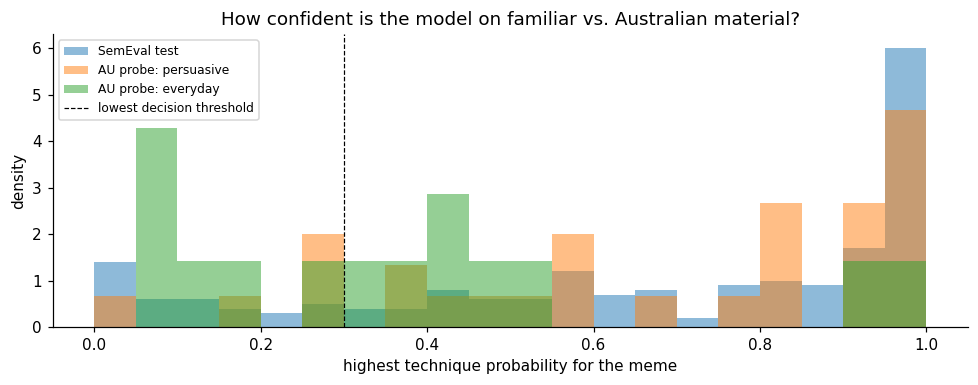

In [57]:
train_vocab = {w for t in df_dev.text for w in re.findall(r"[a-z']+", t.lower())}


def drift(texts):
    words = [w for t in texts for w in re.findall(r"[a-z']+", t.lower())]
    toks = sum(len(FINAL_TOK.tokenize(" " + w)) for w in words)
    return {"words": len(words), "OOV share (tokens)": np.mean([w not in train_vocab for w in words]),
            "sub-word pieces per word": toks / max(len(words), 1)}


display(pd.DataFrame({"SemEval test (2020, US)": drift(df_test.text), "AU probe: persuasive": drift(df_probe.text[pers]),
                      "AU probe: everyday": drift(df_probe.text[~pers])}).T.style.format(
    {"words": "{:.0f}", "OOV share (tokens)": "{:.3f}", "sub-word pieces per word": "{:.2f}"}))
fig, ax = plt.subplots(figsize=(9, 3.6))
for lbl, p in [("SemEval test", TEST["label_p"]), ("AU probe: persuasive", PR["label_p"][pers]), ("AU probe: everyday", PR["label_p"][~pers])]:
    ax.hist(p.max(1), bins=np.linspace(0, 1, 21), alpha=0.5, density=True, label=lbl)
ax.axvline(np.min(LABEL_THR), color="black", ls="--", lw=0.8, label="lowest decision threshold")
ax.set_xlabel("highest technique probability for the meme"); ax.set_ylabel("density"); ax.legend(fontsize=8)
ax.set_title("How confident is the model on familiar vs. Australian material?"); plt.tight_layout(); plt.show()

**Does a general LLM transfer better?** The same zero-shot prompts from C2 were run on the probe set. These models
were trained on far more recent and more Australian text than our 2020 corpus, so this shows how much of our gap is
about *knowledge of the world* rather than about the task.

In [58]:
probe_text = dict(zip(df_probe.id, df_probe.text)); probe_pos = {i: n for n, i in enumerate(df_probe.id)}
pc = c2[(c2.task == "classify") & (c2.dataset == "au_probe")].sort_values("timestamp_utc").groupby(["model", "prompt", "run", "id"]).tail(1)
rows = [{"system": "OURS", "run": "–", "persuasive micro_f1": f1_score(Y_probe[pers], PR["labels"][pers], average="micro", zero_division=0),
         "persuasive span_f1": span_scores([df_probe.spans[i] for i in np.where(pers)[0]], [PR["spans"][i] for i in np.where(pers)[0]])["span_f1"],
         "everyday memes flagged": f"{int(PR['labels'][~pers].any(1).sum())}/{int((~pers).sum())}"}]
for (model, prompt, run), g in pc.groupby(["model", "prompt", "run"]):
    Yp = np.zeros((len(df_probe), K), int); sp = [[] for _ in range(len(df_probe))]
    for _, r in g.iterrows():
        st, y, s, _, _ = parse_response(r.text if pd.isna(r.error) else None, probe_text[r.id])
        Yp[probe_pos[r.id]], sp[probe_pos[r.id]] = y, s
    rows.append({"system": f"{model} / {prompt}", "run": run,
                 "persuasive micro_f1": f1_score(Y_probe[pers], Yp[pers], average="micro", zero_division=0),
                 "persuasive span_f1": span_scores([df_probe.spans[i] for i in np.where(pers)[0]], [sp[i] for i in np.where(pers)[0]])["span_f1"],
                 "everyday memes flagged": f"{int(Yp[~pers].any(1).sum())}/{int((~pers).sum())}"})
display(pd.DataFrame(rows).style.format({"persuasive micro_f1": "{:.3f}", "persuasive span_f1": "{:.3f}"})
        .set_caption("Australian probe set: our system vs. zero-shot LLMs"))

,system,run,persuasive micro_f1,persuasive span_f1,everyday memes flagged
0,OURS,–,0.275,0.229,8/14
1,gemini-3.1-flash-lite / def,1,0.505,0.461,4/14
2,gemini-3.1-flash-lite / def,2,0.416,0.391,3/14
3,gemini-3.1-flash-lite / def,3,0.476,0.408,3/14
4,gemini-3.1-pro / def,1,0.746,0.701,1/14
5,gemini-3.1-pro / def,2,0.744,0.697,1/14
6,gemini-3.1-pro / def,3,0.748,0.678,1/14
7,ornith-1.5-9b-reasoning-none / def,1,0.294,0.262,6/14


**C4 conclusion: will it work here?**

| Gap | Evidence | Finding |
|---|---|---|
| US names and institutions → Australian ones | entity swap on 73 test memes, labels unchanged | no drop (0.531 → 0.541); the model reads the rhetoric, not the names |
| Writing style of a 2026 feed | lower-case, sentence case, slang, emoji, OCR noise | small drops (0.49–0.50 for slang, emoji, OCR), all inside the CI, but **more labels per meme** (2.5 instead of 2.0 with slang) |
| New topics and vocabulary | 30 persuasive Australian probe memes | micro-F1 falls to **0.28** (test: 0.52); 27% of words unseen in training (test: 17%) |
| Harmless teen memes | 14 everyday memes | **8 of 14 get a technique label**, often Loaded Language or Name calling ("Maccas at home", "group project partner") |
| Does a general LLM transfer better? | same probe set | Gemini Pro 0.75 and 1/14 false alarms; our model 0.28 and 8/14 |

**What goes wrong in the gap.** The model has learned what *2020 US political* persuasion looks like. In front of
new topics (housing, energy, the under-16 social-media ban) it falls back to the three frequent attack labels. In
front of ordinary teen humour it sees hostility that is not there. The model is also *confident* on Australian
material (the confidence histogram looks like the familiar test set), so a teacher cannot rely on low confidence to
spot these errors.

**What it means in the classroom.**
* **For the teacher:** the lesson must not assume the labels are right. The tool should frame every output as a
  question for the class, and the teacher needs a one-click "the tool is wrong here" button that is logged.
* **For a student whose family's politics appear on screen:** a label like *Smears* on a meme they shared from home
  can feel like a verdict on their family. The tool must label techniques, never sides or people. It should show the
  same technique on a meme from the other side whenever possible, and teachers need guidance for that moment.
* **Accountability:** the department should collect consented, de-identified Australian examples (teacher-chosen,
  not student uploads), label a few hundred with at least two annotators, and re-evaluate before every term. False
  alarms on non-political memes should be tracked as their own metric.

**Limits.** The probe set is small (44 memes), synthetic, written and labelled by one annotator with AI assistance.
It can reveal failure modes but cannot estimate Australian accuracy. The perturbations test style, not meaning.

## 7. Ultimate judgement

### 7.1 The evidence in one table
Every number below is computed earlier in this notebook. They are collected here so the judgement can be checked
against them.

In [59]:
card = pd.Series({
    "Final configuration": BEST,
    "Test micro-F1 (95% CI)": f"{test_tab.loc['final ensemble (5 models)', 'micro_f1']:.3f} {test_tab.loc['final ensemble (5 models)', 'micro_f1 95% CI']}",
    "Test macro-F1": f"{test_tab.loc['final ensemble (5 models)', 'macro_f1']:.3f}",
    "Test precision / recall (labels)": f"{test_tab.loc['final ensemble (5 models)', 'micro_p']:.3f} / {test_tab.loc['final ensemble (5 models)', 'micro_r']:.3f}",
    "Test span F1 (95% CI)": f"{test_tab.loc['final ensemble (5 models)', 'span_f1']:.3f} {test_tab.loc['final ensemble (5 models)', 'span_f1 95% CI']}",
    "SemEval-2021 best (labels / spans)": "0.593 / 0.482",
    "Majority baseline on test (labels)": f"{test_tab.loc['majority baseline', 'micro_f1']:.3f}",
    "Techniques with usable F1 (≥0.4) on test": ", ".join(pt.index[pt.F1 >= 0.4]),
    "Best zero-shot LLM (strict, run 1)": f"{best_llm[0]} / {best_llm[1]}: micro-F1 "
                                          f"{f1_score(Y_test, PRED_LLM[best_llm][0], average='micro', zero_division=0):.3f}",
    "Label/span heads disagree": f"{100 * (tot['label only'] + tot['span only']) / tot.sum():.1f}% of flagged pairs",
    "Counterfactual side swap: label sets changed": f"{100 * flip[changed].mean():.1f}% of {changed.sum()} memes",
    "Same-side control swap: label sets changed": f"{100 * flip_ctrl[both_changed].mean():.1f}% (side swap on the same memes: {100 * flip[both_changed].mean():.1f}%)",
    "Everyday AU teen memes wrongly flagged": f"{int(PR['labels'][~pers].any(1).sum())}/{int((~pers).sum())}",
    "AU probe persuasive micro-F1": f"{f1_score(Y_probe[pers], PR['labels'][pers], average='micro', zero_division=0):.3f}",
    "Latency per meme, 5-model ensemble (median)": f"{lat5[0]:.0f} ms on {torch.cuda.get_device_name(0) if DEVICE.type == 'cuda' else 'CPU'}",
}, name="value")
display(card.to_frame())

,value
Final configuration,E5 bce+pos_weight
Test micro-F1 (95% CI),"0.519 [0.469, 0.565]"
Test macro-F1,0.221
Test precision / recall (labels),0.479 / 0.567
Test span F1 (95% CI),"0.405 [0.357, 0.442]"
SemEval-2021 best (labels / spans),0.593 / 0.482
Majority baseline on test (labels),0.374
Techniques with usable F1 (≥0.4) on test,"Loaded language, Name calling, Smears, Exagg./Minim., Whataboutism, Authority"
"Best zero-shot LLM (strict, run 1)",gemini-3.1-pro / def: micro-F1 0.575
Label/span heads disagree,34.9% of flagged pairs


### 7.2 Judgement
**Recommendation: do not deploy this system as an autonomous technique detector next term. Deploy it, if at all,
as a teacher-led discussion aid for a few core techniques, with the C3 display rule, and plan a re-evaluation on
Australian data.**

**Why this model is the best available under the constraints.**
* It is the best of the configurations we tested on clean, paired cross-validation: DeBERTa-v3, fully fine-tuned,
  our label-wise attention head, joint label + span training, class-weighted loss, a five-fold ensemble.
* On the held-out test set it reaches micro-F1 0.52 and span F1 0.41: clearly above the baselines, below the 2021
  state of the art that used now-forbidden propaganda pretraining.
* It satisfies every constraint: it runs locally, answers in 0.14 s on a T4 using under 2 GB of weights, is
  deterministic, and uses no persuasion-trained checkpoint and no external data.
* Among systems that may legally run in a classroom, nothing we tested comes close: a local 9B LLM reaches 0.20.

**Why it is not ready to run unsupervised.**
1. **Few techniques work.** Only Loaded Language, Name calling, Smears, Whataboutism, Exaggeration and (on very few
   examples) Appeal to authority reach F1 ≥ 0.4. Twelve of the twenty techniques are almost never found.
2. **It over-accuses.** Precision is 0.48: about half of all shown labels are wrong. Missed subtle techniques turn
   into extra "attack" labels.
3. **It is sensitive to names.** One in three label sets change when a name is swapped, and neutral sentences about
   politicians can be flagged. We found no side-specific bias, but students will experience the instability as bias.
4. **It does not transfer.** On Australian-style memes accuracy roughly halves, and 8 of 14 harmless teen memes are
   flagged, while the model stays confident.
5. **A general model is better at the task** (Gemini Pro, 0.57 on test and 0.75 on the Australian probe set), but it
   is not allowed on student data.

**Realistic chance of success.** In a classroom where the teacher uses the output as a prompt ("the tool thinks
this is Name calling; which words would do that?"), the tool can work for the core techniques today. As a system
that names the techniques in a student's meme by itself, it would mislead students in a large share of cases.

**What would change this verdict.**
* Label 300–500 Australian memes (teacher-curated, public sources, at least two annotators) and fine-tune on them.
* Use the frontier LLM **offline on public memes only** to pre-label more Australian training data, then distil it
  into the local model. No student data would leave the device.
* Augment training with name masking and benign everyday memes to cut the name sensitivity and the false alarms.
* Re-run C1–C4 on that data before every term, and track teacher overrides as a live quality metric.

### 7.3 Limitations
* **Small, noisy data:** 750 development memes; duplicated texts carry different labels; inter-annotator agreement
  α ≈ 0.77. Rare techniques have 1–5 training examples.
* **Selection optimism:** cross-validation was used for every choice, so its 0.56 overstates the 0.52 found on test.
  The test set itself is only 200 memes (CI ±0.05).
* **Training budget:** validation label F1 was still rising slowly at epoch 15 in some folds.
* **Text only:** the image is ignored, although many techniques live in it (by design of the task).
* **Evaluation reach:** everything except C4 is measured on 2020 US/Canadian Facebook memes. The Australian evidence
  is synthetic and small. Political side is detected with keywords.
* **Reproducibility:** GPU kernels are not bit-deterministic. A re-run gives the same conclusions, but individual
  numbers can move by about the seed standard deviation (≈0.01).

## 8. Declarations

**Pretrained weights (downloaded, run locally).** `microsoft/deberta-v3-base`, `roberta-base` and
`cardiffnlp/twitter-roberta-base-2021-124m`. All three were pretrained with self-supervised objectives only (masked or
replaced-token prediction). None was trained on persuasion-, propaganda- or rhetoric-labelled data.

**Additional public data.** The Propaganda Techniques Corpus (SemEval-2020 Task 11; Da San Martino et al., 2020;
Zenodo record 3952415, CC-BY 4.0) was used in experiment E9 only. It contains news articles, not memes. No meme of
our corpus occurs in it (checked in E9), so it cannot contain the labels of our evaluation set. Whether it is part
of the final model is decided by E9 and printed there.

**Zero-shot comparison (C2).** Responses were collected outside the notebook with `c2_llm/run_llm.py` and are
embedded above.
- Gemini 3.1 Pro and Gemini 3.1 Flash-Lite, through the grsai.ai gateway (Gemini-native `generateContent` API). The
  version is recorded from the `modelVersion` field of each response.
- Ornith-1.5-9B (Q4_K_M GGUF), run locally in LM Studio, with and without its reasoning mode.
- Dates, temperature and full prompts are printed in Section 6. Only public test memes were sent to hosted models.
  No student data exists in this project.

**Australian probe set (C4).** The 44 probe memes were written for this assignment and labelled by a single
annotator, with the help of an AI assistant, and checked by the student. They are synthetic. They are used only to
look for failure modes, not to estimate accuracy.

**Use of AI assistance.** An AI coding assistant (Claude, Anthropic) helped to write code and draft text. All design
decisions, experiments and conclusions were reviewed by the student, who takes responsibility for them.

## 9. References
- Dimitrov, D. et al. (2021). SemEval-2021 Task 6: Detection of persuasion techniques in texts and images. *SemEval-2021*, 70–98.
- Da San Martino, G. et al. (2020). SemEval-2020 Task 11: Detection of propaganda techniques in news articles. *SemEval-2020*.
- He, P., Gao, J. and Chen, W. (2023). DeBERTaV3: Improving DeBERTa using ELECTRA-style pre-training with gradient-disentangled embedding sharing. *ICLR*.
- Liu, Y. et al. (2019). RoBERTa: A robustly optimized BERT pretraining approach. *arXiv:1907.11692*.
- Loureiro, D. et al. (2022). TimeLMs: Diachronic language models from Twitter. *ACL demo*.
- Hu, E. et al. (2022). LoRA: Low-rank adaptation of large language models. *ICLR*.
- Mullenbach, J. et al. (2018). Explainable prediction of medical codes from clinical text (CAML, label-wise attention). *NAACL*.
- Lin, T.-Y. et al. (2017). Focal loss for dense object detection. *ICCV*.
- Sechidis, K., Tsoumakas, G. and Vlahavas, I. (2011). On the stratification of multi-label data. *ECML PKDD*.
- Phang, J., Févry, T. and Bowman, S. (2018). Sentence encoders on STILTs: supplementary training on intermediate labeled-data tasks. *arXiv:1811.01088*.
- Mosbach, M., Andriushchenko, M. and Klakow, D. (2021). On the stability of fine-tuning BERT. *ICLR*.
- Sundararajan, M., Taly, A. and Yan, Q. (2017). Axiomatic attribution for deep networks (Integrated Gradients). *ICML*.
- Ribeiro, M. T. et al. (2020). Beyond accuracy: behavioral testing of NLP models with CheckList. *ACL*.
- Caruana, R. (1997). Multitask learning. *Machine Learning*, 28, 41–75.